# 객체탐지 파일별 2 · 객체인식 Day02

**한 줄 요약** · 우리 데이터로 SSD 학습 · 평가: 나누기 · Dataset · 증강 · 헤드 교체 · 스모크 · 학습 · 채점 · AP · 오류 분석 · A/B

- **원본** · `7. 딥러닝/06_객체인식/강의자료/객체인식_Day02.html` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/11_객체탐지` 객체탐지-2 (데이터 · 학습 · checkpoint · 비교) · 객체탐지-3 2 · 3장 (AP · 오류)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 정답이 있는 사진 안에서 train · val · test를 품종 층화로 나누고 겹침 · 비율을 확인한다
2. 탐지용 Dataset · collate_fn을 만들고 첫 batch를 assert와 그림으로 점검한다
3. 박스를 함께 바꾸는 증강과 분류 헤드 교체를 하고, 학습 전 스모크 테스트로 조용한 버그를 잡는다
4. lr 스케줄 · checkpoint · best 고르기를 설명하고 val 551장을 클래스별로 채점한다
5. AP · mAP와 평가 IoU 기준을 구분하고, 오류 분석과 한 가지만 바꾼 비교로 결과를 정직하게 보고한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **내 탐지 데이터를 처음 나눌 때** · 모집단 · 층화 · 겹침 (1장)
- **DataLoader에서 RuntimeError가 날 때** · collate_fn (2장)
- **사전학습 탐지 모델을 내 클래스로 바꿀 때** · 분류 헤드 교체 · 스모크 (4 · 5장)
- **결과를 mAP 하나로 보고하려 할 때** · 기준 · 분모 · AP50 vs 0.50~0.95 (7 · 8장)

## 학습 지도

<img src="images/pfo2_map.png" alt="Day02 학습 지도" width="763">

**예상 학습 시간** · 개념 3시간 + 실습 1시간 (GPU 학습 두 번 약 1시간 · 기록이 있으면 불러옴)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>실행 환경 · 원본 구성</td></tr>
<tr><td>1</td><td>나누기 · train · val · held-out test</td><td>정답이 있는 사진을 어떻게 세 묶음으로 나누는가?</td></tr>
<tr><td>2</td><td>Dataset · 첫 batch 점검</td><td>이름 목록을 모델이 먹는 묶음으로 어떻게 바꾸는가?</td></tr>
<tr><td>3</td><td>박스를 따라가는 증강</td><td>사진을 뒤집으면 박스는 어떻게 바꾸는가?</td></tr>
<tr><td>4</td><td>미션 헤드 · 91칸을 3칸으로</td><td>COCO 91칸 모델을 우리 3칸 모델로 어떻게 바꾸는가?</td></tr>
<tr><td>5</td><td>스모크 테스트</td><td>긴 학습 전에 1분 동안 무엇을 확인하는가?</td></tr>
<tr><td>6</td><td>학습 · 시간 · checkpoint</td><td>학습은 몇 epoch, 무엇을 저장하고 어떻게 다시 쓰는가?</td></tr>
<tr><td>7</td><td>예측 · 집계 · val 551장</td><td>어제의 8장 채점을 val 551장 전부로 하면?</td></tr>
<tr><td>8</td><td>AP · mAP · 어떤 mAP인가</td><td>점수 기준 전부를 숫자 하나로 묶으면, 그 숫자는 무엇을 말하는가?</td></tr>
<tr><td>9</td><td>오류 분석</td><td>남은 틀린 박스는 어떤 사진에서 나오는가?</td></tr>
<tr><td>10</td><td>하나만 바꾸기 · A/B</td><td>좌우 뒤집기를 켠 RUN_B가 나아졌다고 말할 수 있는가?</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>11</td><td>종합 실습</td><td>규칙대로 최종 모델을 고르고 test 551장으로 한 번 채점하면?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

원본은 Mac(MPS) · 미리 학습해 둔 10 epoch 기록 기준 → 이 노트북은 kagglehub 캐시 · CUDA(없으면 CPU) · 4 epoch를 직접 학습. **셀은 위에서부터 차례로**.

*항목 → 설정*

- **데이터** · Oxford-IIIT Pet (kagglehub 캐시 · 원본의 data/oxford_pet과 같은 파일)
- **모델** · SSD300 VGG16 (COCO) + 3칸 분류 헤드
- **장치 · seed** · CUDA (원본은 Mac MPS) · `torch.manual_seed(0)` · cudnn 고정
- **학습** · RUN_A · RUN_B 각 4 epoch (원본 10) · 결과는 `checkpoints_파일별2/` (GitHub에 안 올림)
- **원본 셀 수** · 281개 (코드 · 설명 · 그림 자리 포함)

**실행 흐름**

1. 도구 불러오기 · OpenMP · seed · 장치 · 한글 글꼴
2. kagglehub 캐시 경로 · 결과 폴더
3. 색 약속 · read_voc · load_image

In [1]:
# 라이브러리 · 경로 · 장치 (원본 셀 1 · 10 · Mac MPS → CUDA/CPU)
# 왜 · 원본의 Mac 전용 장치 · 경로 대신 어느 PC에서나 돌게 하기 위해
import json                         # 기록 파일
import math                         # 손실이 숫자인지
import os                           # 환경 변수
import time                         # 시간 재기
import xml.etree.ElementTree as ET  # XML 정답
from collections import Counter     # 개수 세기
from pathlib import Path            # 경로

# 왜 · 데이터 받기 · 그림 · 모델 도구를 한곳에서 확인하기 위해
import kagglehub                                # Oxford-IIIT Pet 캐시
import matplotlib.pyplot as plt                 # 그림
import numpy as np                              # AP 계산
import sklearn                                  # 나누기 (버전 기록)
import torch                                    # 텐서 · 학습
import torchvision                              # 탐지 모델
import torchvision.transforms.functional as TF  # PIL → 텐서
from matplotlib import patches                  # 박스 그리기
from PIL import Image                           # 사진 열기

# 왜 · torch와 numpy를 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # OpenMP 충돌 방지
torch.manual_seed(0)                                   # 난수 고정
torch.backends.cudnn.deterministic = True              # 같은 GPU · 같은 버전에서 매번 같은 값
torch.backends.cudnn.benchmark = False                 # 계산 방법 고정
plt.rcParams["font.family"] = "Malgun Gothic"          # 그림 속 한글
plt.rcParams["axes.unicode_minus"] = False             # 음수 기호

# 왜 · 데이터를 매번 내려받지 않고 캐시 경로를 다시 쓰기 위해
DATA = Path(kagglehub.dataset_download(  # 원본 data/oxford_pet과 같은 데이터
    "zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1"))
IMAGES = DATA / "images" / "images"                                    # 사진
ANN = DATA / "annotations" / "annotations"                             # 목록 · xmls
XMLS = ANN / "xmls"                                                    # 머리 박스 XML
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # 원본은 Mac mps
RUNS = Path("checkpoints_파일별2")  # 학습 결과 폴더 (노트북 옆 · GitHub에 안 올림)
RUNS.mkdir(exist_ok=True)                                              # 없으면 만들기
print("torch", torch.__version__.split("+")[0], "· torchvision",       # 버전 기록
      torchvision.__version__.split("+")[0], "· scikit-learn", sklearn.__version__)
print("계산 장치:", DEVICE.type)                                       # cuda 또는 cpu
for name in ("RUN_A", "RUN_B"):                                        # 미리 학습해 둔 결과가 있나
    print(f"이미 학습한 {name}:", (RUNS / name / "best.pt").exists())  # 있으면 6장에서 불러옴


# 도우미 (원본 셀 2 ~ 4)
# 왜 · 모든 그림에서 정답 · 예측을 같은 색 약속으로 구분하기 위해
GT_COLOR, PRED_COLOR = "#16a34a", "#2563eb"  # 정답 초록 · 예측 파랑


# 왜 · XML 정답 읽기를 한 함수로 묶어 모든 장에서 다시 쓰기 위해
def read_voc(xml_path):                     # XML → (boxes, names)
    root = ET.parse(xml_path).getroot()     # XML
    boxes, names = [], []                   # 박스 · 이름
    for obj in root.iter("object"):         # 물체마다
        bb = obj.find("bndbox")             # 박스 태그
        boxes.append([float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")])  # 실수 4개
        names.append(obj.findtext("name"))  # cat · dog
    return boxes, names                     # 같은 순서


# 왜 · 흑백 사진도 3채널로 맞춰 모델 입력 형식을 통일하기 위해
def load_image(stem):                                         # 이름 → RGB 사진
    return Image.open(IMAGES / f"{stem}.jpg").convert("RGB")  # 3채널

torch 2.11.0 · torchvision 0.26.0 · scikit-learn 1.9.0
계산 장치: cuda
이미 학습한 RUN_A: False
이미 학습한 RUN_B: False


**실행 흐름**

1. 박스 하나 그리기 · draw
2. 헤드 출력 모양 확인 head_shapes

In [ ]:
# 왜 · 박스 하나 그리는 코드를 그림 함수에서 다시 쓰기 위해
def _box(ax, b, color, ls="-", lw=3, text=None):                            # 박스 하나
    x1, y1, x2, y2 = [float(v) for v in b]                                  # 숫자로
    # 사각형
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, ls=ls, lw=lw))
    if text:                                                                # 이름표
        ax.text(x1 + 3, y1 + 3, text, color="white", fontsize=9, va="top",  # 왼쪽 위
                bbox=dict(fc=color, ec="none", pad=2))


# 왜 · 사진 위에 정답 · 예측 · 후보를 한 번에 그리기 위해
def draw(img, gt=None, pred=None, cand=None, labels=None, title=None, ax=None):  # 사진 + 박스
    if ax is None:                                                               # 칸이 없으면
        _, ax = plt.subplots(figsize=(6, 4.5))                                   # 새 그림
    ax.imshow(img)                                                               # 사진
    ax.axis("off")                                                               # 눈금 숨김

    def rows(b):  # 텐서 · 목록 → 목록
        # 없으면 빈 목록
        return [] if b is None else (b.tolist() if hasattr(b, "tolist") else list(b))

    for b in rows(cand):                                             # 후보 = 점선
        _box(ax, b, PRED_COLOR, ls="--", lw=1)                       # 가늘게
    for i, b in enumerate(rows(pred)):                               # 예측 = 실선
        _box(ax, b, PRED_COLOR, text=labels[i] if labels else None)  # 이름표
    for b in rows(gt):                                               # 정답 = 초록
        _box(ax, b, GT_COLOR, lw=4)                                  # 굵게
    if title:                                                        # 제목
        ax.set_title(title, fontsize=10)                             # 10pt
    return ax                                                        # 바깥에서 더 그림


# 왜 · 헤드를 바꿨는지 출력 모양으로 바로 확인하기 위해
def head_shapes(model, x):  # 사진 한 장 → (클래스 점수 모양, 위치 보정 모양)
    with torch.no_grad():                                                       # 모양만
        images, _ = model.transform([x])                                        # 300×300
        feats = list(model.backbone(images.tensors).values())                   # 특징 맵
        out = model.head(feats)                                                 # 헤드 출력
    return tuple(out["cls_logits"].shape), tuple(out["bbox_regression"].shape)  # 두 모양

### 원본 구성

- **D2-0 오늘 할 일** · 몸 박스 모델(COCO)을 얼굴 박스 모델로 · 환경 확인
- **D2-1 · D2-2** · 나누기 (train · val · held-out test) → Dataset · 첫 batch 점검
- **D2-3 · D2-4** · 박스를 따라가는 증강 → 미션 헤드 91칸을 3칸으로
- **D2-5 · D2-6** · 스모크 테스트 → 학습 · 시간 · checkpoint
- **D2-7 · D2-8** · val 551장 예측 · 집계 → AP · mAP
- **D2-9 · D2-10** · 오류 분석 → 하나만 바꾸기 (RUN_A vs RUN_B)
- **D2-11** · 고르고 · 한 번 채점하고 · 미션으로

**원본 힌트**

- 흐름: 나누기 → 묶기 · 증강 → 헤드 교체 → 스모크 → 학습 → 예측 · P/R → AP → 오류 → 하나 바꾸기 → test
- 결과 = 숫자 + split · 모델 · epoch · 점수 기준 · 평가 IoU · 분모

---
## 1. 나누기 · train · val · held-out test

> **이 장의 흐름**
>
> - Day01 데이터 계약 → 채점할 사진부터 정함
> - 모집단 · 어제 본 사진 · 품종 층화 · 확인

<img src="images/pfo2_split.png" alt="공식 test는 정답이 없어 trainval 안에서 직접 나눔" width="756">

**파이프라인 위치** · ① 데이터 준비 — 나누기

### 1-1. `A` 공식 목록 · 모집단 · `read_list()` · `Counter()` <sub>원본 D2-1 · 셀 12 ~ 17</sub>

> 🎯 **공식 test 사진으로 채점할 수 있는가?**

💡 **쉽게 말하면**

- 채점하려면 **정답 박스(XML)가 있는 사진**이 필요.
- 공식 test 목록에는 머리 박스 XML이 하나도 없음.

**실행 흐름**

1. 공식 trainval · test 목록 읽기
2. 목록마다 XML이 있는 사진 수
3. 모집단 = trainval ∩ XML · 클래스별 박스

**먼저 예측** · 공식 test 중 XML이 있는 사진은 몇 장일까? — 답은 코드 실행 결과 아래에

In [3]:
# 왜 · 공식 목록 파일에서 사진 이름만 꺼내기 위해
def read_list(name):                               # 공식 목록 파일 → 이름 목록 (파일 순서 그대로)
    lines = (ANN / name).read_text().splitlines()  # 줄 목록
    return [line.split()[0] for line in lines if line.strip() and not line.startswith("#")]  # 첫 칸


# 왜 · 정답 XML이 있는 사진만 모집단으로 삼기 위해
trainval, official_test = read_list("trainval.txt"), read_list("test.txt")  # 공식 두 목록
has_xml = {p.stem for p in XMLS.glob("*.xml")}                              # 정답 XML이 있는 이름
# 3671
print("공식 trainval:", len(trainval), "장 · 그중 XML 있음", sum(i in has_xml for i in trainval))
print("공식 test    :", len(official_test), "장 · 그중 XML 있음",           # 0
      sum(i in has_xml for i in official_test))
print("두 목록 밖 XML:", len(has_xml - set(trainval) - set(official_test)), "개")  # list에 없는 XML

# 왜 · 모집단의 클래스 비율을 먼저 확인하기 위해
population = [i for i in trainval if i in has_xml]           # 공식 순서 유지 → 다시 해도 같은 결과
# 클래스별 박스
boxes = Counter(name for i in population for name in read_voc(XMLS / f"{i}.xml")[1])
print("모집단:", len(population), "장 · 박스", dict(boxes))  # 채점까지 쓸 수 있는 사진

공식 trainval: 3680 장 · 그중 XML 있음 3671
공식 test    : 3669 장 · 그중 XML 있음 0
두 목록 밖 XML: 15 개


모집단: 3671 장 · 박스 {'cat': 1182, 'dog': 2490}


**결과** · 예측 정답은 `0`장 — 공식 test에는 머리 박스 XML이 하나도 없음

- `공식 trainval: 3680 장 · 그중 XML 있음 3671` — trainval은 거의 다 정답이 있음
- `공식 test    : 3669 장 · 그중 XML 있음 0` — 공식 test로는 채점할 수 없음
- `두 목록 밖 XML: 15 개` — 3671 + 15 = 파일별 1 7장에서 센 XML 전체
- `모집단: 3671 장 · 박스 {'cat': 1182, 'dog': 2490}` — 개 박스가 고양이의 약 2배

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>공식 test</td><td>XML 0개</td><td>채점 불가</td></tr>
<tr><td>trainval ∩ XML</td><td>3671장</td><td>모집단 (기본)</td></tr>
<tr><td>XML 전체</td><td>3686개</td><td>파일별 1 7장의 분모</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 분모가 다르면 같은 박스 수도 다르게 보임 → 박스 수는 '무엇 중에서'와 같이 적음

> ✅ **한 줄 정리** · 공식 test에는 머리 박스 정답이 없으므로, 정답이 있는 trainval 사진 안에서 직접 나눈다.

**딥러닝 코드에서는**

- 미션 문서의 '테스트 파일' = 직접 떼어 둔 held-out test (마지막에 한 번)

### 1-2. `A` 어제 본 사진 · 품종 층화 · `train_test_split(stratify=)` <sub>원본 D2-1 · 셀 18 ~ 24</sub>

> 🎯 **어제 본 사진은 어디에 두고, 품종 비율은 어떻게 지키는가?**

💡 **쉽게 말하면**

- test는 **처음 보는 시험지**여야 함 → 어제 본 사진은 train으로.
- stratify = 품종마다 같은 비율로 나눔.

**실행 흐름**

1. 어제 본 사진이 모집단 안에 있나
2. 나머지에서 1102장 떼기 → val · test 반씩
3. 무작위 val vs 층화 val

**먼저 예측** · stratify 없이 나누면 val의 품종당 장수는 고를까? — 답은 코드 실행 결과 아래에

In [4]:
from sklearn.model_selection import train_test_split  # 층화 나누기

# 파일별 1(Day01)에서 본 사진 → test에 들어가지 않게 train으로
# 왜 · 이미 본 사진이 test에 들어가 점수가 부풀려지는 것을 막기 위해
seen = ["Ragdoll_155", "english_setter_124", "boxer_123", "Egyptian_Mau_116", "Siamese_206",  # 1장
        "Birman_137", "Bombay_148", "miniature_pinscher_107", "keeshond_134", "samoyed_187",
        # 2 · 4장
        "wheaten_terrier_114", "great_pyrenees_126", "Abyssinian_173", "Russian_Blue_123",
        "Birman_164", "Birman_151", "leonberger_142", "Abyssinian_140", "chihuahua_138",  # 5 · 6장
        # 6 ~ 9장
        "basset_hound_131", "Bengal_105", "Birman_123", "pomeranian_114", "Abyssinian_10",
        "Bengal_101", "american_bulldog_121", "newfoundland_104", "basset_hound_102",
        "British_Shorthair_116", "Sphynx_114", "keeshond_104"]
pop_set = set(population)                                                     # 빠른 검사용
seen_in = [i for i in seen if i in pop_set]                                   # 모집단 안에 있는 것
print("어제 본 사진:", len(seen), "장 · 모집단 안", len(seen_in), "장 · 밖",  # 모두 trainval?
      [i for i in seen if i not in pop_set])


# 왜 · 품종 비율을 유지해 나누려면 품종 이름이 필요하기 때문에
def breed_of(ids):                             # 사진 이름 → 품종 (Abyssinian_140 → Abyssinian)
    return [i.rsplit("_", 1)[0] for i in ids]  # 마지막 _ 뒤 번호 떼기


# 왜 · 품종 비율을 유지한 채 train · val · test로 나누기 위해
pool = [i for i in population if i not in set(seen_in)]             # 어제 본 사진은 먼저 뺌
# 1102장 떼기
rest, hold = train_test_split(pool, test_size=1102, stratify=breed_of(pool), random_state=42)
val, test = train_test_split(hold, test_size=551, stratify=breed_of(hold), random_state=42)  # 반씩
train = rest + seen_in                                              # 어제 본 사진은 train으로
print("train", len(train), "· val", len(val), "· test", len(test))  # 원본과 같은 장수

# 왜 · 층화 없이 나누면 품종 비율이 얼마나 흔들리는지 비교하기 위해
_, hold2 = train_test_split(pool, test_size=1102, random_state=42)   # 품종 비율 무시
val2, _ = train_test_split(hold2, test_size=551, random_state=42)    # 무작위 val
for name, ids in [("무작위 val   ", val2), ("품종 층화 val", val)]:  # 두 val 비교
    c = Counter(breed_of(ids))                                       # 품종별 장수
    print(f"{name}: 품종 {len(c)}개 · 품종당 {min(c.values())} ~ {max(c.values())}장")  # 고른가

어제 본 사진: 31 장 · 모집단 안 31 장 · 밖 []
train 2569 · val 551 · test 551
무작위 val   : 품종 37개 · 품종당 10 ~ 24장
품종 층화 val: 품종 37개 · 품종당 13 ~ 16장


**결과** · 예측 정답은 아님 — 무작위는 품종당 `10 ~ 24`장 · 층화는 `13 ~ 16`장

- `어제 본 사진: 31 장 · 모집단 안 31 장 · 밖 []` — 모두 train으로 보낼 수 있음
- `train 2569 · val 551 · test 551` — 원본과 같은 장수
- `무작위 val   : 품종 37개 · 품종당 10 ~ 24장` — 품종마다 장수가 들쭉날쭉
- `품종 층화 val: 품종 37개 · 품종당 13 ~ 16장` — 고르게 들어감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>층화 (stratify)</td><td>품종 비율 유지</td><td>기본</td></tr>
<tr><td>무작위</td><td>품종마다 장수가 들쭉날쭉</td><td>비교용</td></tr>
<tr><td>random_state 42</td><td>다시 해도 같은 나눔</td><td>재현</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 원본은 Day01 원본에서 본 35장(모집단 안 34장) → 이 노트북은 파일별 1에서 실제로 쓴 31장

> ✅ **한 줄 정리** · 어제 본 사진은 train에 두고, 나머지를 품종 층화로 val · test 551장씩 나눈다.

**딥러닝 코드에서는**

- `train_test_split(ids, test_size=n, stratify=breeds, random_state=42)`

### 1-3. `A` 겹침 · 클래스 비율 · 저장 · `set &` · `write_text()` <sub>원본 D2-1 · 셀 25 ~ 29</sub>

> 🎯 **세 묶음은 겹치지 않고, 클래스 비율은 같은가?**

💡 **쉽게 말하면**

- 나눈 뒤 **겹침 0 · 비율 · 저장**을 숫자로 확인.
- 목록을 파일로 남겨야 두 번의 학습이 같은 사진을 씀.

**실행 흐름**

1. 세 묶음 겹침
2. 어제 본 사진이 모두 train인가
3. 묶음별 박스 수 · 고양이 비율
4. 목록 저장 · 다시 읽기

**먼저 예측** · 세 묶음의 고양이 비율은 비슷할까? — 답은 코드 실행 결과 아래에

In [5]:
# 왜 · 세 묶음이 겹치지 않고 클래스 비율이 비슷한지 확인하기 위해
groups = {"train": train, "val": val, "test": test}                                 # 세 묶음
sets = {g: set(ids) for g, ids in groups.items()}                                   # 집합으로
print("겹침 (train∩val, train∩test, val∩test):", len(sets["train"] & sets["val"]),  # 0이어야 함
      len(sets["train"] & sets["test"]), len(sets["val"] & sets["test"]))
print("어제 본 사진 모두 train:", set(seen_in) <= sets["train"])                    # True
for g, ids in groups.items():                                                       # 묶음마다
    c = Counter(name for i in ids for name in read_voc(XMLS / f"{i}.xml")[1])       # 클래스별 박스
    print(f"{g:5s} {len(ids):5d}장 · 박스 cat {c['cat']:4d} · dog {c['dog']:4d}"    # 비율이 같은가
          f" · 고양이 비율 {c['cat'] / sum(c.values()):.2f}")

# 왜 · 나눈 결과를 파일로 남겨 다음 실행에서도 같은 나눔을 쓰기 위해
SPLIT_DIR = RUNS / "split"                                   # 나눈 목록 저장 (원본 day02/split)
SPLIT_DIR.mkdir(exist_ok=True)                               # 폴더
for g, ids in groups.items():                                # 묶음마다
    (SPLIT_DIR / f"{g}_ids.txt").write_text("\n".join(ids))  # 순서 그대로 저장
saved = {g: (SPLIT_DIR / f"{g}_ids.txt").read_text().split() for g in groups}  # 다시 읽기
print("저장한 목록과 같은 사진 집합:", all(saved[g] == ids for g, ids in groups.items()))  # 같은가

겹침 (train∩val, train∩test, val∩test): 0 0 0
어제 본 사진 모두 train: True


train  2569장 · 박스 cat  829 · dog 1741 · 고양이 비율 0.32
val     551장 · 박스 cat  176 · dog  375 · 고양이 비율 0.32


test    551장 · 박스 cat  177 · dog  374 · 고양이 비율 0.32
저장한 목록과 같은 사진 집합: True


**결과** · 예측 정답은 모두 `0.32`로 같음

- `겹침 (train∩val, train∩test, val∩test): 0 0 0` — 같은 사진이 두 묶음에 없음
- `어제 본 사진 모두 train: True` — test는 처음 보는 사진
- `val     551장 · 박스 cat  176 · dog  375 · 고양이 비율 0.32` — 7장 채점의 분모
- `test    551장 · 박스 cat  177 · dog  374 · 고양이 비율 0.32` — 11장에서 한 번만 씀
- `저장한 목록과 같은 사진 집합: True` — 파일로 다시 읽어도 같음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>겹침 확인</td><td>집합 <code>&amp;</code></td><td>누수 방지</td></tr>
<tr><td>비율 확인</td><td>클래스별 박스 수</td><td>층화 효과</td></tr>
<tr><td>목록 저장</td><td>txt 파일</td><td>학습 · 평가가 같은 사진</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - val = 고르기 · test = 다 고른 뒤 마지막 한 번 (11장)

> ✅ **한 줄 정리** · 세 묶음은 겹치지 않고 고양이 비율이 같으며, 나눈 목록은 파일로 저장해 다시 쓴다.

**딥러닝 코드에서는**

- `(SPLIT_DIR / "train_ids.txt").read_text().split()`

---
## 2. Dataset · 첫 batch 점검

> **이 장의 흐름**
>
> - 1장의 목록 → 한 장 · 묶음
> - 기본 묶기 실패 · collate_fn · 첫 batch 점검 · EDA

<img src="images/od2_collate.png" alt="기본 묶기는 쌓다가 에러, collate_fn은 목록 두 개로" width="806">

**파이프라인 위치** · ② 불러오기 · ③ 탐색

### 2-1. `A` make_target · Dataset · `Dataset` · `__getitem__()` <sub>원본 D2-2 · 셀 30 ~ 37</sub>

> 🎯 **이름 목록을 모델이 먹는 한 장(이미지, target)으로 어떻게 바꾸는가?**

💡 **쉽게 말하면**

- Dataset은 **번호를 주면 한 장을 꺼내 주는 서랍**.
- 한 장 = 이미지 텐서 + target 딕셔너리 (파일별 1 7-4).

**실행 흐름**

1. XML → target (박스 1개 · 2개)
2. PetFaces: 길이 · i번째 한 쌍
3. train_ds 0번 꺼내기

**먼저 예측** · Bengal_105의 boxes 모양은? — 답은 코드 실행 결과 아래에

In [6]:
from torch.utils.data import DataLoader, Dataset  # 한 장씩 · 묶어서

# 왜 · torchvision 탐지 모델이 0번을 배경으로 쓰기 때문에
CLASSES = ["배경", "고양이 얼굴", "개 얼굴"]  # 번호 0, 1, 2
NAME_TO_LABEL = {"cat": 1, "dog": 2}          # 0은 배경 자리


# 왜 · 탐지 모델이 요구하는 boxes · labels 형식으로 맞추기 위해
def make_target(stem):                                        # Day01 7-4 그대로: XML → target
    bxs, names = read_voc(XMLS / f"{stem}.xml")               # 박스 · 이름
    return {"boxes": torch.tensor(bxs, dtype=torch.float32),  # [N, 4] xyxy
            "labels": torch.tensor([NAME_TO_LABEL[n] for n in names], dtype=torch.int64)}  # [N]


# 왜 · 박스 1개 · 2개인 사진에서 target 모양을 확인하기 위해
print(make_target("Abyssinian_173"))  # 박스 1개
print(make_target("Bengal_105"))      # 박스 2개


# 왜 · DataLoader가 사진 한 장씩 꺼낼 수 있게 약속된 형식으로 돌려주기 위해
class PetFaces(Dataset):                                  # 사진 이름 목록 → ds[i] = (image, target)
    def __init__(self, ids, flip=False):                  # 이름 목록 · 뒤집기 여부
        self.ids = list(ids)                              # 순서 고정
        self.flip = flip                                  # 좌우 뒤집기 (3장) · 기본 끔
        self.flip_gen = torch.Generator().manual_seed(1)  # 뒤집기 전용 난수

    def __len__(self):        # 사진 수
        return len(self.ids)  # DataLoader가 씀

    def __getitem__(self, i):                                           # i번째 → 한 쌍
        stem = self.ids[i]                                              # 이름
        image = TF.to_tensor(load_image(stem))                          # [3, H, W] · 0~1
        target = make_target(stem)                                      # 정답
        if self.flip and torch.rand(1, generator=self.flip_gen) < 0.5:  # 절반 확률
            image, target = hflip(image, target)                        # 3장에서 만듦
        return image, target                                            # 한 샘플


# 왜 · 저장한 나눔 파일로 Dataset을 만들어 나눔이 바뀌지 않게 하기 위해
train_ds = PetFaces(saved["train"])  # 1장 저장 목록 (학습과 같은 순서)
val_ds = PetFaces(saved["val"])                                             # val
print("train_ds:", len(train_ds), "장 · val_ds:", len(val_ds), "장")        # 장수
image, target = train_ds[0]                                                 # 0번
print("0번:", train_ds.ids[0], "· image", tuple(image.shape), image.dtype)  # 모양
print("     target:", target)                                               # 정답

{'boxes': tensor([[241.,  31., 310., 102.]]), 'labels': tensor([1])}
{'boxes': tensor([[ 49., 125., 111., 168.],
        [397., 103., 451., 132.]]), 'labels': tensor([1, 1])}
train_ds: 2569 장 · val_ds: 551 장
0번: english_setter_136 · image (3, 500, 353) torch.float32
     target: {'boxes': tensor([[146.,  19., 301., 148.]]), 'labels': tensor([2])}


**결과** · 예측 정답은 `[2, 4]` — 박스 2개

- `{'boxes': tensor([[241.,  31., 310., 102.]]), 'labels': tensor([1])}` — 박스 1개 · 1 = 고양이 얼굴
- `'labels': tensor([1, 1])}` — 두 번째 사진은 고양이 얼굴 2개
- `train_ds: 2569 장 · val_ds: 551 장` — len = 사진 수
- `0번: english_setter_136 · image (3, 500, 353) torch.float32` — 섞기 전 0번 · 사진마다 H · W가 다름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>make_target()</code></td><td>XML → boxes · labels</td><td>정답 한 장</td></tr>
<tr><td><code>__len__</code></td><td>사진 수</td><td>DataLoader가 씀</td></tr>
<tr><td><code>__getitem__</code></td><td>(이미지, target) 한 쌍</td><td>한 장 꺼내기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 사진마다 H · W가 다름 → 다음 절에서 묶을 때 문제

> ✅ **한 줄 정리** · Dataset은 번호를 받아 이미지 텐서와 target 딕셔너리 한 쌍을 돌려준다.

**딥러닝 코드에서는**

- `ds[i]` → `(image, {"boxes": [N, 4], "labels": [N]})`

### 2-2. `A` 기본 묶기는 왜 실패하나 · `default_collate()` <sub>원본 D2-2 · 셀 38 ~ 42</sub>

> 🎯 **기본 DataLoader로 16장을 묶으면 어떻게 되는가?**

💡 **쉽게 말하면**

- 기본 묶기는 **같은 모양끼리 쌓기**.
- 사진 크기 · 박스 수가 다르면 쌓을 수 없음.

**실행 흐름**

1. collate_fn 없이 첫 묶음
2. 박스 1개 target 16개 묶기
3. 박스 1개 + 2개 묶기

**먼저 예측** · 박스가 1개뿐인 target 16개는 묶일까? — 답은 코드 실행 결과 아래에

In [7]:
from torch.utils.data import default_collate  # 기본 묶기 함수

# 왜 · 기본 묶기가 탐지 데이터에서 왜 실패하는지 에러로 확인하기 위해
plain_loader = DataLoader(train_ds, batch_size=16, shuffle=False)  # collate_fn 없이
try:
    next(iter(plain_loader))                                       # 첫 묶음
    print("묶기 성공")                                             # 되면
except Exception as e:                                             # 안 되면
    print(type(e).__name__, ":", str(e).splitlines()[0])           # 에러 첫 줄

# 왜 · 박스 수가 같으면 target은 쌓이지만 사진 크기 때문에 여전히 실패함을 보이기 위해
one_box = [s for s in train_ds.ids if len(read_voc(XMLS / f"{s}.xml")[0]) == 1]  # 박스 1개 사진
ones = default_collate([make_target(s) for s in one_box[:16]])                   # 16개 묶기
print("박스 1개 target 16개 → 묶임:", {k: tuple(v.shape) for k, v in ones.items()})  # 조용히 성공
try:
    default_collate([make_target("Abyssinian_173"), make_target("Bengal_105")])  # 1개 + 2개
except Exception as e:                                                           # 모양이 달라 실패
    print("Bengal_105가 끼면 →", type(e).__name__, ":", str(e).splitlines()[0])  # 에러 첫 줄

RuntimeError : stack expects each tensor to be equal size, but got [3, 500, 353] at entry 0 and [3, 333, 500] at entry 1


박스 1개 target 16개 → 묶임: {'boxes': (16, 1, 4), 'labels': (16, 1)}
Bengal_105가 끼면 → RuntimeError : stack expects each tensor to be equal size, but got [1, 4] at entry 0 and [2, 4] at entry 1


**결과** · 예측 정답은 묶임 — 박스 수가 같으면 조용히 `(16, 1, 4)`

- `RuntimeError : stack expects each tensor to be equal size, but got [3, 500, 353] at entry 0 and [3, 333, 500] at entry 1` — 사진 크기가 달라 실패
- `박스 1개 target 16개 → 묶임: {'boxes': (16, 1, 4), 'labels': (16, 1)}` — 에러 없이 묶임
- `Bengal_105가 끼면 → RuntimeError` — 박스 수가 다르면 실패

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>사진 크기가 다름</td><td>RuntimeError</td><td>바로 알 수 있음</td></tr>
<tr><td>박스 수가 같음</td><td>조용히 [16, 1, 4]</td><td>알아채기 어려움</td></tr>
<tr><td>박스 수가 다름</td><td>RuntimeError</td><td>Bengal_105가 낄 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 박스 수가 우연히 같으면 에러 없이 묶임 → 박스 2개 사진이 들어오는 순간 멈춤

> ✅ **한 줄 정리** · 기본 묶기는 같은 모양만 쌓으므로 크기와 박스 수가 다른 탐지 데이터에는 맞지 않는다.

**딥러닝 코드에서는**

- 탐지 DataLoader에는 늘 `collate_fn`을 줌

### 2-3. `A` collate_fn · DataLoader · `collate_fn` · `zip(*batch)` <sub>원본 D2-2 · 셀 43 ~ 48</sub>

> 🎯 **쌓지 않고 묶는 방법은?**

💡 **쉽게 말하면**

- `zip(*batch)`는 **(사진, 정답) 쌍 목록을 사진끼리 · 정답끼리 두 줄로** 바꿈.
- 크기가 달라도 그대로 둠.

**실행 흐름**

1. 두 장을 collate_fn으로
2. train 로더 (섞음 · seed 0) · val 로더 (순서 그대로)
3. batch 수

**먼저 예측** · train 2569장을 16장씩 묶으면 batch는 몇 개? — 답은 코드 실행 결과 아래에

In [8]:
# 왜 · 크기 · 박스 수가 달라도 묶음을 만들 수 있게 쌓지 않고 목록으로 두기 위해
def collate_fn(batch):         # [(img, t), ...] → ((img, ...), (t, ...))
    return tuple(zip(*batch))  # 쌓지 않고 목록으로


# 왜 · collate_fn 결과 형식을 두 장으로 먼저 확인하기 위해
images, targets = collate_fn([train_ds[0], train_ds[1]])      # 두 장 묶기
print("images :", type(images).__name__, len(images), "·",    # 크기가 달라도 그대로
      [tuple(im.shape) for im in images])
print("targets:", type(targets).__name__, len(targets), "·",  # target 목록
      [tuple(t["boxes"].shape) for t in targets])

# 왜 · 섞는 순서를 seed로 고정해 RUN끼리 같은 순서로 학습하기 위해
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0,  # 섞음 · seed 0
                          generator=torch.Generator().manual_seed(0), collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0,     # 순서 그대로
                        collate_fn=collate_fn)
print("train batch 수:", len(train_loader), "· val batch 수:", len(val_loader))  # 161 · 35

images : tuple 2 · [(3, 500, 353), (3, 333, 500)]
targets: tuple 2 · [(1, 4), (1, 4)]
train batch 수: 161 · val batch 수: 35


**결과** · 예측 정답은 `161`개 (2569 ÷ 16 올림)

- `images : tuple 2 · [(3, 500, 353), (3, 333, 500)]` — 크기가 달라도 그대로 목록
- `targets: tuple 2 · [(1, 4), (1, 4)]` — target도 목록
- `train batch 수: 161 · val batch 수: 35` — 551 ÷ 16 올림 = 35

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>tuple(zip(*batch))</code></td><td>이미지 목록 · target 목록</td><td>탐지 (기본)</td></tr>
<tr><td><code>shuffle=True</code> + generator</td><td>섞되 같은 환경에서 매번 같은 순서</td><td>train</td></tr>
<tr><td><code>shuffle=False</code></td><td>순서 그대로</td><td>val · test</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - SSD는 사진 목록을 받아 안에서 300×300으로 맞춤 → 미리 크기를 맞추지 않아도 됨

> ✅ **한 줄 정리** · 탐지 DataLoader는 `collate_fn`으로 이미지와 target을 목록으로 묶는다.

**딥러닝 코드에서는**

- `DataLoader(ds, batch_size=16, shuffle=True, collate_fn=collate_fn)`

### 2-4. `A` 첫 batch 점검 · `assert` · `check_batch()` <sub>원본 D2-2 · 셀 49 ~ 54</sub>

> 🎯 **학습을 걸기 전에 첫 batch에서 무엇을 확인하는가?**

💡 **쉽게 말하면**

- **숫자 약속**(모양 · 자료형 · 순서 · 범위)은 assert로, **위치**는 그림으로.
- 숫자가 맞아도 박스가 얼굴을 감쌌는지는 그림으로만 앎.

**실행 흐름**

1. batch 하나 점검 함수
2. 첫 batch 점검 · 크기 · 라벨
3. 8장 그림
4. 장치로 옮기기

**먼저 예측** · 첫 batch 16장은 점검을 통과할까? — 답은 코드 실행 결과 아래에

16장 점검 통과
사진 크기 (H, W): [(500, 355), (225, 300), (489, 500), (500, 327)] ...
라벨: ['고양이 얼굴', '개 얼굴', '개 얼굴', '고양이 얼굴', '고양이 얼굴', '고양이 얼굴'] ...


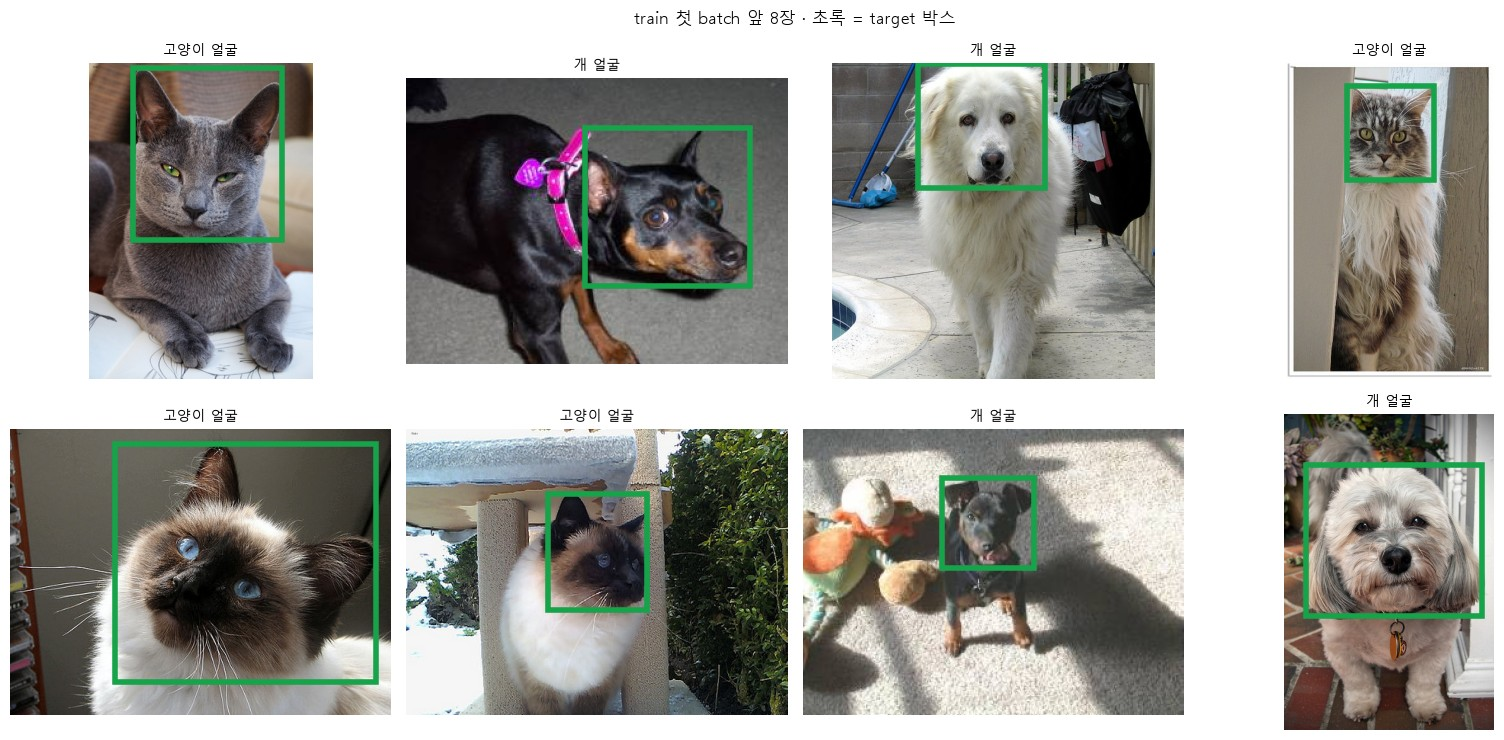

사진 장치: cuda · 박스 장치: cuda


In [9]:
# 왜 · 학습 도중이 아니라 시작 전에 형식 실수를 assert로 잡기 위해
def check_batch(images, targets):                               # batch 하나가 약속을 지키는지
    assert len(images) == len(targets)                          # 같은 수
    for im, t in zip(images, targets):                          # 사진마다
        b, lab = t["boxes"], t["labels"]                        # 박스 · 라벨
        # 이미지
        assert im.dtype == torch.float32 and im.shape[0] == 3 and 0 <= im.min() and im.max() <= 1
        assert b.dtype == torch.float32 and b.ndim == 2 and b.shape[1] == 4  # [N, 4] 실수
        assert lab.dtype == torch.int64 and len(lab) == len(b)  # 정수 · 같은 수
        assert (b[:, 0] < b[:, 2]).all() and (b[:, 1] < b[:, 3]).all()  # x1 < x2 · y1 < y2
        assert (b[:, :2] >= 0).all()                            # 왼쪽 · 위 변이 사진 안
        assert (b[:, 2] <= im.shape[2]).all() and (b[:, 3] <= im.shape[1]).all()  # 오른쪽 · 아래 변
        assert set(lab.tolist()) <= {1, 2}                      # 0(배경) 없음
    print(f"{len(images)}장 점검 통과")                         # 통과


images, targets = next(iter(train_loader))                                     # 첫 batch
check_batch(images, targets)                                                   # 숫자 약속 확인
print("사진 크기 (H, W):", [tuple(im.shape[1:]) for im in images[:4]], "...")  # 제각각
print("라벨:", [CLASSES[lb] for t in targets for lb in t["labels"].tolist()][:6], "...")  # 앞 6개

# 왜 · 첫 batch의 사진과 정답 박스가 맞는지 눈으로 확인하기 위해
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))                        # 앞 8장
for ax, im, t in zip(axes.flat, images, targets):                        # 사진마다
    draw(im.permute(1, 2, 0), gt=t["boxes"], ax=ax,                      # [3, H, W] → [H, W, 3]
         title=" · ".join(CLASSES[lb] for lb in t["labels"].tolist()))
plt.suptitle("train 첫 batch 앞 8장 · 초록 = target 박스", fontsize=12)  # 제목
plt.tight_layout()                                                       # 여백
plt.show()                                                               # 그림 출력

# 왜 · 사진과 정답을 같은 장치로 옮겨야 모델이 받기 때문에
images_dev = [im.to(DEVICE) for im in images]                             # 장치로
targets_dev = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]  # 정답도
# 같은 장치
print("사진 장치:", images_dev[0].device.type, "· 박스 장치:", targets_dev[0]["boxes"].device.type)

**결과** · 예측 정답은 통과

- `16장 점검 통과` — 숫자 약속은 지켜짐
- `사진 크기 (H, W): [(500, 355), (225, 300), (489, 500), (500, 327)] ...` — 사진마다 다름
- `사진 장치: cuda · 박스 장치: cuda` — 같은 장치

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>assert</code></td><td>숫자 약속</td><td>모양 · 자료형 · 범위</td></tr>
<tr><td>그림</td><td>박스 위치</td><td>얼굴을 감쌌나</td></tr>
<tr><td><code>.to(DEVICE)</code></td><td>사진 · 정답 모두</td><td>같은 장치</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 사진만 GPU로 보내고 target을 CPU에 두면 학습 첫 step에서 에러

> ✅ **한 줄 정리** · 첫 batch는 assert로 숫자 약속을, 그림으로 박스 위치를 확인한 뒤 학습한다.

**딥러닝 코드에서는**

- `check_batch(*next(iter(train_loader)))`

### 2-5. `B` train EDA · 얼굴 크기 · `face_sides()` <sub>원본 D2-2 · 셀 55 ~ 60</sub>

> 🎯 **고양이 얼굴과 개 얼굴은 300×300 안에서 크기가 비슷한가?**

💡 **쉽게 말하면**

- SSD는 사진을 300×300으로 줄여서 봄 → **줄인 뒤의 얼굴 긴 변**으로 셈.
- 클래스별 · 분모와 함께.

**실행 흐름**

1. train 박스마다 300 기준 긴 변
2. 클래스별 개수 · 가운데 값 · 50 미만
3. 히스토그램 · 가장 작은 얼굴

**먼저 예측** · 긴 변 50 미만인 아주 작은 얼굴은 많을까? — 답은 코드 실행 결과 아래에

train 사진 2569 장 · 박스 2570 개
cat: 박스  829 (32%) · 긴 변 가운데 138 · 50 미만  7개 (0.8%)
dog: 박스 1741 (68%) · 긴 변 가운데 142 · 50 미만 23개 (1.3%)


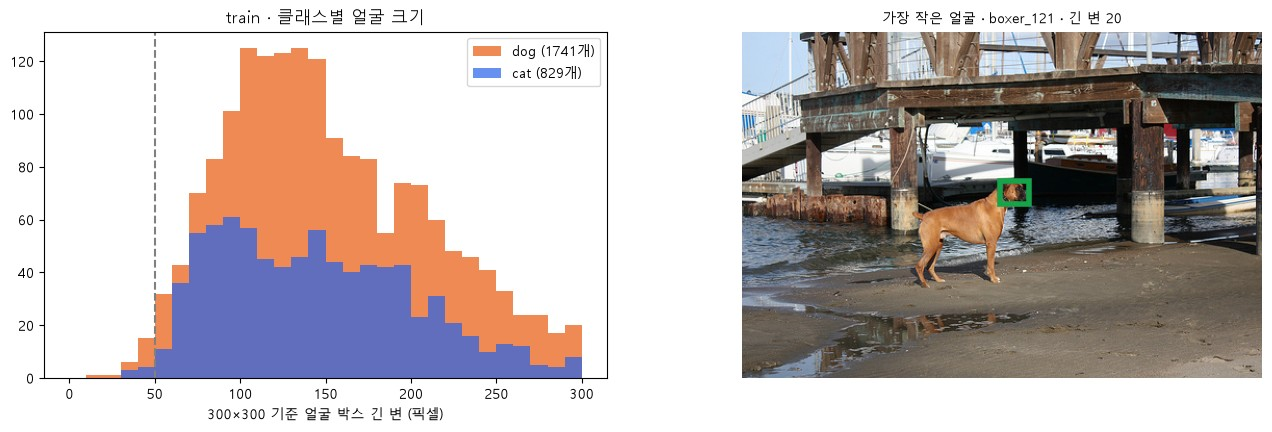

In [10]:
# 왜 · 얼굴 크기 분포를 보고 작은 물체가 얼마나 있는지 알기 위해
def face_sides(ids):  # [(사진, cat/dog, 300 기준 얼굴 긴 변)]
    rows = []                                                                         # 결과
    for stem in ids:                                                                  # 사진마다
        root = ET.parse(XMLS / f"{stem}.xml").getroot()                               # XML
        w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))    # 크기
        for (x1, y1, x2, y2), name in zip(*read_voc(XMLS / f"{stem}.xml")):           # 박스마다
            rows.append((stem, name, max((x2 - x1) / w * 300, (y2 - y1) / h * 300)))  # 긴 변
    return rows                                                                       # 목록


# 왜 · train 박스 수와 얼굴 크기 범위를 숫자로 확인하기 위해
rows = face_sides(train_ds.ids)                                   # train 전체
print("train 사진", len(train_ds), "장 · 박스", len(rows), "개")  # 박스 2개 사진 포함
for name in ["cat", "dog"]:                                       # 클래스마다
    s = torch.tensor([v for _, n, v in rows if n == name])        # 긴 변
    # 분포
    print(f"{name}: 박스 {len(s):4d} ({len(s) / len(rows):.0%}) · 긴 변 가운데 {s.median():.0f}"
          f" · 50 미만 {(s < 50).sum().item():2d}개 ({(s < 50).float().mean():.1%})")

# 왜 · 고양이 · 개 얼굴 크기 분포를 나란히 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))             # 크기 분포 · 가장 작은 얼굴
for name, color in [("dog", "#ea580c"), ("cat", "#2563eb")]:  # 두 클래스
    # 히스토그램
    axes[0].hist([v for _, n, v in rows if n == name], bins=range(0, 310, 10), alpha=0.7,
                 color=color, label=f"{name} ({sum(n == name for _, n, _ in rows)}개)")
axes[0].axvline(50, color="gray", ls="--")                    # 50 기준선
axes[0].set_xlabel("300×300 기준 얼굴 박스 긴 변 (픽셀)")     # x축
axes[0].set_title("train · 클래스별 얼굴 크기", fontsize=12)  # 제목
axes[0].legend()                                              # 범례
small = sorted(rows, key=lambda r: r[2])[0]                   # 가장 작은 얼굴
im, t = train_ds[train_ds.ids.index(small[0])]                # 그 사진
draw(im.permute(1, 2, 0), gt=t["boxes"], ax=axes[1],          # 멀리 찍힌 동물
     title=f"가장 작은 얼굴 · {small[0]} · 긴 변 {small[2]:.0f}")
plt.show()                                                    # 그림 출력

**결과** · 예측 정답은 드묾 — 고양이 `0.8%` · 개 `1.3%`

- `train 사진 2569 장 · 박스 2570 개` — 박스 2개 사진이 하나
- `cat: 박스  829 (32%) · 긴 변 가운데 138 · 50 미만  7개 (0.8%)` — 고양이 얼굴
- `dog: 박스 1741 (68%) · 긴 변 가운데 142 · 50 미만 23개 (1.3%)` — 크기는 비슷 · 개수는 약 2배

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>박스 수</td><td>클래스별 · 비율</td><td>불균형 확인</td></tr>
<tr><td>긴 변 가운데 값</td><td>얼굴 크기</td><td>디폴트 박스와 비교</td></tr>
<tr><td>50 미만</td><td>아주 작은 얼굴</td><td>놓치기 쉬움 (9-3)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 가장 작은 얼굴도 머리 위 박스 → 잘못 친 박스가 아니라 멀리 찍힌 동물

> ✅ **한 줄 정리** · train 얼굴은 대부분 크고, 아주 작은 얼굴은 드물며, 개 박스가 고양이의 약 두 배다.

**딥러닝 코드에서는**

- 9-3에서 같은 정의(300 기준 긴 변)로 크기별 놓침을 셈

---
## 3. 박스를 따라가는 증강

> **이 장의 흐름**
>
> - 2장 Dataset 안에 증강을 넣음
> - 사진만 뒤집기의 함정 · 식 · train에만 · 쓰지 않는 증강

<img src="images/pfo2_flip.png" alt="x1' = W - x2 · x2' = W - x1" width="950">

**파이프라인 위치** · ③ 전처리 — 증강

### 3-1. `A` 사진만 뒤집으면 · `TF.hflip()` <sub>원본 D2-3 · 셀 61 ~ 68</sub>

> 🎯 **Dataset 안에서 사진만 좌우로 뒤집으면 박스는?**

💡 **쉽게 말하면**

- 사진은 거울에 비췄는데 **스티커(박스)는 제자리**.
- 에러는 없고, 숫자 점검도 통과함.

**실행 흐름**

1. 사진만 뒤집은 그림
2. 사진 안 · 모서리 순서 점검
3. train 박스 전부: 원래 박스 vs 실제 얼굴 자리의 IoU

**먼저 예측** · 숫자 점검으로 이 실수를 잡을 수 있을까? — 답은 코드 실행 결과 아래에

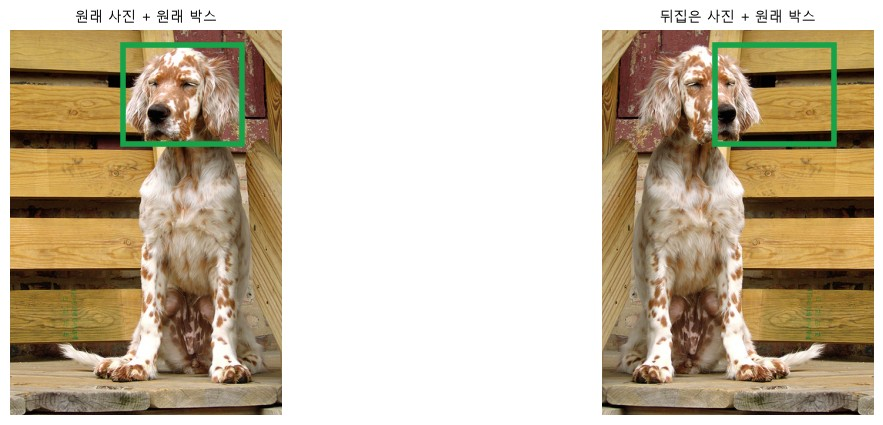

사진 안       : True
x1 < x2, y1 < y2: True
박스 숫자      : [[146.0, 19.0, 301.0, 148.0]] ← 뒤집기 전과 똑같음


train 박스 2570 개 · 사진만 뒤집었을 때 원래 박스와 실제 얼굴의 IoU
IoU 0 (완전히 빗나감): 523개 · IoU 0.5 이상 (겉보기엔 맞음): 1252개 (49%)


In [11]:
from torchvision import tv_tensors                      # 박스 텐서 형식
from torchvision.ops import box_iou                     # IoU 표
from torchvision.transforms.v2 import functional as F2  # 박스까지 뒤집어 주는 함수

# 왜 · 사진만 뒤집으면 박스가 얼굴 자리에서 벗어나는 것을 보기 위해
stem = train_ds.ids[0]                                             # train 0번 사진
image, target = TF.to_tensor(load_image(stem)), make_target(stem)  # 사진 · 정답
flipped = TF.hflip(image)                                          # 사진만 좌우로 · 박스는 그대로
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                    # 2칸
draw(image.permute(1, 2, 0), gt=target["boxes"], ax=axes[0], title="원래 사진 + 원래 박스")  # 맞음
# 어긋남
draw(flipped.permute(1, 2, 0), gt=target["boxes"], ax=axes[1], title="뒤집은 사진 + 원래 박스")
plt.show()                                                         # 그림 출력

# 왜 · 어긋난 박스도 사진 안에 있어 에러 없이 지나간다는 함정을 보이기 위해
b, W, H = target["boxes"], image.shape[2], image.shape[1]              # 박스 · 폭 · 높이
inside = bool((b[:, 0] >= 0).all() and (b[:, 2] <= W).all() and (b[:, 3] <= H).all())  # 사진 안
order = bool((b[:, 0] < b[:, 2]).all() and (b[:, 1] < b[:, 3]).all())  # 모서리 순서
print("사진 안       :", inside)                                       # 통과
print("x1 < x2, y1 < y2:", order)                                      # 통과
print("박스 숫자      :", b.tolist(), "← 뒤집기 전과 똑같음")          # 숫자 점검으로는 못 잡음

# 왜 · train 전체에서 사진만 뒤집었을 때 정답이 얼마나 틀어지는지 세기 위해
ious = []  # 사진만 뒤집었을 때 · 원래 박스 vs 실제 얼굴 자리
for s in train_ds.ids:                                                          # train 전체
    root = ET.parse(XMLS / f"{s}.xml").getroot()                                # XML
    w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))  # 크기
    bx = torch.tensor(read_voc(XMLS / f"{s}.xml")[0])                           # 원래 박스
    # 실제 자리
    face = F2.horizontal_flip(tv_tensors.BoundingBoxes(bx, format="XYXY", canvas_size=(h, w)))
    ious += box_iou(bx, face.as_subclass(torch.Tensor)).diagonal().tolist()     # 같은 박스끼리 IoU
ious = torch.tensor(ious)                                                       # 텐서로
print("train 박스", len(ious), "개 · 사진만 뒤집었을 때 원래 박스와 실제 얼굴의 IoU")  # 설명
# 함정
print(f"IoU 0 (완전히 빗나감): {(ious == 0).sum().item()}개 · IoU 0.5 이상 (겉보기엔 맞음): "
      f"{(ious >= 0.5).sum().item()}개 ({(ious >= 0.5).float().mean():.0%})")

**결과** · 예측 정답은 못 잡음 — 숫자 점검은 모두 `True`

- `사진 안       : True` — 박스 숫자는 그대로라 통과
- `박스 숫자      : [[146.0, 19.0, 301.0, 148.0]] ← 뒤집기 전과 똑같음` — 사진만 바뀜
- `IoU 0 (완전히 빗나감): 523개 · IoU 0.5 이상 (겉보기엔 맞음): 1252개 (49%)` — 절반은 그림으로 봐도 맞아 보임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>숫자 점검</td><td>통과</td><td>못 잡음</td></tr>
<tr><td>그림 몇 장</td><td>가운데 얼굴은 맞아 보임</td><td>놓치기 쉬움</td></tr>
<tr><td>IoU 계산</td><td>원래 박스 vs 실제 자리</td><td>얼마나 숨는지</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 얼굴이 가운데에 있으면 뒤집어도 박스가 거의 맞아 보임 → 그림 몇 장으로는 못 알아챔

> ✅ **한 줄 정리** · 사진만 뒤집으면 에러 없이 박스가 틀어지고, 숫자 점검으로는 잡히지 않는다.

**딥러닝 코드에서는**

- 증강은 사진과 박스를 함께 바꾸는 함수로만

### 3-2. `A` 박스도 같이 뒤집기 · `flip_boxes()` · `hflip()` <sub>원본 D2-3 · 셀 69 ~ 74</sub>

> 🎯 **박스는 어떤 식으로 뒤집고, 식이 맞는지 어떻게 확인하는가?**

💡 **쉽게 말하면**

- 거울에 비추면 **왼쪽 변이 오른쪽으로** 감.
- x1' = W - x2 · x2' = W - x1 · y와 라벨은 그대로.

**실행 흐름**

1. 사진 + 박스 뒤집기 (박스 1개 · 2개)
2. 숫자 전 → 후
3. train 전체: 두 번 뒤집기 · 순서 · 범위

**먼저 예측** · 모든 train 박스를 두 번 뒤집으면 원래와 오차 0일까? — 답은 코드 실행 결과 아래에

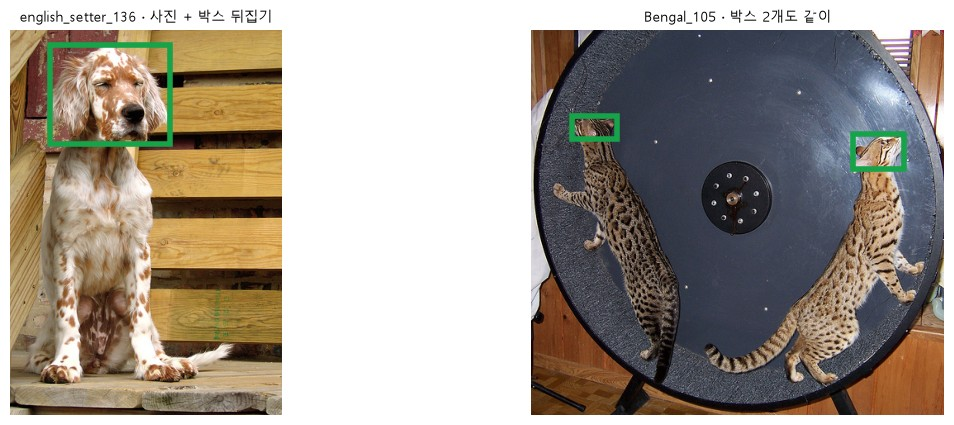

english_setter_136 원래 [[146.0, 19.0, 301.0, 148.0]] → 뒤집은 뒤 [[52.0, 19.0, 207.0, 148.0]] · 사진 폭 353


train 박스 2570 개 · 두 번 뒤집은 뒤 최대 오차: 0.0
한 번 뒤집은 박스 중 x1 < x2 · 0 ≤ x ≤ W를 어긴 사진: 0 장


In [12]:
# 왜 · 사진과 박스를 함께 뒤집어 정답이 얼굴 자리에 남게 하기 위해
def flip_boxes(boxes, W):        # 좌우 뒤집기: x1' = W - x2 · x2' = W - x1
    out = boxes.clone()          # 원래는 그대로
    out[:, 0] = W - boxes[:, 2]  # 새 왼쪽 변
    out[:, 2] = W - boxes[:, 0]  # 새 오른쪽 변
    return out                   # y는 그대로


def hflip(image, target):          # 사진과 박스를 같이 뒤집기 · 라벨은 그대로
    target = {**target, "boxes": flip_boxes(target["boxes"], image.shape[-1])}  # 박스
    return image.flip(-1), target  # 사진


# 왜 · 박스 1개 · 2개 사진에서 뒤집기 결과를 확인하기 위해
image_f, target_f = hflip(image, target)                          # 0번 사진
# 박스 2개
image_b, target_b = hflip(TF.to_tensor(load_image("Bengal_105")), make_target("Bengal_105"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                   # 2칸
draw(image_f.permute(1, 2, 0), gt=target_f["boxes"], ax=axes[0],  # 박스가 따라감
     title=f"{stem} · 사진 + 박스 뒤집기")
draw(image_b.permute(1, 2, 0), gt=target_b["boxes"], ax=axes[1],  # 둘 다 따라감
     title="Bengal_105 · 박스 2개도 같이")
plt.show()                                                        # 그림 출력
# 숫자 전 → 후
print(stem, "원래", target["boxes"].tolist(), "→ 뒤집은 뒤", target_f["boxes"].tolist(),
      "· 사진 폭", image.shape[-1])

# 왜 · train 전체에서 박스를 함께 뒤집으면 정답이 맞는지 검증하기 위해
n_box, worst, bad = 0, 0.0, []  # 박스 수 · 최대 오차 · 어긴 사진
for s in train_ds.ids:                                                     # train 전체
    w = int(ET.parse(XMLS / f"{s}.xml").getroot().findtext("size/width"))  # 폭
    bx = make_target(s)["boxes"]                                           # 박스
    once = flip_boxes(bx, w)                                               # 한 번
    twice = flip_boxes(once, w)                                            # 두 번
    n_box += len(bx)                                                       # 세기
    worst = max(worst, (twice - bx).abs().max().item())                    # 원래와 차이
    ok = (once[:, 0] < once[:, 2]).all() and (once[:, 0] >= 0).all()       # 순서 · 왼쪽 범위
    if not (ok and (once[:, 2] <= w).all()):                               # 오른쪽 범위까지 어기면
        bad.append(s)                                                      # 기록
print("train 박스", n_box, "개 · 두 번 뒤집은 뒤 최대 오차:", worst)       # 0이면 식이 맞음
print("한 번 뒤집은 박스 중 x1 < x2 · 0 ≤ x ≤ W를 어긴 사진:", len(bad), "장")  # 0

**결과** · 예측 정답은 오차 `0.0`

- `english_setter_136 원래 [[146.0, 19.0, 301.0, 148.0]] → 뒤집은 뒤 [[52.0, 19.0, 207.0, 148.0]]` — 353 - 301 = 52 · 353 - 146 = 207
- `train 박스 2570 개 · 두 번 뒤집은 뒤 최대 오차: 0.0` — 식이 맞음
- `한 번 뒤집은 박스 중 x1 < x2 · 0 ≤ x ≤ W를 어긴 사진: 0 장` — 순서 · 범위 통과

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>두 번 뒤집기</td><td>원래로 돌아오나</td><td>식 점검</td></tr>
<tr><td>x1 &lt; x2 · 0 ≤ x ≤ W</td><td>순서 · 범위</td><td>숫자 점검</td></tr>
<tr><td>그림</td><td>박스가 얼굴을 따라가나</td><td>눈 점검</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `x1' = W - x1`처럼 양 끝을 따로 뒤집으면 x1 > x2 (5-3에서 학습이 멈춤)

> ✅ **한 줄 정리** · 좌우 뒤집기는 x1' = W - x2, x2' = W - x1이고, 두 번 뒤집으면 원래 숫자로 돌아와야 한다.

**딥러닝 코드에서는**

- `torchvision.transforms.v2.RandomHorizontalFlip` — 박스까지 같이 뒤집음

### 3-3. `A` train에만 · 확률 0.5 · `flip=True` · `torch.Generator` <sub>원본 D2-3 · 셀 75 ~ 81</sub>

> 🎯 **증강은 언제 · 어디에 적용하는가?**

💡 **쉽게 말하면**

- **꺼낼 때마다** 뒤집을지 새로 정함 → 같은 사진도 매번 다름.
- val · test는 늘 같은 사진 (flip=False).

**실행 흐름**

1. 같은 사진 네 번 꺼내기
2. val 0번 두 번 꺼내기
3. 뒤집기 켠 첫 batch 점검
4. 한 epoch에 뒤집힐 사진 수

**먼저 예측** · 한 epoch에 뒤집힐 사진은 몇 장일까? — 답은 코드 실행 결과 아래에

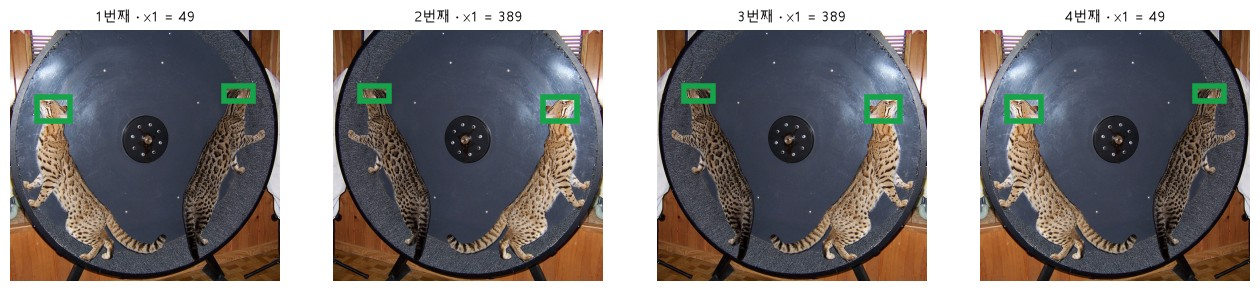

val_ds.flip = False · val 0번을 두 번 꺼내면 같음: True
16장 점검 통과
16장 중 뒤집힌 사진: 7 장
한 epoch에 뒤집힐 사진: 1299 / 2569 = 0.506


In [13]:
# 왜 · 같은 사진을 여러 번 꺼낼 때 뒤집기가 확률적으로 바뀌는지 보기 위해
demo = PetFaces(train_ds.ids, flip=True)             # 보여 주기용 (학습용 난수와 따로)
i = demo.ids.index("Bengal_105")                     # 박스 2개 사진
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))    # 네 번 꺼내기
for k, ax in enumerate(axes):                        # 네 번
    im, t = demo[i]                                  # 같은 사진을 꺼냄
    draw(im.permute(1, 2, 0), gt=t["boxes"], ax=ax,  # 꺼낼 때마다 새로 정함
         title=f"{k + 1}번째 · x1 = {t['boxes'][0, 0]:.0f}")
plt.show()                                           # 그림 출력
(v1, t1), (v2, t2) = val_ds[0], val_ds[0]            # val은 두 번 꺼내도
print("val_ds.flip =", val_ds.flip, "· val 0번을 두 번 꺼내면 같음:",  # 늘 같음
      torch.equal(v1, v2) and torch.equal(t1["boxes"], t2["boxes"]))

# 왜 · 뒤집기를 켠 DataLoader에서도 형식 점검이 통과하는지 확인하기 위해
aug_loader = DataLoader(demo, batch_size=16, shuffle=True, num_workers=0,   # 2-4와 같은 16장
                        generator=torch.Generator().manual_seed(0), collate_fn=collate_fn)
images_aug, targets_aug = next(iter(aug_loader))                            # 뒤집기 켠 첫 batch
check_batch(images_aug, targets_aug)                                        # 2-4 점검 그대로
flipped_mask = [not torch.equal(a, b) for a, b in zip(images_aug, images)]  # 뒤집혔나
print("16장 중 뒤집힌 사진:", sum(flipped_mask), "장")                      # 약 절반

# 왜 · 한 epoch에 뒤집히는 사진 수를 세어 확률 0.5가 맞는지 보기 위해
train_ds_flip = PetFaces(train_ds.ids, flip=True)  # RUN_B와 같은 설정: seed 1 · p = 0.5
gen = torch.Generator().manual_seed(1)             # 같은 seed의 난수
n_flip = sum(bool(torch.rand(1, generator=gen) < 0.5) for _ in train_ds_flip.ids)  # 한 epoch 동안
print(f"한 epoch에 뒤집힐 사진: {n_flip} / {len(train_ds_flip)}"  # 약 절반
      f" = {n_flip / len(train_ds_flip):.3f}")

**결과** · 예측 정답은 `1299`장 (약 절반)

- `val_ds.flip = False · val 0번을 두 번 꺼내면 같음: True` — val은 늘 같은 사진
- `16장 중 뒤집힌 사진: 7 장` — 뒤집어도 점검 통과
- `한 epoch에 뒤집힐 사진: 1299 / 2569 = 0.506` — 원본 RUN_B 기록과 같은 수

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>train</td><td>꺼낼 때마다 확률 0.5</td><td>증강</td></tr>
<tr><td>val · test</td><td>flip=False</td><td>늘 같은 사진</td></tr>
<tr><td>뒤집기 전용 난수</td><td>seed 1</td><td>다시 해도 같은 장수</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - val에도 증강을 켜면 평가할 때마다 점수가 달라짐

> ✅ **한 줄 정리** · 증강은 train에만 꺼낼 때마다 확률로 적용하고, val · test는 고정한다.

**딥러닝 코드에서는**

- `PetFaces(train_ids, flip=True)` = RUN_B의 train 데이터 (10장)

### 3-4. `B` 상하 뒤집기 · 회전은? · `TF.vflip()` · `TF.rotate()` <sub>원본 D2-3 · 셀 82 ~ 86</sub>

> 🎯 **상하 뒤집기나 회전도 쓰면 좋을까?**

💡 **쉽게 말하면**

- 증강은 **val에 있을 법한 모습**만.
- 회전하면 네 모서리를 감싼 박스가 커져 배경까지 들어감.

**실행 흐름**

1. 상하 뒤집기 그림
2. 30° 회전 · 네 모서리를 감싼 새 박스
3. 새 박스 넓이 배수

**먼저 예측** · 30° 돌린 뒤 새 박스 넓이는 원래의 몇 배? — 답은 코드 실행 결과 아래에

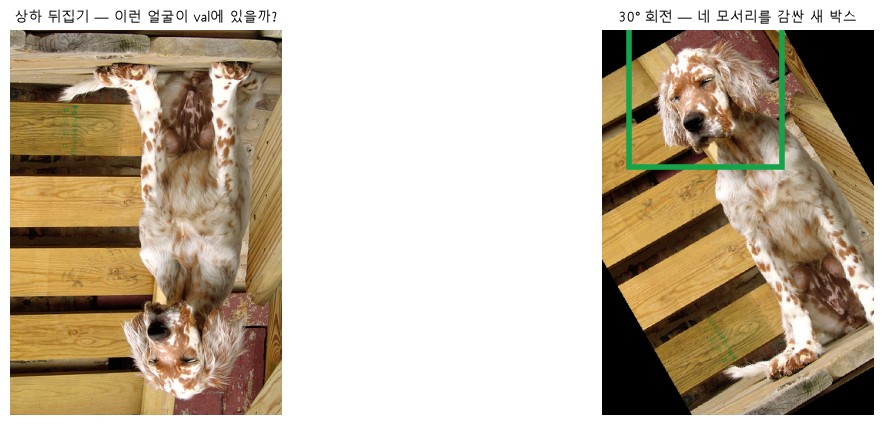

회전 뒤 새 박스 넓이 = 원래의 1.88배


In [14]:
# 왜 · 상하 뒤집기 · 회전이 이 데이터에 맞지 않는 이유를 그림으로 보기 위해
img = TF.to_tensor(load_image(stem))                           # 0번 사진
t = make_target(stem)                                          # 정답
W, H = img.shape[2], img.shape[1]                              # 폭 · 높이
rot = TF.rotate(img, 30)                                       # 가운데를 축으로 30° (반시계)
x1, y1, x2, y2 = t["boxes"][0].tolist()                        # 원래 박스
a, cx, cy = math.radians(30), W / 2, H / 2                     # 각도 · 중심
pts = [(cx + (x - cx) * math.cos(a) + (y - cy) * math.sin(a),  # 네 모서리를 돌림
        cy - (x - cx) * math.sin(a) + (y - cy) * math.cos(a)) for x in (x1, x2) for y in (y1, y2)]
xs_, ys_ = [p[0] for p in pts], [p[1] for p in pts]            # 돌린 모서리
new = [min(xs_), min(ys_), max(xs_), max(ys_)]                 # 네 모서리를 감싼 박스

fig, axes = plt.subplots(1, 2, figsize=(14, 5))                               # 2칸
# 거꾸로
draw(TF.vflip(img).permute(1, 2, 0), ax=axes[0], title="상하 뒤집기 — 이런 얼굴이 val에 있을까?")
# 넓어짐
draw(rot.permute(1, 2, 0), gt=[new], ax=axes[1], title="30° 회전 — 네 모서리를 감싼 새 박스")
plt.show()                                                                    # 그림 출력
area_ratio = (new[2] - new[0]) * (new[3] - new[1]) / ((x2 - x1) * (y2 - y1))  # 넓이 배수
print(f"회전 뒤 새 박스 넓이 = 원래의 {area_ratio:.2f}배")                    # 배경까지 들어감

**결과** · 예측 정답은 `1.88`배

- `회전 뒤 새 박스 넓이 = 원래의 1.88배` — 배경까지 얼굴 박스 안에 들어감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>좌우 뒤집기</td><td>실제로 흔한 모습</td><td>씀 (RUN_B)</td></tr>
<tr><td>상하 뒤집기</td><td>거꾸로 선 얼굴</td><td>안 씀</td></tr>
<tr><td>회전</td><td>박스가 커짐</td><td>안 씀</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 증강을 여러 개 한꺼번에 켜면 무엇이 효과였는지 모름 → 한 가지만 (10장)

> ✅ **한 줄 정리** · 상하 뒤집기와 회전은 데이터에 없는 모습이거나 박스를 부풀리므로 쓰지 않는다.

**딥러닝 코드에서는**

- 오늘 두 번의 학습: RUN_A(뒤집기 없음) · RUN_B(좌우 뒤집기만)

---
## 4. 미션 헤드 · 91칸을 3칸으로

> **이 장의 흐름**
>
> - Day01 SSD 구조 → 분류 헤드만 교체
> - 예시 코드의 함정 · 새 헤드 · 학습 전 예측

<img src="images/pfo2_head.png" alt="분류 헤드만 새로 · 나머지는 COCO 값" width="763">

**파이프라인 위치** · ④ 모델 — 전이학습

### 4-1. `A` 미션 예시 코드의 함정 · `classification_head.num_classes` <sub>원본 D2-4 · 셀 87 ~ 100</sub>

> 🎯 **`num_classes = 3`을 적으면 출력이 3칸이 되는가?**

💡 **쉽게 말하면**

- 클래스 수는 **층을 만들 때 출력 채널 수**에 들어간 숫자.
- 만든 뒤에 이름표만 바꾸면 층은 91칸 그대로.

**실행 흐름**

1. COCO SSD의 분류 헤드 · 점수 모양
2. 미션 예시 코드 두 줄
3. 점수 모양 · 손실 계산 · 1번 칸 이름

**먼저 예측** · 숫자를 바꾼 뒤 클래스 점수 모양은? — 답은 코드 실행 결과 아래에

In [15]:
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16  # COCO SSD

# 왜 · 미션 예시 코드의 함정을 실제 모델로 확인하기 위해
SSD_W = SSD300_VGG16_Weights.COCO_V1                                      # COCO 가중치
COCO_NAMES = SSD_W.meta["categories"]                                     # 91칸 이름
stem = "Abyssinian_140"                                                   # 어제 본 사진 · train 쪽
x = TF.to_tensor(load_image(stem))                                        # 텐서
gt_boxes, gt_names = read_voc(XMLS / f"{stem}.xml")                       # 정답
model = ssd300_vgg16(weights=SSD_W).eval()                                # COCO 모델
print("분류 헤드 첫 층:", model.head.classification_head.module_list[0])  # 512 → 364
print("클래스 점수 모양:", head_shapes(model, x)[0])                      # (1, 8732, 91)

# 왜 · num_classes 숫자만 바꾸면 층이 그대로라는 것을 확인하기 위해
head = model.head.classification_head                     # 분류 헤드
print("원래 num_classes라는 이름이 있었나?", hasattr(head, "num_classes"))  # False
num_classes = 3                                           # 미션 예시 코드 그대로 (background 포함)
model.head.classification_head.num_classes = num_classes  # 이름표만 붙음
print("적어 둔 숫자     :", head.num_classes)             # 3
print("계산에 쓰는 칸 수:", head.num_columns)             # 91
print("클래스 점수 모양 :", head_shapes(model, x)[0])     # 여전히 91칸

model.train()                                                                     # 학습 모드
loss = model([x], [make_target(stem)])                                            # 손실 계산
model.eval()                                                                      # 되돌리기
print({k: round(v.item(), 3) for k, v in loss.items()})                           # 에러 없음
print("91칸 모델에서 1번 칸의 이름:", COCO_NAMES[1], "· 2번 칸:", COCO_NAMES[2])  # person · bicycle

분류 헤드 첫 층: Conv2d(512, 364, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


클래스 점수 모양: (1, 8732, 91)
원래 num_classes라는 이름이 있었나? False
적어 둔 숫자     : 3
계산에 쓰는 칸 수: 91


클래스 점수 모양 : (1, 8732, 91)


{'bbox_regression': 1.386, 'classification': 11.146}
91칸 모델에서 1번 칸의 이름: person · 2번 칸: bicycle


**결과** · 예측 정답은 그대로 `(1, 8732, 91)`

- `분류 헤드 첫 층: Conv2d(512, 364, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))` — 364 = 4 × 91
- `원래 num_classes라는 이름이 있었나? False` — 새 이름표가 생긴 것뿐
- `계산에 쓰는 칸 수: 91` — num_columns는 그대로
- `클래스 점수 모양 : (1, 8732, 91)` — 출력도 91칸
- `91칸 모델에서 1번 칸의 이름: person · 2번 칸: bicycle` — 1 = 고양이 얼굴을 person 칸에 학습

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>num_classes</code> 이름표</td><td>새 속성만 생김</td><td>효과 없음</td></tr>
<tr><td><code>num_columns</code></td><td>계산에 쓰는 칸 수</td><td>91 그대로</td></tr>
<tr><td>손실 계산</td><td>에러 없음</td><td>조용한 버그</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 우리 1 = 고양이 얼굴인데 이 모델의 1번 칸은 person → 에러 없이 틀린 학습

> ✅ **한 줄 정리** · 만든 층의 클래스 수는 속성 숫자를 바꿔도 바뀌지 않으며, 손실 계산도 에러 없이 진행된다.

**딥러닝 코드에서는**

- torchvision 소스: `SSDClassificationHead.__init__`에서 `num_classes * anchors` 채널

### 4-2. `A` 분류 헤드를 새로 끼우기 · `SSDClassificationHead()` <sub>원본 D2-4 · 셀 101 ~ 107</sub>

> 🎯 **3칸 헤드는 어떻게 만들고, 무엇이 COCO에서 왔는가?**

💡 **쉽게 말하면**

- **머리(분류 헤드)만 새로 달고 몸통은 그대로**.
- 몸통 · 위치 헤드는 COCO 값에서 시작, 분류 헤드는 무작위.

**실행 흐름**

1. 맵마다 채널 · 박스 수로 새 헤드
2. 층 출력 채널 · 점수 모양
3. COCO와 같은 부분 · 파라미터 수

**먼저 예측** · 새 헤드의 클래스 점수 모양은? — 답은 코드 실행 결과 아래에

In [16]:
from torchvision.models.detection.ssd import SSDClassificationHead  # 분류 헤드 틀

# 왜 · 배경 + 고양이 얼굴 + 개 얼굴 = 3칸을 한곳에서 정하기 위해
NUM_CLASSES = 3  # 0 배경 · 1 고양이 얼굴 · 2 개 얼굴


# 왜 · COCO 몸통은 살리고 분류 헤드만 새로 끼운 모델을 만들기 위해
def make_mission_ssd(num_classes=NUM_CLASSES):                    # COCO SSD + 새 분류 헤드
    m = ssd300_vgg16(weights=SSD_W)                               # COCO 몸통 · 위치 헤드
    old = m.head.classification_head                              # 바꿀 자리
    in_channels = [conv.in_channels for conv in old.module_list]  # 맵마다 채널
    num_anchors = m.anchor_generator.num_anchors_per_location()   # 칸마다 박스 수
    # 새 층
    m.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes)
    return m                                                      # 분류 헤드만 새것


torch.manual_seed(0)                                               # 새 층 시작값 고정
model = make_mission_ssd().eval()                                  # 깨끗한 모델 (이름표 모델 버림)
for conv in model.head.classification_head.module_list:            # 맵마다
    print(f"Conv2d({conv.in_channels:>4} → {conv.out_channels})")  # 박스 수 × 3
cls_shape, box_shape = head_shapes(model, x)                       # 모양
print("클래스 점수 모양:", cls_shape, "· 위치 보정 모양:", box_shape)  # (1, 8732, 3)


# 왜 · 어느 부분이 COCO 값 그대로인지 텐서 비교로 확인하기 위해
def same(a, b):  # 두 부분의 값이 모두 같은가
    # 모든 텐서가 같은가
    return all(torch.equal(a.state_dict()[k], b.state_dict()[k]) for k in a.state_dict())


# 왜 · 부분별 파라미터 수를 세어 무엇이 새것인지 보기 위해
def count(m):                                      # 파라미터 수
    return sum(p.numel() for p in m.parameters())  # 원소 수 합


# 왜 · 새 모델과 COCO 모델을 부분별로 대조하기 위해
coco = ssd300_vgg16(weights=SSD_W)  # 비교용 COCO 모델
print("몸통(VGG)   COCO와 같음:", same(model.backbone, coco.backbone),                # True
      f"· 파라미터 {count(model.backbone):,}")
# True
print("위치 헤드    COCO와 같음:", same(model.head.regression_head, coco.head.regression_head),
      f"· 파라미터 {count(model.head.regression_head):,}")
print(f"분류 헤드    새로 만듦 · 파라미터 {count(model.head.classification_head):,}"  # 작아짐
      f" (COCO 91칸 헤드는 {count(coco.head.classification_head):,})")
trainable = sum(p.numel() for p in model.backbone.parameters() if p.requires_grad)    # 학습 대상
# 일부 고정
print(f"몸통 중 학습 대상: {trainable:,} / {count(model.backbone):,} (나머지 = 맨 앞 층, 고정)")

Conv2d( 512 → 12)
Conv2d(1024 → 18)
Conv2d( 512 → 18)
Conv2d( 256 → 18)
Conv2d( 256 → 12)
Conv2d( 256 → 12)
클래스 점수 모양: (1, 8732, 3) · 위치 보정 모양: (1, 8732, 4)


몸통(VGG)   COCO와 같음: True · 파라미터 22,943,936
위치 헤드    COCO와 같음: True · 파라미터 534,648
분류 헤드    새로 만듦 · 파라미터 400,986 (COCO 91칸 헤드는 12,163,242)
몸통 중 학습 대상: 22,905,216 / 22,943,936 (나머지 = 맨 앞 층, 고정)


**결과** · 예측 정답은 `(1, 8732, 3)`

- `Conv2d( 512 → 12)` — 4 × 3 = 12
- `클래스 점수 모양: (1, 8732, 3) · 위치 보정 모양: (1, 8732, 4)` — 디폴트 박스 8732 그대로
- `몸통(VGG)   COCO와 같음: True · 파라미터 22,943,936` — COCO 값에서 시작
- `분류 헤드    새로 만듦 · 파라미터 400,986 (COCO 91칸 헤드는 12,163,242)` — 칸이 줄어 작아짐
- `몸통 중 학습 대상: 22,905,216 / 22,943,936 (나머지 = 맨 앞 층, 고정)` — 맨 앞 층만 고정

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>몸통 (VGG16)</td><td>COCO 값</td><td>맨 앞 층만 고정</td></tr>
<tr><td>위치 헤드</td><td>COCO 값</td><td>디폴트 박스 8732 그대로</td></tr>
<tr><td>분류 헤드</td><td>새로 만듦 · 3칸</td><td>무작위 시작</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - Faster R-CNN이면 `box_predictor`를 `FastRCNNPredictor(1024, 3)`으로 바꿈 (이름이 다름)

> ✅ **한 줄 정리** · 분류 헤드를 클래스 3칸으로 새로 만들어 끼우고, 몸통과 위치 헤드는 COCO 값에서 시작한다.

**딥러닝 코드에서는**

- `make_mission_ssd()` = 6 · 10장 두 학습의 출발점

### 4-3. `B` 학습 전 새 헤드로 예측하면 · `model([x])` <sub>원본 D2-4 · 셀 108 ~ 112</sub>

> 🎯 **학습 전 새 헤드의 예측을 믿을 수 있는가?**

💡 **쉽게 말하면**

- 모양은 미션에 맞음 (라벨 1 · 2).
- 하지만 **점수가 높아도 학습 전** → 얼굴을 찾는다는 근거 아님.

**실행 흐름**

1. 새 헤드로 예측
2. 라벨 종류 · 점수 상위 3개
3. 상위 10개 박스 그림

**먼저 예측** · 학습 전인데 점수가 높게 나올까? — 답은 코드 실행 결과 아래에

박스 수: 200 · 이번 예측에 나온 라벨: [1, 2]
구조상 나올 수 있는 라벨: [1, 2] (0 = 배경은 출력하지 않음)
점수 상위 3개: [0.992, 0.991, 0.99]


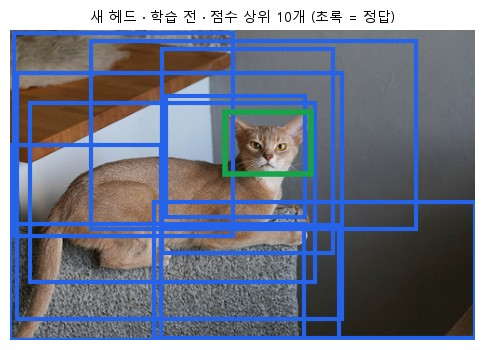

In [17]:
with torch.no_grad():                                                        # 예측만
    # 왜 · 학습 전 새 헤드도 라벨 1 · 2만 낸다는 것과 점수가 아직 엉터리라는 것을 확인하기 위해
    pred = model([x])[0]                                                     # 새 헤드 · 학습 전
print("박스 수:", len(pred["boxes"]), "· 이번 예측에 나온 라벨:",            # 1 · 2
      sorted(pred["labels"].unique().tolist()))
# 1 · 2
print("구조상 나올 수 있는 라벨:", list(range(1, NUM_CLASSES)), "(0 = 배경은 출력하지 않음)")
print("점수 상위 3개:", [round(s, 3) for s in pred["scores"][:3].tolist()])  # 높아도 학습 전
draw(load_image(stem), gt=gt_boxes, pred=pred["boxes"][:10],                 # 상위 10개
     title="새 헤드 · 학습 전 · 점수 상위 10개 (초록 = 정답)")
plt.show()                                                                   # 그림 출력

**결과** · 예측 정답은 나옴 — 상위 `0.992`

- `박스 수: 200 · 이번 예측에 나온 라벨: [1, 2]` — 모양은 미션에 맞음
- `점수 상위 3개: [0.992, 0.991, 0.99]` — 학습 전이라 의미 없는 높은 점수

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>모양 확인</td><td>라벨 1 · 2만</td><td>통과</td></tr>
<tr><td>점수</td><td>학습 전 → 의미 없음</td><td>믿지 않음</td></tr>
<tr><td>그림</td><td>엉뚱한 자리</td><td>학습이 필요</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 무작위 헤드의 점수는 확신이 아님 → 학습 뒤 val로만 판단

> ✅ **한 줄 정리** · 학습 전 새 헤드는 모양만 맞을 뿐, 점수가 높아도 얼굴을 찾는다고 볼 수 없다.

**딥러닝 코드에서는**

- 5장 스모크 테스트로 학습이 시작되는지부터 확인

---
## 5. 스모크 테스트

> **이 장의 흐름**
>
> - 4장 모델로 바로 학습하지 않음
> - 모양 한 줄 · 15 step · 잘못된 박스 · 모드

<img src="images/od2_modes.png" alt="학습 모드는 손실 dict, 평가 모드는 예측 list" width="763">

**파이프라인 위치** · ⑤ 학습 전 점검

### 5-1. `A` 확인 1 · 모양 한 줄 · `check_head()` <sub>원본 D2-5 · 셀 113 ~ 118</sub>

> 🎯 **75분짜리 학습을 걸기 전에 무엇부터 확인하는가?**

💡 **쉽게 말하면**

- **학습 전 1분 점검**.
- 첫째: 클래스 점수 마지막 칸이 3인지 한 줄로.

**실행 흐름**

1. 모양 확인 함수 (assert)
2. 이름표 모델 → 멈춤
3. 새 헤드 모델 → 통과

**먼저 예측** · 이름표 모델은 통과할까? — 답은 코드 실행 결과 아래에

In [18]:
# 왜 · 헤드 교체 실수를 학습 전에 한 줄로 잡기 위해
def check_head(m, x, num_classes=NUM_CLASSES):  # 학습 전 한 줄 확인
    cls_shape, _ = head_shapes(m, x)            # 모양
    # 멈춤
    assert cls_shape[-1] == num_classes, f"클래스 점수 {cls_shape[-1]}칸 — {num_classes}칸이어야 함"
    return cls_shape                            # 통과하면 모양


images, targets = next(iter(train_loader))       # train 첫 묶음 16장
x0 = images[0]                                   # 한 장
tagged = ssd300_vgg16(weights=SSD_W).eval()      # 4-1 미션 예시 코드 그대로
tagged.head.classification_head.num_classes = 3  # 이름표만
try:
    check_head(tagged, x0)                       # 91칸
except AssertionError as e:                      # 멈춤
    print("멈춤 →", e)                           # 조용한 버그를 잡음

torch.manual_seed(0)                                                            # 시작값 고정
smoke_model = make_mission_ssd().to(DEVICE)                                     # 스모크용 새 모델
print("새 헤드 모델 →", check_head(smoke_model.eval(), x0.to(DEVICE)), "통과")  # 3칸
del tagged                                                                      # 이름표 모델은 버림

멈춤 → 클래스 점수 91칸 — 3칸이어야 함


새 헤드 모델 → (1, 8732, 3) 통과


**결과** · 예측 정답은 멈춤 — 91칸

- `멈춤 → 클래스 점수 91칸 — 3칸이어야 함` — 4-1 버그를 한 줄로 잡음
- `새 헤드 모델 → (1, 8732, 3) 통과` — 학습해도 됨

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>이름표 모델</td><td>91칸 → 멈춤</td><td>4-1 버그</td></tr>
<tr><td>새 헤드 모델</td><td>3칸 → 통과</td><td>학습 가능</td></tr>
<tr><td>assert 메시지</td><td>몇 칸인지 적음</td><td>원인 바로 앎</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - Conv2d 가중치 모양이 아니라 **헤드 출력 점수 모양**의 마지막 숫자를 봄

> ✅ **한 줄 정리** · 학습 전에 클래스 점수 모양을 한 줄로 확인하면 4-1의 조용한 버그를 잡는다.

**딥러닝 코드에서는**

- `assert head_shapes(model, x)[0][-1] == 3`

### 5-2. `A` 확인 2 · 15 step만 학습 · `train_step()` <sub>원본 D2-5 · 셀 119 ~ 123</sub>

> 🎯 **무작위 분류 헤드로 15 step 학습하면 손실은 숫자로 나오고 줄어드는가?**

💡 **쉽게 말하면**

- **몇 step만 돌려 보는 연기 시험(스모크)**.
- 손실이 nan이 아니고 내려가면 연결은 됨.

**실행 흐름**

1. 한 step 함수
2. 15 step · 손실 유한 확인
3. 손실 그림

**먼저 예측** · 15 step 동안 분류 손실은 줄어들까? — 답은 코드 실행 결과 아래에

step  1 · 위치 2.30 · 분류 15.23


step  5 · 위치 1.78 · 분류 5.87


step 10 · 위치 1.83 · 분류 5.38


step 15 · 위치 1.71 · 분류 4.58


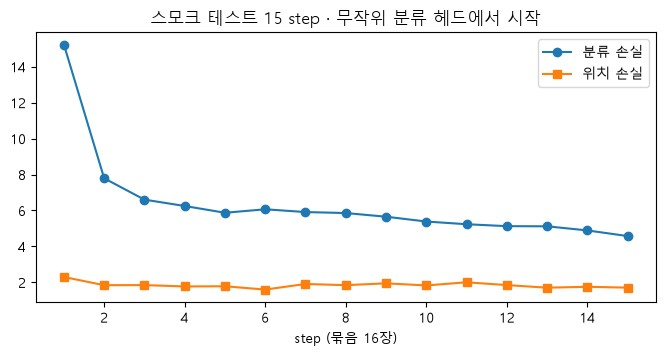

In [19]:
# 왜 · 학습 한 step을 함수로 묶어 스모크 · 본 학습에 같이 쓰기 위해
def train_step(model, images, targets, optimizer):                        # 묶음 하나로 한 번 학습
    images = [x.to(DEVICE) for x in images]                               # 사진 → 장치
    targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]  # 정답 → 장치
    loss_dict = model(images, targets)                                    # 학습 모드: 손실 두 가지
    loss = sum(loss_dict.values())                                        # 위치 + 분류
    optimizer.zero_grad()                                                 # 지난 기울기 지우기
    loss.backward()                                                       # 기울기
    optimizer.step()                                                      # 가중치 갱신
    return {k: v.item() for k, v in loss_dict.items()}                    # 숫자로


# 왜 · 긴 학습 전에 15 step으로 손실이 내려가는지 먼저 확인하기 위해
SMOKE_STEPS = 15                                                        # 15 step만
# 설정
smoke_opt = torch.optim.SGD(smoke_model.parameters(), lr=0.001, momentum=0.9, weight_decay=5e-4)
smoke_model.train()                                                     # 학습 모드
smoke_log, t0 = [], time.perf_counter()                                 # 기록 · 시작 시각
for step, (images, targets) in enumerate(train_loader, 1):              # 묶음마다
    losses = train_step(smoke_model, images, targets, smoke_opt)        # 한 step
    assert all(math.isfinite(v) for v in losses.values()), f"step {step}: {losses}"  # nan이면 멈춤
    smoke_log.append(losses)                                            # 기록
    if step in (1, 5, 10, 15):                                          # 네 번 출력
        print(f"step {step:2d} · 위치 {losses['bbox_regression']:.2f}"  # 위치 · 분류 손실
              f" · 분류 {losses['classification']:.2f}")
    if step == SMOKE_STEPS:                                             # 15 step이면
        break                                                           # 멈춤
smoke_seconds = time.perf_counter() - t0                                # 걸린 시간 (6-1에서 씀)

# 왜 · 스모크 학습 손실 곡선을 눈으로 확인하기 위해
fig, ax = plt.subplots(figsize=(8, 3.5))                                        # 손실 그림
ax.plot(range(1, 16), [r["classification"] for r in smoke_log], "o-", label="분류 손실")  # 분류
ax.plot(range(1, 16), [r["bbox_regression"] for r in smoke_log], "s-", label="위치 손실")  # 위치
ax.set_xlabel("step (묶음 16장)")                                               # x축
ax.set_title("스모크 테스트 15 step · 무작위 분류 헤드에서 시작", fontsize=12)  # 제목
ax.legend()                                                                     # 범례
plt.show()                                                                      # 그림 출력

**결과** · 예측 정답은 줄어듦 — 분류 `15.23 → 4.58`

- `step  1 · 위치 2.30 · 분류 15.23` — 무작위 헤드라 분류 손실이 큼
- `step 15 · 위치 1.71 · 분류 4.58` — 숫자로 나오고 내려감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>스모크 통과</td><td>당장 망가지지 않음</td><td>학습 시작 가능</td></tr>
<tr><td>잘 학습됨</td><td>val 점수로만</td><td>6 ~ 8장</td></tr>
<tr><td>nan</td><td>lr · 박스 문제</td><td>assert로 멈춤</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 스모크 통과 ≠ 잘 학습됨

> ✅ **한 줄 정리** · 15 step 스모크 테스트는 손실이 유한하고 내려가는지만 확인한다.

**딥러닝 코드에서는**

- `loss_dict = model(images, targets)` → `sum(loss_dict.values()).backward()`

### 5-3. `A` 잘못 뒤집은 박스는 잡히나 · `AssertionError` <sub>원본 D2-5 · 셀 124 · 125</sub>

> 🎯 **3-2의 뒤집기 식을 잘못 쓰면(x1' = W - x1) 스모크에서 잡히는가?**

💡 **쉽게 말하면**

- 모서리 순서가 뒤집힌 박스(x1 > x2)는 **학습 모드 첫 step에서 멈춤**.
- 증강을 켠 로더로 돌릴 때만 드러남.

**실행 흐름**

1. 잘못된 식으로 뒤집은 박스
2. 학습 모드로 손실 계산

**먼저 예측** · x1 > x2인 박스로 손실을 계산하면? — 답은 코드 실행 결과 아래에

In [20]:
stem = "Abyssinian_140"                                          # 4장에서 본 train 사진
x, t = TF.to_tensor(load_image(stem)), make_target(stem)         # 사진 · 정답
W = x.shape[-1]                                                  # 사진 폭
# 왜 · 잘못 뒤집은 박스(x1 > x2)를 모델이 첫 step에서 잡아내는지 확인하기 위해
bad = t["boxes"].clone()                                         # 복사
bad[:, [0, 2]] = W - t["boxes"][:, [0, 2]]                       # 잘못된 식: 양 끝을 따로 뒤집음
print("원래 박스        :", [round(v) for v in t["boxes"][0].tolist()])  # 원래
print("잘못 뒤집은 박스 :", [round(v) for v in bad[0].tolist()], "→ x1 > x2")  # 순서 뒤집힘
smoke_model.train()                                              # 학습 모드
try:
    with torch.no_grad():                                        # 손실만 확인
        # 계산
        smoke_model([x.to(DEVICE)], [{"boxes": bad.to(DEVICE), "labels": t["labels"].to(DEVICE)}])
except AssertionError as e:                                      # 멈춤
    print("학습 첫 step에서 멈춤 →", str(e).split(" Found")[0])  # 원인

원래 박스        : [231, 87, 323, 154]
잘못 뒤집은 박스 : [269, 87, 177, 154] → x1 > x2
학습 첫 step에서 멈춤 → All bounding boxes should have positive height and width.


**결과** · 예측 정답은 `AssertionError` — 학습 첫 step에서 멈춤

- `잘못 뒤집은 박스 : [269, 87, 177, 154] → x1 > x2` — 양 끝을 따로 뒤집음
- `학습 첫 step에서 멈춤 → All bounding boxes should have positive height and width.` — torchvision이 잡음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>사진만 뒤집기 (3-1)</td><td>에러 없음</td><td>그림 · IoU로만</td></tr>
<tr><td>양 끝 따로 뒤집기</td><td>AssertionError</td><td>스모크에서 잡힘</td></tr>
<tr><td>증강 끈 로더</td><td>통과</td><td>잡히지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 스모크는 RUN_B처럼 **증강을 켠 로더**로도 한 번 돌림

> ✅ **한 줄 정리** · 모서리 순서가 뒤집힌 박스는 torchvision이 학습 첫 step에서 멈춰 준다.

**딥러닝 코드에서는**

- torchvision 메시지: All bounding boxes should have positive height and width

### 5-4. `A` 확인 3 · 모드마다 돌려주는 것 · `model.train()` · `model.eval()` <sub>원본 D2-5 · 셀 126 ~ 131</sub>

> 🎯 **같은 모델이 학습 모드와 평가 모드에서 돌려주는 것은?**

💡 **쉽게 말하면**

- 학습 모드 = **손실 dict** · 평가 모드 = **사진마다 예측 dict의 list**.
- 평가 뒤 `train()`을 깜빡하면 학습 루프가 멈춤.

**실행 흐름**

1. 두 모드 반환 비교
2. 평가 모드 + 정답 → 예측
3. 학습 모드 + 정답 없음

**먼저 예측** · 평가 모드에 정답을 같이 주면 손실이 나올까? — 답은 코드 실행 결과 아래에

In [21]:
# 왜 · train · eval 모드에서 돌려주는 것이 다르다는 것을 확인하기 위해
xs = [x.to(DEVICE) for x in images[:2]]                                 # 방금 묶음에서 2장
ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets[:2]]     # 정답 2개
with torch.no_grad():                                                   # 비교만
    smoke_model.train()                                                 # 학습 모드
    out_train = smoke_model(xs, ts)                                     # 손실 dict
    smoke_model.eval()                                                  # 평가 모드
    out_eval = smoke_model(xs)                                          # 예측 list
print("학습 모드 →", type(out_train).__name__, list(out_train.keys()))  # dict
# list
print("평가 모드 →", type(out_eval).__name__, len(out_eval), "개 ·", list(out_eval[0].keys()))

with torch.no_grad():                    # 평가 뒤 train()을 깜빡한 상태
    out = smoke_model(xs, ts)            # 정답을 줘도 예측
print("평가 모드 + 정답 →", type(out).__name__, "(손실이 아니라 예측)")  # list
try:
    sum(out.values())                    # train_step 안의 그 줄
except AttributeError as e:              # 멈춤
    print("학습 루프에서 멈춤 →", e)     # 원인
smoke_model.train()                      # 학습 모드
try:
    smoke_model(xs)                      # 정답 없이
except AssertionError as e:              # 멈춤
    print("학습 모드 + 정답 없음 →", e)  # 원인

학습 모드 → dict ['bbox_regression', 'classification']
평가 모드 → list 2 개 · ['boxes', 'scores', 'labels']
평가 모드 + 정답 → list (손실이 아니라 예측)
학습 루프에서 멈춤 → 'list' object has no attribute 'values'
학습 모드 + 정답 없음 → targets should not be none when in training mode


**결과** · 예측 정답은 안 나옴 — 예측 list

- `학습 모드 → dict ['bbox_regression', 'classification']` — 손실 두 가지
- `평가 모드 → list 2 개 · ['boxes', 'scores', 'labels']` — 사진마다 예측
- `학습 루프에서 멈춤 → 'list' object has no attribute 'values'` — train() 깜빡
- `학습 모드 + 정답 없음 → targets should not be none when in training mode` — 정답 필요

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>train()</code> + 정답</td><td>손실 dict</td><td>학습</td></tr>
<tr><td><code>eval()</code></td><td>예측 list</td><td>평가 · 예측</td></tr>
<tr><td><code>train()</code> + 정답 없음</td><td>AssertionError</td><td>실수</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - epoch마다 평가한 뒤 `model.train()`으로 되돌림 (6-2 train_one_epoch 첫 줄)

> ✅ **한 줄 정리** · 탐지 모델은 모드에 따라 손실 dict와 예측 list를 돌려주므로, 평가 뒤에는 학습 모드로 되돌린다.

**딥러닝 코드에서는**

- `train_one_epoch` 첫 줄 `model.train()`

---
## 6. 학습 · 시간 · checkpoint

> **이 장의 흐름**
>
> - 5장 스모크 통과 → 진짜 학습
> - 시간 · lr 스케줄 · 루프 · val 점수 · 재현 · checkpoint

<img src="images/pfo2_ckpt.png" alt="epoch마다 val mAP50 · 최고 epoch만 best.pt" width="763">

**파이프라인 위치** · ⑤ 학습

### 6-1. `A` 시간 어림 · lr 스케줄 버그 · `StepLR` · `scheduler.step()` <sub>원본 D2-6 · 셀 133 ~ 138 · 142 ~ 148</sub>

> 🎯 **1 epoch는 몇 분이고, `scheduler.step()`을 빼면 lr은?**

💡 **쉽게 말하면**

- 스모크 시간으로 **1 epoch를 어림**하고 epoch 수를 정함.
- `step()`을 안 부르면 에러 없이 lr이 그대로 (미션 코드의 버그).

**실행 흐름**

1. 스모크 시간 → 1 epoch 어림
2. epoch 수 · step_size
3. lr 기록: step 없음 · epoch마다 · 묶음마다
4. lr 1e-26이면 가중치가 움직이나

**먼저 예측** · 묶음마다 `step()`을 부르면 lr은? — 답은 코드 실행 결과 아래에

In [22]:
# 왜 · 스모크 시간으로 본 학습 시간을 미리 어림하기 위해
sec_per_step = smoke_seconds / SMOKE_STEPS                                # 스모크 한 step 시간
steps_per_epoch = len(train_loader)                                       # 2569 ÷ 16 → 올림
guess = sec_per_step * steps_per_epoch                                    # 1 epoch 어림
print(f"train {len(train_ds):,}장 · 묶음 16장 → 1 epoch = {steps_per_epoch} step")  # 161
print(f"스모크로 어림한 1 epoch ≈ {guess / 60:.1f}분 (컴퓨터마다 다름)")  # 장치마다 다름

# 왜 · 원본 규칙대로 전체의 2/3 지점에서 lr을 낮추기 위해
EPOCHS = 4  # 원본 10 → 이 노트북은 두 번 학습 · 두 번 검증 실행을 위해 4로 줄임
STEP_SIZE = round(2 * EPOCHS / 3)  # 원본 규칙: 전체의 2/3 지점에서 lr 1/10
print(f"N = {EPOCHS} (원본 10) · step_size = round(2 × {EPOCHS} ÷ 3) = {STEP_SIZE}")  # 계획


# 왜 · 모델 없이 lr만 기록해 scheduler 실수를 빨리 확인하기 위해
def lr_log(call_step, n_epochs=EPOCHS, steps=steps_per_epoch):  # 학습 없이 lr만 기록
    w = torch.nn.Parameter(torch.zeros(1))                      # 가짜 파라미터
    opt = torch.optim.SGD([w], lr=0.001, momentum=0.9)          # 같은 lr
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP_SIZE, gamma=0.1)  # 같은 스케줄
    log = []                                                    # epoch마다 lr
    for _ in range(n_epochs):                                   # epoch마다
        log.append(opt.param_groups[0]["lr"])                   # 이번 epoch lr
        for _ in range(steps):                                  # 묶음마다
            opt.step()                                          # 빈 갱신
            if call_step == "batch":                            # 잘못된 자리
                sch.step()                                      # 묶음마다
        if call_step == "epoch":                                # 올바른 자리
            sch.step()                                          # epoch 끝마다
    return log                                                  # lr 목록


# 왜 · step() 위치에 따라 lr이 어떻게 바뀌는지 비교하기 위해
lr_runs = {"step() 없음 (미션 코드)": lr_log(None),                  # 세 가지 비교
           "epoch 끝마다 step()": lr_log("epoch"),
           "묶음마다 step()": lr_log("batch")}
for name, log in lr_runs.items():                                    # 줄마다
    print(f"{name:16s} lr " + "  ".join(f"{v:>6.0e}" for v in log))  # epoch별 lr

# 왜 · 학습 한 step 뒤 가중치가 실제로 바뀌는지 확인하기 위해
w = smoke_model.head.classification_head.module_list[0].weight  # 분류 헤드 첫 층
smoke_model.train()                                             # 학습 모드
for lr in (0.001, 1e-26):                                       # 두 lr
    before = w.detach().clone()                                 # 갱신 전
    # 1 step
    train_step(smoke_model, images, targets, torch.optim.SGD(smoke_model.parameters(), lr=lr))
    moved = (w.detach() - before).abs().max().item()            # 가장 크게 움직인 값
    print(f"lr {lr:.0e} → 분류 헤드 첫 층 가중치가 움직인 최대 크기 {moved:.1e}")  # 0이면 멈춤

train 2,569장 · 묶음 16장 → 1 epoch = 161 step
스모크로 어림한 1 epoch ≈ 5.8분 (컴퓨터마다 다름)
N = 4 (원본 10) · step_size = round(2 × 4 ÷ 3) = 3


step() 없음 (미션 코드) lr  1e-03   1e-03   1e-03   1e-03
epoch 끝마다 step() lr  1e-03   1e-03   1e-03   1e-04
묶음마다 step()      lr  1e-03   1e-56  1e-110  1e-164


lr 1e-03 → 분류 헤드 첫 층 가중치가 움직인 최대 크기 1.5e-04


lr 1e-26 → 분류 헤드 첫 층 가중치가 움직인 최대 크기 0.0e+00


**결과** · 예측 정답은 곧바로 거의 0 (`1e-56`)

- `train 2,569장 · 묶음 16장 → 1 epoch = 161 step` — 1 epoch 어림의 바탕
- `N = 4 (원본 10) · step_size = round(2 × 4 ÷ 3) = 3` — 2/3 지점에서 1/10
- `epoch 끝마다 step() lr  1e-03   1e-03   1e-03   1e-04` — 올바른 자리
- `묶음마다 step()      lr  1e-03   1e-56  1e-110  1e-164` — 학습이 멈춤
- `lr 1e-26 → 분류 헤드 첫 층 가중치가 움직인 최대 크기 0.0e+00` — 가중치가 안 움직임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>step()</code> 없음</td><td>lr 그대로</td><td>미션 코드 버그</td></tr>
<tr><td>epoch 끝마다</td><td>2/3 지점에서 1/10</td><td>올바름 (기본)</td></tr>
<tr><td>묶음마다</td><td>곧바로 거의 0</td><td>학습이 멈춤</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 원본은 10 epoch · step_size 7 → 이 노트북은 두 번 학습 · 두 번 검증을 위해 4 epoch · step_size 3

> ✅ **한 줄 정리** · lr 스케줄러는 epoch 끝마다 `step()`을 부르고, 실제로 줄었는지 epoch마다 lr을 기록해 확인한다.

**딥러닝 코드에서는**

- `for epoch ...: train_one_epoch(...); scheduler.step()`

### 6-2. `A` 학습 루프 · 예측 함수 · `train_one_epoch()` · `predict_all()` <sub>원본 D2-6 · 셀 139 ~ 141</sub>

> 🎯 **한 epoch 학습과 val 예측은 어떤 함수로 하는가?**

💡 **쉽게 말하면**

- 한 epoch = **train() → 묶음마다 train_step → 손실 평균**.
- 예측 = eval() → 사진마다 정답 · 예측 기록.

**실행 흐름**

1. train_one_epoch: 손실 평균 · step 기록
2. predict_all: 16장씩 예측 · 기록
3. val 2장으로 시험

**먼저 예측** · 15 step만 학습한 모델의 예측 수는 정답 수와 비슷할까? — 답은 코드 실행 결과 아래에

In [23]:
# 왜 · 평가 뒤에도 epoch마다 학습 모드로 돌아가 손실을 모으기 위해
def train_one_epoch(model, loader, optimizer, max_steps=None, history=None):  # 한 바퀴
    model.train()  # 평가 뒤에도 epoch마다 학습 모드로
    sums, seen_n = {"bbox_regression": 0.0, "classification": 0.0}, 0         # 손실 합 · 사진 수
    for step, (images, targets) in enumerate(loader, 1):                      # 묶음마다
        losses = train_step(model, images, targets, optimizer)                # 한 step
        assert all(math.isfinite(v) for v in losses.values()), f"step {step}: {losses}"  # nan?
        for k in sums:                                                        # 두 손실
            sums[k] += losses[k] * len(images)                                # 사진 수만큼 가중
        seen_n += len(images)                                                 # 사진 수
        if history is not None:                                               # 기록할 곳이 있으면
            history.append(losses)                                            # step 기록
        if max_steps and step >= max_steps:                                   # 일부만
            break                                                             # 멈춤
    return {k: v / seen_n for k, v in sums.items()}                           # 평균 손실


# 왜 · AP 계산에 필요한 예측을 낮은 신뢰도까지 한 번에 모으기 위해
def predict_all(model, ids, label_map=None, batch=16):  # 사진 목록 → 사진마다 정답 · 예측 기록
    model.eval()                                                                   # 평가 모드
    records = []                                                                   # 결과
    for k in range(0, len(ids), batch):                                            # 16장씩
        stems = ids[k:k + batch]                                                   # 이번 묶음
        with torch.no_grad():                                                      # 예측만
            outs = model([TF.to_tensor(load_image(s)).to(DEVICE) for s in stems])  # 예측
        for s, o in zip(stems, outs):                                              # 사진마다
            t = make_target(s)                                                     # 정답
            labs = o["labels"].tolist()                                            # 예측 라벨
            # 남길 줄
            keep = [i for i, lb in enumerate(labs) if label_map is None or lb in label_map]
            ours = [label_map[labs[i]] if label_map else labs[i] for i in keep]    # 우리 번호
            records.append({"id": s, "gt_boxes": t["boxes"].tolist(),              # 정답
                            "gt_labels": t["labels"].tolist(), "labels": ours,
                            "boxes": o["boxes"][keep].cpu().tolist(),
                            "scores": o["scores"][keep].cpu().tolist()})
    return records                                                                 # 사진 수만큼


# 왜 · 예측 기록 형식을 사진 두 장으로 먼저 확인하기 위해
pick = [sorted(val_ds.ids)[0], sorted(val_ds.ids)[-1]]  # val 고양이 1장 · 개 1장
rec = predict_all(smoke_model, pick)                    # 스모크 모델로 시험
print("기록 열쇠:", list(rec[0].keys()))                # 사진 하나의 기록
for r in rec:                                           # 사진마다
    print(f"{r['id']:22s} 정답 {len(r['gt_boxes'])}개 · 예측 {len(r['boxes'])}개")  # 예측은 많음

기록 열쇠: ['id', 'gt_boxes', 'gt_labels', 'labels', 'boxes', 'scores']
Abyssinian_101         정답 1개 · 예측 200개
yorkshire_terrier_190  정답 1개 · 예측 200개


**결과** · 예측 정답은 아님 — 정답 `1`개에 예측 `200`개 (사진당 최대치)

- `기록 열쇠: ['id', 'gt_boxes', 'gt_labels', 'labels', 'boxes', 'scores']` — 정답과 예측을 한 기록에
- `Abyssinian_101         정답 1개 · 예측 200개` — 점수 0.01 이상을 모두 남김
- `yorkshire_terrier_190  정답 1개 · 예측 200개` — 거르기는 채점할 때

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>train_one_epoch</code></td><td>손실 평균</td><td>학습</td></tr>
<tr><td><code>predict_all</code></td><td>사진마다 정답 · 예측</td><td>채점 재료</td></tr>
<tr><td><code>label_map</code></td><td>COCO 번호 → 우리 번호</td><td>학습 전 모델 (7-3)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 손실은 사진 수로 가중 평균 (마지막 묶음이 작아도 공정)

> ✅ **한 줄 정리** · 학습 루프는 train() 뒤 묶음마다 한 step씩 학습하고, 예측 함수는 사진마다 정답과 예측을 함께 기록한다.

**딥러닝 코드에서는**

- 예측 기록(json)은 7 ~ 10장에서 다시 계산 없이 씀

### 6-3. `A` val 점수 함수 (AP) · `judge()` · `ap_per_class()` <sub>원본 D2-6 · 셀 159 · D2-8 셀 214 ~ 216</sub>

> 🎯 **best epoch를 고를 val 점수는 어떻게 계산하는가?**

💡 **쉽게 말하면**

- Day01 9장 짝짓기 규칙 그대로 → **점수 순 · 같은 클래스 · 짝 없는 정답**.
- AP = 점수 기준을 끝까지 내리며 그린 PR 곡선 넓이 (8장에서 자세히).

**실행 흐름**

1. IoU
2. judge: 한 클래스 · 점수 순 짝짓기
3. ap_per_class: 클래스별 AP · mAP
4. 정답 그대로 · 스모크 모델로 시험

**먼저 예측** · 정답을 그대로 낸 기록의 mAP50은? — 답은 코드 실행 결과 아래에

In [24]:
# 왜 · IoU를 직접 계산해 채점 함수가 라이브러리 없이 돌게 하기 위해
def iou(a, b):                                       # 박스 두 개 → IoU (Day01 4장)
    w = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))  # 겹친 가로
    h = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))  # 겹친 세로
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - w * h  # 합친 넓이
    return w * h / union if union > 0 else 0.0       # 0 ~ 1


# 왜 · 정답 하나에 예측 하나만 짝지어 TP · FP를 판정하기 위해
def judge(records, cls, iou_thr, score_min=0.01):  # 한 클래스 · 점수 순 짝짓기 (Day01 9장 규칙)
    gts = {r["id"]: [b for b, lb in zip(r["gt_boxes"], r["gt_labels"]) if lb == cls]  # 정답
           for r in records}
    used = {k: set() for k in gts}                 # 짝 생긴 정답
    preds = [(s, r["id"], b) for r in records      # 이 클래스 · 하한 이상
             for b, lb, s in zip(r["boxes"], r["labels"], r["scores"])
             if lb == cls and s >= score_min]
    preds.sort(key=lambda p: -p[0])                # 점수 높은 순
    rows = []                                      # (점수, TP인가, IoU, 사진, 박스)
    for s, stem, b in preds:                       # 예측마다
        # 빈 정답 중
        best, j = max([(iou(b, g), j) for j, g in enumerate(gts[stem]) if j not in used[stem]],
                      default=(0.0, None))
        ok = j is not None and best >= iou_thr     # 기준 이상이면 TP
        if ok:                                     # TP면
            used[stem].add(j)                      # 그 정답은 다시 못 씀
        rows.append((s, ok, best, stem, b))        # 기록
    return rows, sum(map(len, gts.values()))       # 판정 · 정답 수


# 왜 · 클래스별 AP를 구해 val 점수로 쓰기 위해
def ap_per_class(records, iou_thr=0.5):                # 클래스별 AP (all-point) · mAP
    out = {}                                           # 결과
    for cls in (1, 2):                                 # 두 클래스
        rows, n_gt = judge(records, cls, iou_thr)      # 판정
        tp = np.cumsum([ok for _, ok, *_ in rows])     # 누적 TP
        r = np.concatenate([[0.0], tp / n_gt, [1.0]])  # 재현율
        p = np.concatenate([[0.0], tp / np.arange(1, len(rows) + 1), [0.0]])  # 정밀도
        p = np.maximum.accumulate(p[::-1])[::-1]       # 포락선
        # 넓이
        out[cls] = {"AP": float(np.sum((r[1:] - r[:-1]) * p[1:])), "GT": n_gt, "예측": len(rows)}
    out["mAP"] = (out[1]["AP"] + out[2]["AP"]) / 2     # 평균
    return out                                         # 클래스별 + mAP


# 왜 · 채점 함수가 맞는지 정답을 그대로 낸 경우로 검증하기 위해
print("50 밀린 박스 IoU:", round(iou([0, 0, 100, 100], [50, 0, 150, 100]), 4))  # Day01 4-1
perfect = [{**r, "boxes": r["gt_boxes"], "labels": r["gt_labels"],              # 정답을 그대로 예측
            "scores": [1.0] * len(r["gt_boxes"])} for r in rec]
print("정답 그대로 → mAP50:", ap_per_class(perfect)["mAP"])                     # 1.0
print("스모크 모델 → mAP50:", round(ap_per_class(rec)["mAP"], 4))               # 15 step 학습

50 밀린 박스 IoU: 0.3333
정답 그대로 → mAP50: 1.0
스모크 모델 → mAP50: 0.1705


**결과** · 예측 정답은 `1.0`

- `50 밀린 박스 IoU: 0.3333` — 파일별 1 4-1 손계산과 같음
- `정답 그대로 → mAP50: 1.0` — 모두 맞히면 1
- `스모크 모델 → mAP50: 0.1705` — 15 step만 학습한 모델은 낮음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>judge</code></td><td>예측마다 TP 여부</td><td>짝짓기</td></tr>
<tr><td><code>ap_per_class</code></td><td>클래스별 AP · 평균</td><td>val mAP50</td></tr>
<tr><td>all-point</td><td>포락선 아래 넓이</td><td>평가지표 보충 5장</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점수 0.01 이상 전부로 계산 → 점수 기준 0.5로 자르지 않음

> ✅ **한 줄 정리** · val mAP50은 IoU 0.5 짝짓기로 클래스별 AP를 구해 평균한 값이다.

**딥러닝 코드에서는**

- 공식 COCO 평가기와 구현은 다름 → 결과에 '우리 평가 함수'라고 적음

### 6-4. `A` RUN_A 학습 · `fit()` · `torch.save()` <sub>원본 D2-6 · 셀 141 · 152 ~ 155</sub>

> 🎯 **학습 한 번은 무엇을 저장하는가?**

💡 **쉽게 말하면**

- epoch마다 **학습 → lr 한 칸 → val 예측 · mAP50 → last 저장 → 최고면 best 저장**.
- 이미 학습한 기록이 있으면 불러와서 기다리지 않음.

**실행 흐름**

1. seed 0 · 새 모델 · SGD · StepLR
2. epoch마다 val 예측 json · mAP50
3. last.pt · best.pt · 기록 json

**먼저 예측** · 4 epoch 동안 val mAP50은 계속 오를까? — 답은 코드 실행 결과 아래에

In [25]:
# 왜 · 학습 · 평가 · 저장을 한 함수로 묶어 RUN마다 같은 절차를 쓰기 위해
def train_run(folder, flip):                                   # 학습 한 번 → 폴더에 저장
    folder.mkdir(exist_ok=True)                                # 폴더
    torch.manual_seed(0)  # 새 헤드 시작값 고정 → 두 학습의 출발점 같음
    model = make_mission_ssd().to(DEVICE)                      # COCO 몸통 + 3칸 헤드
    # 원본 설정
    opt = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9, weight_decay=5e-4)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP_SIZE, gamma=0.1)  # 2/3 지점에서 1/10
    gen = torch.Generator().manual_seed(0)                     # 섞는 순서 고정
    loader = DataLoader(PetFaces(train_ds.ids, flip=flip), batch_size=16, shuffle=True,  # 학습 묶음
                        num_workers=0, generator=gen, collate_fn=collate_fn)
    history, steps, best = [], [], -1.0                        # epoch 기록 · step 기록 · 최고 점수
    for epoch in range(1, EPOCHS + 1):                         # 1 ~ EPOCHS
        lr_used = opt.param_groups[0]["lr"]                    # 이번 epoch lr
        loss = train_one_epoch(model, loader, opt, history=steps)  # 학습
        sch.step()                                             # epoch 끝마다 한 번
        preds = predict_all(model, sorted(val_ds.ids))         # val 예측
        (folder / f"val_epoch{epoch}_predictions.json").write_text(json.dumps(preds))  # 10-2에서 씀
        m50 = ap_per_class(preds, 0.5)["mAP"]                  # val mAP50
        history.append({"epoch": epoch, "lr_used": lr_used, **loss, "mAP50": m50})  # 기록
        ck = {"model": model.state_dict(), "optimizer": opt.state_dict(),  # 이어 학습에 필요한 것
              "scheduler": sch.state_dict(), "epoch": epoch,
              "lr": opt.param_groups[0]["lr"], "loss": loss}
        torch.save(ck, folder / "last.pt")                     # last
        if m50 > best:                                         # best = val mAP50 최고
            best = m50                                         # 갱신
            torch.save(ck, folder / "best.pt")                 # best
    (folder / "history.json").write_text(json.dumps(history))  # 기록 저장
    (folder / "steps.json").write_text(json.dumps(steps))      # step 저장


# 왜 · 결과 파일이 있으면 다시 학습하지 않고 불러오기 위해
def fit(name, flip):  # 기록이 없으면 학습 · 있으면 불러옴 → (history, steps)
    folder = RUNS / name                                              # 결과 폴더
    if not (folder / "history.json").exists():  # 처음이면 (원본: 미리 학습해 둔 기록)
        train_run(folder, flip)                                       # 학습 · 저장
    history = json.loads((folder / "history.json").read_text())       # epoch 기록
    steps = json.loads((folder / "steps.json").read_text())           # step 기록
    for h in history:                                                 # 학습했든 불러왔든 같은 줄
        print(f"[{name}] epoch {h['epoch']} · lr {h['lr_used']:.0e}"  # 기록
              f" · 분류 {h['classification']:.3f} · val mAP50 {h['mAP50']:.4f}")
    return history, steps                                             # 결과


# 왜 · 뒤집기 없는 기준 학습을 먼저 얻기 위해
hist_A, steps_A = fit("RUN_A", flip=False)  # 뒤집기 없음 (GPU에서 약 30 ~ 40분 · 컴퓨터마다 다름)

[RUN_A] epoch 1 · lr 1e-03 · 분류 2.829 · val mAP50 0.9726
[RUN_A] epoch 2 · lr 1e-03 · 분류 1.301 · val mAP50 0.9658
[RUN_A] epoch 3 · lr 1e-03 · 분류 0.959 · val mAP50 0.9789
[RUN_A] epoch 4 · lr 1e-04 · 분류 0.670 · val mAP50 0.9877


**결과** · 예측 정답은 아님 — epoch 2에서 `0.9658`로 내려갔다가 다시 오름

- `[RUN_A] epoch 1 · lr 1e-03 · 분류 2.829 · val mAP50 0.9726` — 1 epoch만에 높음 (COCO 몸통 덕분)
- `[RUN_A] epoch 2 · lr 1e-03 · 분류 1.301 · val mAP50 0.9658` — 손실은 줄었는데 val은 내려감
- `[RUN_A] epoch 4 · lr 1e-04 · 분류 0.670 · val mAP50 0.9877` — lr을 줄인 뒤 최고

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>last.pt</td><td>마지막 epoch</td><td>이어 학습</td></tr>
<tr><td>best.pt</td><td>val mAP50 최고 epoch</td><td>평가 · 배포</td></tr>
<tr><td>history · steps json</td><td>epoch · step 기록</td><td>다시 학습 없이 그림</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - best는 val로만 고름 → test는 11장에서 한 번

> ✅ **한 줄 정리** · 학습은 epoch마다 val 점수를 기록하고 last와 best를 따로 저장한다.

**딥러닝 코드에서는**

- GPU에서 4 epoch 약 30 ~ 40분 (컴퓨터 · 동시 작업에 따라 다름)

### 6-5. `A` 같은 설정 20 step · 기록 읽기 · `history` <sub>원본 D2-6 · 셀 149 ~ 159</sub>

> 🎯 **같은 시작 · 같은 순서로 20 step을 다시 돌리면 RUN_A 숫자와 같은가?**

💡 **쉽게 말하면**

- seed · 섞는 순서 · 시작 가중치가 같으면 **같은 숫자**가 나와야 재현.
- train 손실이 계속 내려가도 best는 val로 고름.

**실행 흐름**

1. 새 모델로 20 step
2. RUN_A step 기록과 비교
3. epoch 기록 표
4. best · last

**먼저 예측** · 20 step 중 가장 큰 차이는 0일까? — 답은 코드 실행 결과 아래에

In [26]:
torch.manual_seed(0)                                                 # RUN_A와 같은 시작
live_model = make_mission_ssd().to(DEVICE)                           # COCO 몸통 + 새 3칸 헤드
# 같은 설정
live_opt = torch.optim.SGD(live_model.parameters(), lr=0.001, momentum=0.9, weight_decay=5e-4)
replay_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0,  # 같은 섞기
                           collate_fn=collate_fn, generator=torch.Generator().manual_seed(0))
live_log = []                                                        # step 기록
train_one_epoch(live_model, replay_loader, live_opt, max_steps=20, history=live_log)  # 20 step만
print("step | 지금 분류 · 위치    | RUN_A 분류 · 위치")              # 표 머리
for i in (0, 4, 9, 14, 19):                                          # 다섯 줄
    a, mine = steps_A[i], live_log[i]                                # 같은 step
    print(f"{i + 1:4d} | {mine['classification']:6.3f} · {mine['bbox_regression']:.3f}"  # 지금
          f"      | {a['classification']:6.3f} · {a['bbox_regression']:.3f}")  # RUN_A
gap = max(abs(mine[k] - a[k]) for a, mine in zip(steps_A, live_log)  # 가장 큰 차이
          for k in ("classification", "bbox_regression"))
print(f"20 step 중 가장 큰 차이: {gap:.1e}")                         # 0이면 재현
del live_model, live_opt                                             # 메모리 비우기

# 왜 · epoch마다 손실 · lr · val 점수를 한 표로 확인하기 위해
print("epoch | 위치 손실 | 분류 손실 | 쓴 lr  | val mAP50")                 # 표 머리
for h in hist_A:                                                            # epoch마다
    print(f"{h['epoch']:5d} | {h['bbox_regression']:9.3f} | {h['classification']:9.3f}"  # 한 줄
          f" | {h['lr_used']:.0e} | {h['mAP50']:.4f}")
best_A = max(hist_A, key=lambda h: h["mAP50"])                              # val로 고른 best
# best · last
print(f"best = epoch {best_A['epoch']} (val mAP50 {best_A['mAP50']:.4f}) · last = epoch"
      f" {hist_A[-1]['epoch']} (val mAP50 {hist_A[-1]['mAP50']:.4f}) · test 사용: False")
same_lr = [h["lr_used"] for h in hist_A] == lr_runs["epoch 끝마다 step()"]  # 기록과 비교
print("RUN_A가 쓴 lr이 'epoch 끝마다'와 같은가:", same_lr)                  # True

step | 지금 분류 · 위치    | RUN_A 분류 · 위치
   1 | 15.828 · 2.156      | 15.828 · 2.156
   5 |  5.963 · 1.939      |  5.963 · 1.939
  10 |  5.412 · 1.781      |  5.412 · 1.781
  15 |  4.673 · 1.833      |  4.673 · 1.833
  20 |  4.206 · 1.848      |  4.206 · 1.848
20 step 중 가장 큰 차이: 0.0e+00
epoch | 위치 손실 | 분류 손실 | 쓴 lr  | val mAP50
    1 |     0.785 |     2.829 | 1e-03 | 0.9726
    2 |     0.311 |     1.301 | 1e-03 | 0.9658
    3 |     0.233 |     0.959 | 1e-03 | 0.9789
    4 |     0.128 |     0.670 | 1e-04 | 0.9877
best = epoch 4 (val mAP50 0.9877) · last = epoch 4 (val mAP50 0.9877) · test 사용: False
RUN_A가 쓴 lr이 'epoch 끝마다'와 같은가: True


**결과** · 예측 정답은 `0` — 같은 숫자

- `   1 | 15.828 · 2.156      | 15.828 · 2.156` — 같은 시작
- `20 step 중 가장 큰 차이: 0.0e+00` — 재현됨
- `best = epoch 4 (val mAP50 0.9877) · last = epoch 4 (val mAP50 0.9877) · test 사용: False` — 이번에는 best = last
- `RUN_A가 쓴 lr이 'epoch 끝마다'와 같은가: True` — 스케줄이 실제로 줄였음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>train 손실</td><td>계속 내려감</td><td>best를 못 고름</td></tr>
<tr><td>val mAP50</td><td>epoch마다 오르내림</td><td>best 고르기</td></tr>
<tr><td>lr 기록</td><td>epoch마다</td><td>스케줄 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - GPU 계산은 cudnn.deterministic으로 고정 → 고정하지 않으면 작은 차이가 날 수 있음

> ✅ **한 줄 정리** · 같은 seed와 순서면 학습이 재현되고, best epoch는 train 손실이 아니라 val 점수로 고른다.

**딥러닝 코드에서는**

- 원본: epoch 7 best (val mAP50 0.9919) · 10 epoch

### 6-6. `A` checkpoint 열기 · 다시 불러오기 · `torch.load()` · `load_state_dict()` <sub>원본 D2-6 · 셀 160 ~ 172</sub>

> 🎯 **best.pt 안에는 무엇이 있고, 다시 불러오면 같은 답이 나오는가?**

💡 **쉽게 말하면**

- checkpoint = **model · optimizer · scheduler · epoch · lr · loss**.
- 이어 학습하려면 셋 다 불러와야 lr · momentum이 이어짐.

**실행 흐름**

1. 열쇠 · 저장된 lr · scheduler 상태
2. 불러오기 함수 · 모델 안 설정
3. 두 번 불러온 출력 비교
4. 새 optimizer vs checkpoint로 채운 optimizer

**먼저 예측** · best.pt에 적힌 lr은? — 답은 코드 실행 결과 아래에

In [27]:
# 왜 · 저장 파일 안에 무엇이 들어 있는지 열어 보기 위해
best_path = RUNS / "RUN_A" / "best.pt"                                # best 파일
ckpt = torch.load(best_path, map_location="cpu", weights_only=False)  # 내가 만든 파일만 이렇게 엶
print("들어 있는 것:", list(ckpt.keys()))                             # 열쇠
print(f"epoch {ckpt['epoch']} · 저장된 lr {ckpt['lr']} · 손실",       # 저장 직후 상태
      {k: round(v, 3) for k, v in ckpt["loss"].items()})
# 스케줄
print("scheduler:", {k: ckpt["scheduler"][k] for k in ("step_size", "gamma", "last_epoch")})
# 크기
print(f"model 텐서 {len(ckpt['model'])}개 · optimizer 상태 {len(ckpt['optimizer']['state'])}개"
      f" · 파일 {best_path.stat().st_size / 1e6:.0f} MB")


# 왜 · 같은 구조를 먼저 만들고 저장한 값을 채워 모델을 되살리기 위해
def load_run(name):                 # RUN 폴더의 best.pt → 평가 모드 모델
    ck = torch.load(RUNS / name / "best.pt", map_location="cpu", weights_only=False)  # 파일
    m = make_mission_ssd()          # 같은 구조를 먼저 만들고
    m.load_state_dict(ck["model"])  # 저장된 값을 채움
    return m.to(DEVICE).eval()      # 장치 · 평가 모드


# 왜 · 불러온 모델의 설정이 저장할 때와 같은지 확인하기 위해
model_A = load_run("RUN_A")                                               # RUN_A best
# 모델 안 설정
print("RUN_A best 불러옴 · 점수 기준", model_A.score_thresh, "· NMS IoU", model_A.nms_thresh,
      "· 사진당 최대", model_A.detections_per_img)
ref_id = sorted(val_ds.ids)[0]                                            # val 첫 사진 (test 아님)
with torch.no_grad():                                                     # 두 번 예측
    p1 = model_A([TF.to_tensor(load_image(ref_id)).to(DEVICE)])[0]        # 첫 번째
    p2 = load_run("RUN_A")([TF.to_tensor(load_image(ref_id)).to(DEVICE)])[0]  # 다시 불러온 모델
same_out = {k: torch.equal(p1[k], p2[k]) for k in p1}                     # 열쇠마다 같은가
print("사진", ref_id, "(val) · 두 번 불러온 출력이 똑같은가:", same_out)  # 모두 True

# 왜 · 이어 학습하려면 optimizer · scheduler도 되살려야 하기 때문에
resume_opt = torch.optim.SGD(model_A.parameters(), lr=0.001, momentum=0.9,  # 새로 만듦
                             weight_decay=5e-4)
# 새 스케줄
resume_sch = torch.optim.lr_scheduler.StepLR(resume_opt, step_size=STEP_SIZE, gamma=0.1)
lr_now = resume_opt.param_groups[0]["lr"]                                   # 처음 lr
print("새로 만든 그대로  → lr", lr_now, "· momentum 기억", len(resume_opt.state), "개")  # 빈 기억
resume_opt.load_state_dict(ckpt["optimizer"])                               # checkpoint에서 채움
resume_sch.load_state_dict(ckpt["scheduler"])                               # 스케줄도
lr_now = resume_opt.param_groups[0]["lr"]                                   # 채운 lr
print("checkpoint로 채움 → lr", lr_now, "· momentum 기억", len(resume_opt.state),  # 이어 갈 준비
      "개 · 다음 epoch", ckpt["epoch"] + 1)
del resume_opt, resume_sch                                                  # 확인만

들어 있는 것: ['model', 'optimizer', 'scheduler', 'epoch', 'lr', 'loss']
epoch 4 · 저장된 lr 0.0001 · 손실 {'bbox_regression': 0.128, 'classification': 0.67}
scheduler: {'step_size': 3, 'gamma': 0.1, 'last_epoch': 4}
model 텐서 71개 · optimizer 상태 67개 · 파일 191 MB


RUN_A best 불러옴 · 점수 기준 0.01 · NMS IoU 0.45 · 사진당 최대 200


사진 Abyssinian_101 (val) · 두 번 불러온 출력이 똑같은가: {'boxes': True, 'scores': True, 'labels': True}
새로 만든 그대로  → lr 0.001 · momentum 기억 0 개
checkpoint로 채움 → lr 0.0001 · momentum 기억 67 개 · 다음 epoch 5


**결과** · 예측 정답은 `0.0001` — 저장 직전에 step()이 불림

- `들어 있는 것: ['model', 'optimizer', 'scheduler', 'epoch', 'lr', 'loss']` — 이어 학습에 필요한 것
- `model 텐서 71개 · optimizer 상태 67개 · 파일 191 MB` — optimizer 상태까지 들어 있음
- `두 번 불러온 출력이 똑같은가: {'boxes': True, 'scores': True, 'labels': True}` — 같은 답
- `새로 만든 그대로  → lr 0.001 · momentum 기억 0 개` — 처음으로 돌아감
- `checkpoint로 채움 → lr 0.0001 · momentum 기억 67 개 · 다음 epoch 5` — 그대로 이어 감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>가중치만</td><td>평가 · 예측</td><td><code>model.load_state_dict</code></td></tr>
<tr><td>+ optimizer</td><td>momentum 기억</td><td>이어 학습</td></tr>
<tr><td>+ scheduler</td><td>lr 일정</td><td>이어 학습</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `weights_only=False`는 내가 만든 파일에만 (모르는 파일은 코드 실행 위험)

> ✅ **한 줄 정리** · checkpoint는 모델 · optimizer · scheduler 상태를 함께 저장하고, 다시 불러오면 같은 출력이 나온다.

**딥러닝 코드에서는**

- 이어 학습 = 세 상태 load → `range(ckpt["epoch"] + 1, ...)`

---
## 7. 예측 · 집계 · val 551장

> **이 장의 흐름**
>
> - 6장 best 모델 → val 예측 한 번
> - 클래스별 채점 · 학습 전 비교 · 점수 기준 · 평가 IoU

<img src="images/pfo2_thresh.png" alt="예측은 한 번 · 채점 기준만 바꿔 다시 셈" width="762">

**파이프라인 위치** · ⑥ 평가 — 정밀도 · 재현율

### 7-1. `A` 채점 준비 · 사진 한 장의 기록 · `predict_all()` <sub>원본 D2-7 · 셀 173 ~ 183</sub>

> 🎯 **어제는 8장, 오늘은 val 551장 전부 — 예측은 몇 개가 나오는가?**

💡 **쉽게 말하면**

- 예측은 **한 번만** 하고 점수 0.01 이상을 전부 저장.
- 거르기는 채점할 때 기준을 바꿔 가며.

**실행 흐름**

1. 채점할 사진 · 모델 · 모델 안 설정
2. val 예측 · 정답 수 · 0.5 위아래
3. 예측 3개 이상인 사진 한 장

**먼저 예측** · 예측 박스는 정답 551개보다 많을까? — 답은 코드 실행 결과 아래에

채점할 사진: val 551 장 · test는 쓰지 않음
모델: RUN_A best = epoch 4 (val로 고름) · 모델 안 설정: {'score_thresh': 0.01, 'nms_thresh': 0.45, 'detections_per_img': 200}


정답 박스: 551 개
예측 박스: 31338 개 = 점수 0.5 이상 556 + 0.5 미만 30782
Abyssinian_101 · 정답: ['고양이 얼굴'] [[54, 36, 319, 235]]
  예측 고양이 얼굴 점수 0.990 박스 [54, 45, 299, 235]
  예측 고양이 얼굴 점수 0.034 박스 [176, 64, 311, 223]
  예측 개 얼굴   점수 0.016 박스 [0, 310, 13, 313]
  예측 개 얼굴   점수 0.016 박스 [445, 1, 450, 13]


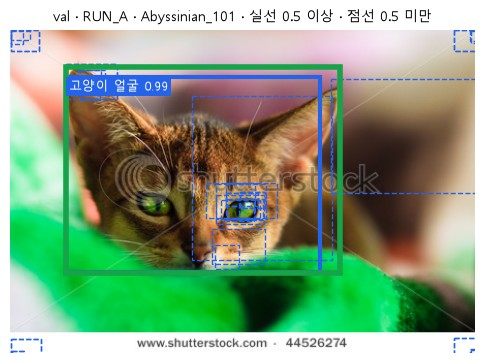

In [28]:
# 왜 · 모든 채점이 같은 val 사진 순서를 쓰게 하기 위해
VAL_IDS = sorted(val_ds.ids)                                      # val 551장 · 이름 순
# 모델 안
SETTINGS_A = {k: getattr(model_A, k) for k in ("score_thresh", "nms_thresh", "detections_per_img")}
A_EPOCH = ckpt["epoch"]                                           # best epoch
print("채점할 사진: val", len(VAL_IDS), "장 · test는 쓰지 않음")  # val만
print(f"모델: RUN_A best = epoch {A_EPOCH} (val로 고름) · 모델 안 설정:", SETTINGS_A)  # 조건

# 왜 · val 전체 예측을 한 번 모아 여러 채점에 다시 쓰기 위해
preds_A_val = predict_all(model_A, VAL_IDS)             # 한 번만 계산 → 8 · 9장에서 다시 씀
n_gt = sum(len(r["gt_boxes"]) for r in preds_A_val)     # 정답 수
scores = [s for r in preds_A_val for s in r["scores"]]  # 모든 예측 점수
print("정답 박스:", n_gt, "개")                         # 551
print("예측 박스:", len(scores), "개 = 점수 0.5 이상", sum(s >= 0.5 for s in scores),  # 0.5 위아래
      "+ 0.5 미만", sum(s < 0.5 for s in scores))

# 왜 · 사진 한 장의 기록에 무엇이 들어 있는지 직접 보기 위해
stem = next(r["id"] for r in preds_A_val if len(r["boxes"]) >= 3)  # 예측 3개 이상인 첫 사진
r = {p["id"]: p for p in preds_A_val}[stem]                                      # 그 기록
gt_show = [[round(v) for v in b] for b in r["gt_boxes"]]                         # 정답 박스
print(stem, "· 정답:", [CLASSES[lb] for lb in r["gt_labels"]], gt_show)          # 정답
for b, lb, s in zip(r["boxes"][:4], r["labels"][:4], r["scores"][:4]):           # 앞 4개
    print(f"  예측 {CLASSES[lb]:6s} 점수 {s:.3f} 박스 {[round(v) for v in b]}")  # 한 줄
hi = [i for i, s in enumerate(r["scores"]) if s >= 0.5]                          # 0.5 이상
lo = [i for i, s in enumerate(r["scores"]) if s < 0.5]                           # 0.5 미만
names_hi = [f"{CLASSES[r['labels'][i]]} {r['scores'][i]:.2f}" for i in hi]       # 이름표
draw(load_image(stem), gt=r["gt_boxes"], pred=[r["boxes"][i] for i in hi],       # 실선 · 점선
     cand=[r["boxes"][i] for i in lo], labels=names_hi,
     title=f"val · RUN_A · {stem} · 실선 0.5 이상 · 점선 0.5 미만")
plt.show()                                                                       # 그림 출력

**결과** · 예측 정답은 많음 — `31338`개

- `정답 박스: 551 개` — 사진마다 대부분 1개
- `예측 박스: 31338 개 = 점수 0.5 이상 556 + 0.5 미만 30782` — 0.5 이상은 정답 수와 비슷
- `예측 고양이 얼굴 점수 0.990 박스 [54, 45, 299, 235]` — 정답 [54, 36, 319, 235]과 거의 같은 자리

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>모델 안 점수 기준</td><td>0.01</td><td>거의 전부 저장</td></tr>
<tr><td>채점 점수 기준</td><td>0.5 · 0.3 · 0.7</td><td>바꿔 가며</td></tr>
<tr><td>NMS 0.45 · 최대 200</td><td>모델 안 설정</td><td>그대로</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 0.5 미만 박스 = 같은 자리 다른 클래스 · 엉뚱한 자리 → 채점 때 점수 기준으로 걸러짐

> ✅ **한 줄 정리** · 예측은 모델마다 한 번 저장하고, 채점 기준은 저장한 예측에 바꿔 가며 적용한다.

**딥러닝 코드에서는**

- `json.dumps(records)` → 다시 예측 없이 채점

### 7-2. `A` 채점 · 클래스별 · `match()` · `show()` <sub>원본 D2-7 · 셀 184 ~ 191</sub>

> 🎯 **어제와 같은 짝짓기 규칙으로 val 551장을 채점하면?**

💡 **쉽게 말하면**

- Day01 9장과 같은 기준 (**점수 0.5 · 평가 IoU 0.5**).
- 클래스별로 따로 세고 합계도 냄.

**실행 흐름**

1. 점수 기준 이상만 판정 → TP · FP · FN
2. 클래스별 · 합계 정밀도 · 재현율 · F1

**먼저 예측** · 학습 후 재현율은 0.9를 넘을까? — 답은 코드 실행 결과 아래에

In [29]:
# 왜 · 점수 기준 · IoU 기준을 바꿔 가며 TP · FP · FN을 세기 위해
def match(records, score_thr, iou_thr):  # 점수 기준 이상만 채점 → 클래스별 개수
    counts = {}                                                                      # 결과
    for cls in (1, 2):                                                               # 두 클래스
        rows, n_gt = judge(records, cls, iou_thr, score_min=score_thr)               # 판정
        tp = sum(ok for _, ok, *_ in rows)                                           # TP
        counts[cls] = {"TP": tp, "FP": len(rows) - tp, "FN": n_gt - tp, "GT": n_gt}  # 네 숫자
    return counts                                                                    # 클래스별


# 왜 · 클래스별 채점 결과를 같은 형식으로 출력하기 위해
def show(counts, title):                                                # 클래스별 · 합계 한 줄씩
    print(title)                                                        # 조건
    both = {k: counts[1][k] + counts[2][k] for k in ("TP", "FP", "FN", "GT")}  # 합계
    # 세 줄
    for name, c in [(CLASSES[1], counts[1]), (CLASSES[2], counts[2]), ("두 클래스 합", both)]:
        p, r_ = c["TP"] / max(c["TP"] + c["FP"], 1), c["TP"] / c["GT"]  # 정밀도 · 재현율
        f1 = 2 * p * r_ / (p + r_) if p + r_ else 0.0                   # F1
        # 한 줄
        print(f"  {name:7s} GT {c['GT']:3d} | TP {c['TP']:3d} FP {c['FP']:4d} FN {c['FN']:3d}"
              f" | 정밀도 {p:.3f} 재현율 {r_:.3f} F1 {f1:.3f}")


# 왜 · 실제로 쓸 기준 0.5에서 RUN_A 성능을 먼저 보기 위해
show(match(preds_A_val, score_thr=0.5, iou_thr=0.5),  # Day01과 같은 기준
     f"split=val · RUN_A epoch {A_EPOCH} · 점수 기준 0.5 · 평가 IoU 0.5")

split=val · RUN_A epoch 4 · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    5 FN   4 | 정밀도 0.972 재현율 0.977 F1 0.975
  개 얼굴    GT 375 | TP 367 FP   12 FN   8 | 정밀도 0.968 재현율 0.979 F1 0.973
  두 클래스 합 GT 551 | TP 539 FP   17 FN  12 | 정밀도 0.969 재현율 0.978 F1 0.974


**결과** · 예측 정답은 넘음 — `0.978`

- `고양이 얼굴  GT 176 | TP 172 FP    5 FN   4` — 고양이 정밀도 0.972
- `개 얼굴    GT 375 | TP 367 FP   12 FN   8` — 개 재현율 0.979
- `두 클래스 합 GT 551 | TP 539 FP   17 FN  12 | 정밀도 0.969 재현율 0.978 F1 0.974` — 어제 8장과 같은 기준

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>고양이 얼굴</td><td>GT가 적음</td><td>클래스별로 따로</td></tr>
<tr><td>개 얼굴</td><td>GT가 많음</td><td>합계를 끌어감</td></tr>
<tr><td>두 클래스 합</td><td>전체</td><td>보고</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 분모(GT 수)를 같이 적어야 같은 재현율도 비교 가능

> ✅ **한 줄 정리** · 학습한 RUN_A는 어제와 같은 기준에서 정밀도 · 재현율이 모두 높다.

**딥러닝 코드에서는**

- 결과 = 숫자 + split · run · epoch · 점수 기준 · 평가 IoU · 분모

### 7-3. `A` 학습 전 COCO와 비교 · `label_map` <sub>원본 D2-7 · 셀 192 ~ 198</sub>

> 🎯 **학습 전 COCO SSD를 같은 기준으로 채점하면?**

💡 **쉽게 말하면**

- COCO 모델은 **몸 전체**에 박스 → 머리 정답과 IoU가 낮음.
- 같은 val · 같은 기준이라 비교 가능.

**실행 흐름**

1. COCO cat · dog → 우리 번호
2. 같은 기준으로 채점
3. 같은 사진 4장: 학습 전 vs 학습 후

**먼저 예측** · 학습 전 재현율은? — 답은 코드 실행 결과 아래에

COCO 번호 → 우리 번호: {17: 1, 18: 2}


split=val · COCO SSD (학습 전) · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP  18 FP  156 FN 158 | 정밀도 0.103 재현율 0.102 F1 0.103
  개 얼굴    GT 375 | TP  57 FP  305 FN 318 | 정밀도 0.157 재현율 0.152 F1 0.155
  두 클래스 합 GT 551 | TP  75 FP  461 FN 476 | 정밀도 0.140 재현율 0.136 F1 0.138


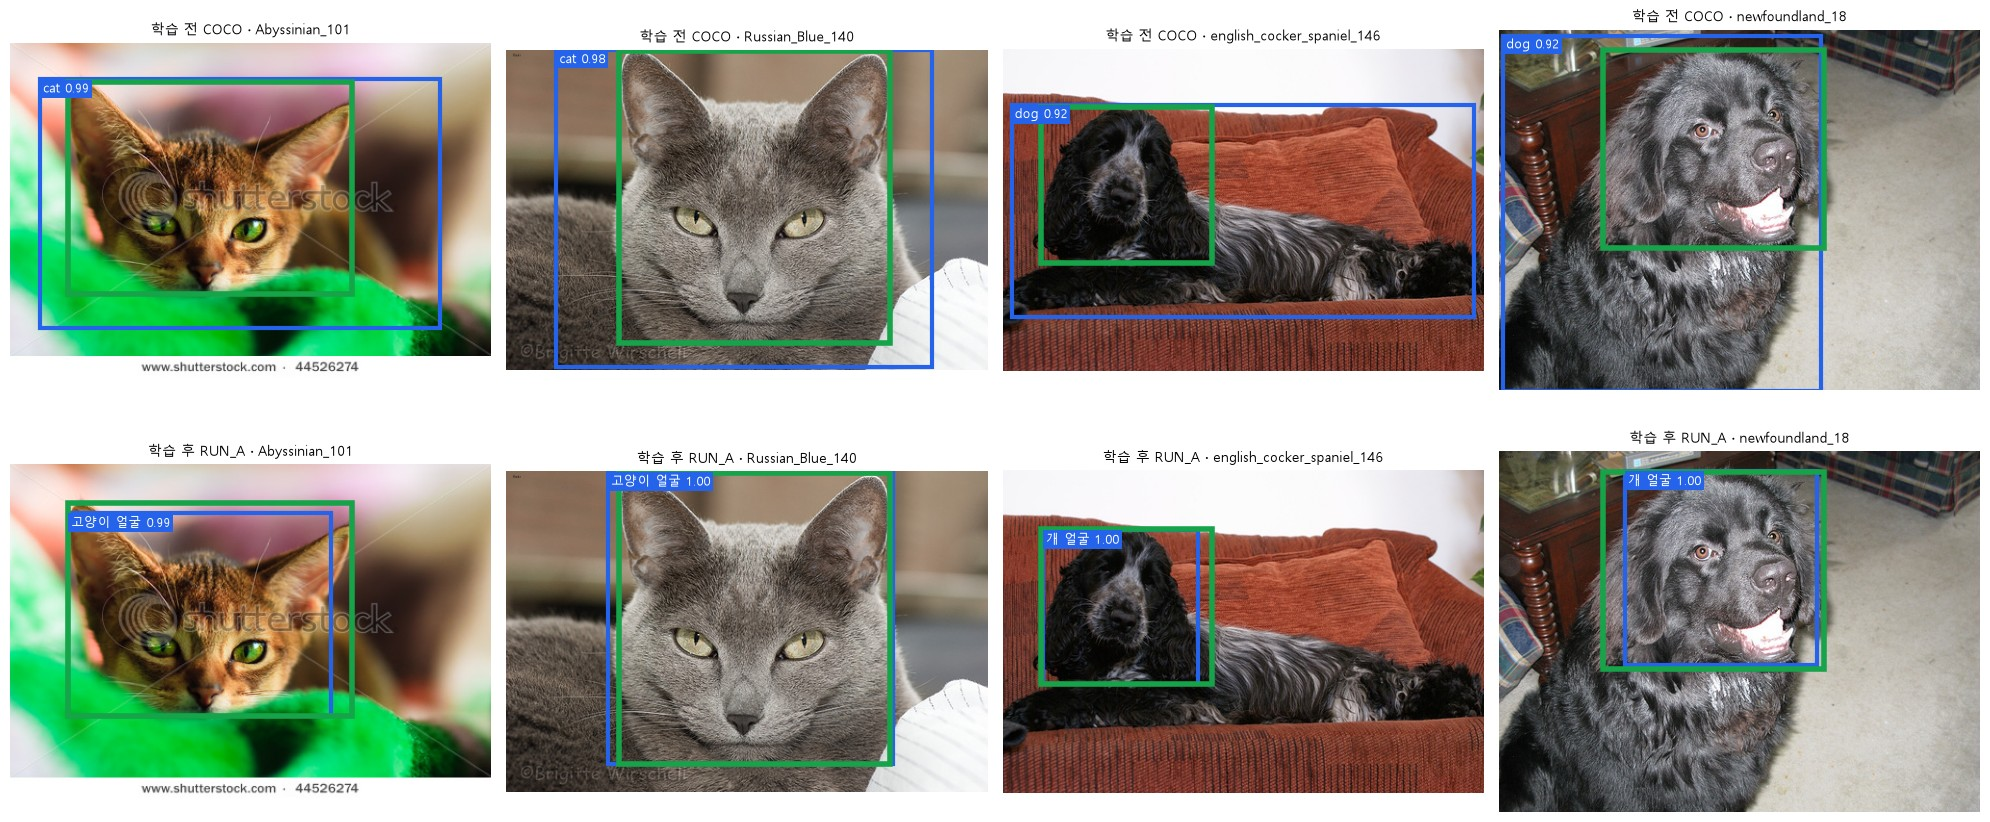

In [30]:
# 왜 · 학습 효과를 재려면 학습 전 기준선이 필요하기 때문에
coco_ssd = ssd300_vgg16(weights=SSD_W).eval().to(DEVICE)                 # 우리 데이터로 학습하기 전
COCO_TO_OURS = {COCO_NAMES.index("cat"): 1, COCO_NAMES.index("dog"): 2}  # 나머지 COCO 클래스는 버림
print("COCO 번호 → 우리 번호:", COCO_TO_OURS)                            # 17 → 1 · 18 → 2
preds_coco_val = predict_all(coco_ssd, VAL_IDS, label_map=COCO_TO_OURS)  # 한 번만
show(match(preds_coco_val, score_thr=0.5, iou_thr=0.5),                  # 같은 기준
     "split=val · COCO SSD (학습 전) · 점수 기준 0.5 · 평가 IoU 0.5")

# 왜 · 같은 val 사진에서 학습 전 · 후 예측을 눈으로 비교하기 위해
picks = VAL_IDS[::138][:4]                       # 138장 간격 4장 (결과 보고 고르지 않음)
fig, axes = plt.subplots(2, 4, figsize=(20, 9))  # 위 = 학습 전 · 아래 = 학습 후
# 두 모델
for row, (name, recs, names) in enumerate([("학습 전 COCO", preds_coco_val, ["", "cat", "dog"]),
                                           ("학습 후 RUN_A", preds_A_val, CLASSES)]):
    by_id = {p["id"]: p for p in recs}           # 이름으로 찾기
    for ax, s in zip(axes[row], picks):          # 사진마다
        r = by_id[s]                             # 기록
        keep = [i for i, v in enumerate(r["scores"]) if v >= 0.5]  # 0.5 이상
        labs = [f"{names[r['labels'][i]]} {r['scores'][i]:.2f}" for i in keep]  # 이름표
        # 정답 · 예측
        draw(load_image(s), gt=r["gt_boxes"], pred=[r["boxes"][i] for i in keep], ax=ax,
             labels=labs, title=f"{name} · {s}")
plt.tight_layout()                               # 여백
plt.show()                                       # 그림 출력

**결과** · 예측 정답은 `0.136`

- `COCO 번호 → 우리 번호: {17: 1, 18: 2}` — cat · dog만 남김
- `두 클래스 합 GT 551 | TP  75 FP  461 FN 476 | 정밀도 0.140 재현율 0.136 F1 0.138` — 몸 박스라 대부분 FP · FN

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>학습 전 COCO</td><td>몸 박스</td><td>재현율 낮음</td></tr>
<tr><td>학습 후 RUN_A</td><td>얼굴 박스</td><td>재현율 높음</td></tr>
<tr><td>사진 고르기</td><td>138장 간격</td><td>결과 보고 고르지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 사진을 결과 보고 고르면 비교가 기울어짐 → 간격으로 고정

> ✅ **한 줄 정리** · 같은 val과 기준에서 학습 전 COCO는 재현율이 낮고, 머리로 학습한 모델은 대부분 맞힌다.

**딥러닝 코드에서는**

- 어제 8장 (재현율 0.25)과 같은 경향 · 분모만 551로

### 7-4. `A` 점수 기준을 바꾸면 · `score_thr` <sub>원본 D2-7 · 셀 199 ~ 208</sub>

> 🎯 **점수 기준을 0.3 · 0.5 · 0.7로 바꾸면 정밀도 · 재현율은?**

💡 **쉽게 말하면**

- 점수 기준 ↑ → **FP ↓ · FN ↑** → 정밀도 ↑ · 재현율 ↓.
- 기준 하나로는 모델을 한 숫자로 말하기 어려움.

**실행 흐름**

1. 세 기준 표
2. 기준 19개의 F1 · 가장 높은 기준
3. 클래스별 곡선
4. 학습 전 모델은 기준을 내리면 될까

**먼저 예측** · 기준을 0.3에서 0.7로 올리면 FP와 FN은? — 답은 코드 실행 결과 아래에

split=val · RUN_A · 점수 기준 0.3 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    6 FN   4 | 정밀도 0.966 재현율 0.977 F1 0.972
  개 얼굴    GT 375 | TP 371 FP   21 FN   4 | 정밀도 0.946 재현율 0.989 F1 0.967
  두 클래스 합 GT 551 | TP 543 FP   27 FN   8 | 정밀도 0.953 재현율 0.985 F1 0.969
split=val · RUN_A · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    5 FN   4 | 정밀도 0.972 재현율 0.977 F1 0.975
  개 얼굴    GT 375 | TP 367 FP   12 FN   8 | 정밀도 0.968 재현율 0.979 F1 0.973
  두 클래스 합 GT 551 | TP 539 FP   17 FN  12 | 정밀도 0.969 재현율 0.978 F1 0.974
split=val · RUN_A · 점수 기준 0.7 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 170 FP    2 FN   6 | 정밀도 0.988 재현율 0.966 F1 0.977
  개 얼굴    GT 375 | TP 362 FP    8 FN  13 | 정밀도 0.978 재현율 0.965 F1 0.972
  두 클래스 합 GT 551 | TP 532 FP   10 FN  19 | 정밀도 0.982 재현율 0.966 F1 0.973
F1 가장 높은 점수 기준: 0.5 (F1 0.9738)
점수 기준 0.5 ~ 0.9의 F1: 0.9638 ~ 0.9738


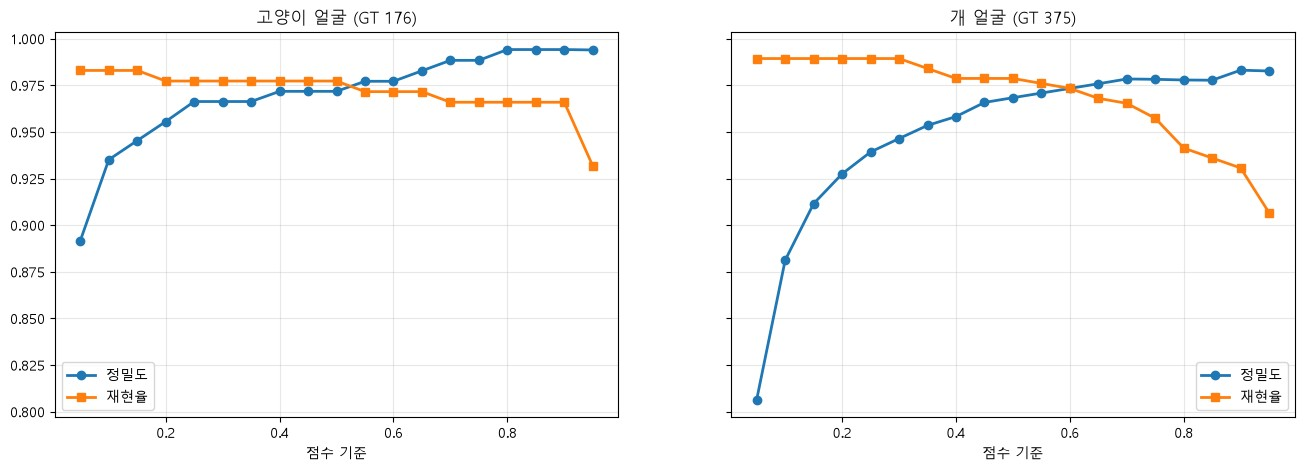

COCO (학습 전) · 점수 기준 0.5  | TP  75 · FP   461 · 재현율 0.136 · 정밀도 0.140
COCO (학습 전) · 점수 기준 0.3  | TP  81 · FP   476 · 재현율 0.147 · 정밀도 0.145
COCO (학습 전) · 점수 기준 0.1  | TP 101 · FP   572 · 재현율 0.183 · 정밀도 0.150
COCO (학습 전) · 점수 기준 0.01 | TP 436 · FP  7520 · 재현율 0.791 · 정밀도 0.055


In [31]:
# 왜 · 점수 기준에 따라 정밀도 · 재현율이 반대로 움직이는 것을 보기 위해
for thr in (0.3, 0.5, 0.7):                               # 점수 기준 세 가지
    show(match(preds_A_val, score_thr=thr, iou_thr=0.5),  # 같은 예측 · 기준만 바꿈
         f"split=val · RUN_A · 점수 기준 {thr} · 평가 IoU 0.5")

# 왜 · F1이 가장 높은 점수 기준을 찾기 위해
thrs = np.round(np.arange(0.05, 1.0, 0.05), 2)                       # 기준 19개
f1s = {}                                                             # 기준마다 F1 (두 클래스 합)
for t in thrs:                                                       # 기준마다
    c = match(preds_A_val, t, 0.5)                                   # 개수
    tp, fp, fn = (c[1][k] + c[2][k] for k in ("TP", "FP", "FN"))     # 합계
    f1s[float(t)] = 2 * tp / (2 * tp + fp + fn)                      # F1
best_t = max(f1s, key=f1s.get)                                       # F1 최고 기준
print("F1 가장 높은 점수 기준:", best_t, f"(F1 {f1s[best_t]:.4f})")  # 운 좋은 자리인가
mid = [f1s[t] for t in f1s if 0.5 <= t <= 0.9]                       # 0.5 ~ 0.9 구간
print("점수 기준 0.5 ~ 0.9의 F1:", f"{min(mid):.4f} ~ {max(f1s.values()):.4f}")  # 평평한가

# 왜 · 클래스별 F1 곡선을 같은 눈금으로 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)                    # 클래스별 곡선
for ax, cls in zip(axes, (1, 2)):                                               # 두 클래스
    cs = [match(preds_A_val, t, 0.5)[cls] for t in thrs]                        # 기준마다
    # 정밀도
    ax.plot(thrs, [c["TP"] / max(c["TP"] + c["FP"], 1) for c in cs], "o-", lw=2, label="정밀도")
    ax.plot(thrs, [c["TP"] / c["GT"] for c in cs], "s-", lw=2, label="재현율")  # 재현율
    ax.set_title(f"{CLASSES[cls]} (GT {cs[0]['GT']})", fontsize=12)             # 제목
    ax.set_xlabel("점수 기준")                                                  # x축
    ax.grid(alpha=0.3)                                                          # 격자
    ax.legend()                                                                 # 범례
plt.show()                                                                      # 그림 출력

# 왜 · 학습 전 COCO 모델도 기준을 낮추면 찾는 얼굴이 늘어나는지 보기 위해
for thr in (0.5, 0.3, 0.1, 0.01):                              # 학습 전 모델은 기준을 내리면 될까
    c = match(preds_coco_val, thr, 0.5)                        # 개수
    tp, fp = c[1]["TP"] + c[2]["TP"], c[1]["FP"] + c[2]["FP"]  # 합계
    # 한 줄
    print(f"COCO (학습 전) · 점수 기준 {thr:<4} | TP {tp:3d} · FP {fp:5d} · 재현율 {tp / n_gt:.3f}"
          f" · 정밀도 {tp / (tp + fp):.3f}")

**결과** · 예측 정답은 FP `27 → 10` · FN `8 → 19`

- `두 클래스 합 GT 551 | TP 543 FP   27 FN   8 | 정밀도 0.953 재현율 0.985 F1 0.969` — 기준 0.3
- `두 클래스 합 GT 551 | TP 532 FP   10 FN  19 | 정밀도 0.982 재현율 0.966 F1 0.973` — 기준 0.7
- `F1 가장 높은 점수 기준: 0.5 (F1 0.9738)` — 보고 기준 0.5가 최고 자리
- `점수 기준 0.5 ~ 0.9의 F1: 0.9638 ~ 0.9738` — 구간이 평평 → 운 좋은 자리 아님
- `COCO (학습 전) · 점수 기준 0.01 | TP 436 · FP  7520 · 재현율 0.791 · 정밀도 0.055` — FP만 폭증

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>점수 기준 ↑</td><td>정밀도 ↑ · 재현율 ↓</td><td>오탐이 비쌀 때</td></tr>
<tr><td>점수 기준 ↓</td><td>재현율 ↑ · 정밀도 ↓</td><td>놓치면 안 될 때</td></tr>
<tr><td>F1 최고 기준</td><td>val로 확인만</td><td>보고 기준은 미리 정함</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 학습 전 모델은 기준을 0.01까지 내려도 FP만 폭증 → 점수 기준으로는 못 고침

> ✅ **한 줄 정리** · 점수 기준은 정밀도와 재현율을 맞바꾸며, 학습이 안 된 모델은 기준으로 고칠 수 없다.

**딥러닝 코드에서는**

- 점수 기준 전체를 한 숫자로 = AP (8장)

### 7-5. `A` 평가 IoU 기준을 바꾸면 · `iou_thr` <sub>원본 D2-7 · 셀 209 ~ 212</sub>

> 🎯 **평가 IoU를 0.5에서 0.7로 올리면?**

💡 **쉽게 말하면**

- 평가 IoU ↑ → **느슨한 박스가 TP에서 빠짐**.
- 학습 전 몸 박스는 거의 다 빠짐.

**실행 흐름**

1. 두 모델 × 평가 IoU 0.5 · 0.7

**먼저 예측** · IoU 0.7에서 RUN_A의 TP는 얼마나 줄까? — 답은 코드 실행 결과 아래에

In [32]:
# 왜 · 평가 IoU 기준을 바꾸면 두 모델의 판정이 어떻게 바뀌는지 비교하기 위해
MODELS = [(f"RUN_A epoch {A_EPOCH}", preds_A_val), ("COCO (학습 전)", preds_coco_val)]  # 두 모델
for name, recs in MODELS:                            # 모델마다
    for t in (0.5, 0.7):                             # 평가 IoU 두 가지
        show(match(recs, score_thr=0.5, iou_thr=t),  # 표
             f"split=val · {name} · 점수 기준 0.5 · 평가 IoU {t}")

split=val · RUN_A epoch 4 · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    5 FN   4 | 정밀도 0.972 재현율 0.977 F1 0.975
  개 얼굴    GT 375 | TP 367 FP   12 FN   8 | 정밀도 0.968 재현율 0.979 F1 0.973
  두 클래스 합 GT 551 | TP 539 FP   17 FN  12 | 정밀도 0.969 재현율 0.978 F1 0.974
split=val · RUN_A epoch 4 · 점수 기준 0.5 · 평가 IoU 0.7
  고양이 얼굴  GT 176 | TP 171 FP    6 FN   5 | 정밀도 0.966 재현율 0.972 F1 0.969
  개 얼굴    GT 375 | TP 352 FP   27 FN  23 | 정밀도 0.929 재현율 0.939 F1 0.934
  두 클래스 합 GT 551 | TP 523 FP   33 FN  28 | 정밀도 0.941 재현율 0.949 F1 0.945
split=val · COCO (학습 전) · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP  18 FP  156 FN 158 | 정밀도 0.103 재현율 0.102 F1 0.103
  개 얼굴    GT 375 | TP  57 FP  305 FN 318 | 정밀도 0.157 재현율 0.152 F1 0.155
  두 클래스 합 GT 551 | TP  75 FP  461 FN 476 | 정밀도 0.140 재현율 0.136 F1 0.138
split=val · COCO (학습 전) · 점수 기준 0.5 · 평가 IoU 0.7
  고양이 얼굴  GT 176 | TP   3 FP  171 FN 173 | 정밀도 0.017 재현율 0.017 F1 0.017
  개 얼굴    GT 375 | TP   9 FP  353 FN 366 | 정밀도 0.025 재현율 0.024 F1 0.024
  두 클래스 

**결과** · 예측 정답은 `539 → 523` (개 얼굴이 대부분)

- `개 얼굴    GT 375 | TP 352 FP   27 FN  23` — IoU 0.7 · 개 TP 367 → 352
- `고양이 얼굴  GT 176 | TP 171 FP    6 FN   5` — IoU 0.7 · 고양이 172 → 171
- `두 클래스 합 GT 551 | TP  12 FP  524 FN 539` — 학습 전 COCO는 75 → 12

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평가 IoU 0.5</td><td>느슨해도 TP</td><td>보통 보고</td></tr>
<tr><td>평가 IoU 0.7</td><td>딱 맞아야 TP</td><td>위치 정확도</td></tr>
<tr><td>둘 다</td><td>같은 예측</td><td>기준만 다름</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점수 기준과 평가 IoU는 다른 기준 → 결과에 둘 다 적음

> ✅ **한 줄 정리** · 평가 IoU를 올리면 위치가 느슨한 박스가 TP에서 빠져 위치 정확도가 드러난다.

**딥러닝 코드에서는**

- IoU 기준 여러 개를 평균 = AP 0.50~0.95 (8-2)

---
## 8. AP · mAP · 어떤 mAP인가

> **이 장의 흐름**
>
> - 7장: 점수 기준마다 달라짐 → 곡선 넓이
> - PR 곡선 · IoU 기준별 AP · 맞힌 박스 평균 IoU

<img src="images/pfo2_ap.png" alt="장난감 고양이: TP · FP · TP → AP 약 0.83" width="662">

**파이프라인 위치** · ⑥ 평가 — AP

### 8-1. `A` AP · PR 곡선 · `ap_per_class()` <sub>원본 D2-8 · 셀 213 ~ 222</sub>

> 🎯 **점수 기준 전부를 숫자 하나로 묶으면?**

💡 **쉽게 말하면**

- AP = **점수 기준을 끝까지 내리며 그린 PR 곡선 아래 넓이**.
- mAP = 클래스별 AP 평균.

**실행 흐름**

1. 장난감 예: 손계산 0.83과 비교
2. 두 모델 · 두 클래스 PR 곡선
3. AP50 · mAP50 · best 기록과 비교

**먼저 예측** · 장난감 고양이 AP는? — 답은 코드 실행 결과 아래에

장난감 고양이 AP: 0.8333 (그림: 0.5 × 1.0 + 0.5 × 0.67 ≈ 0.83)


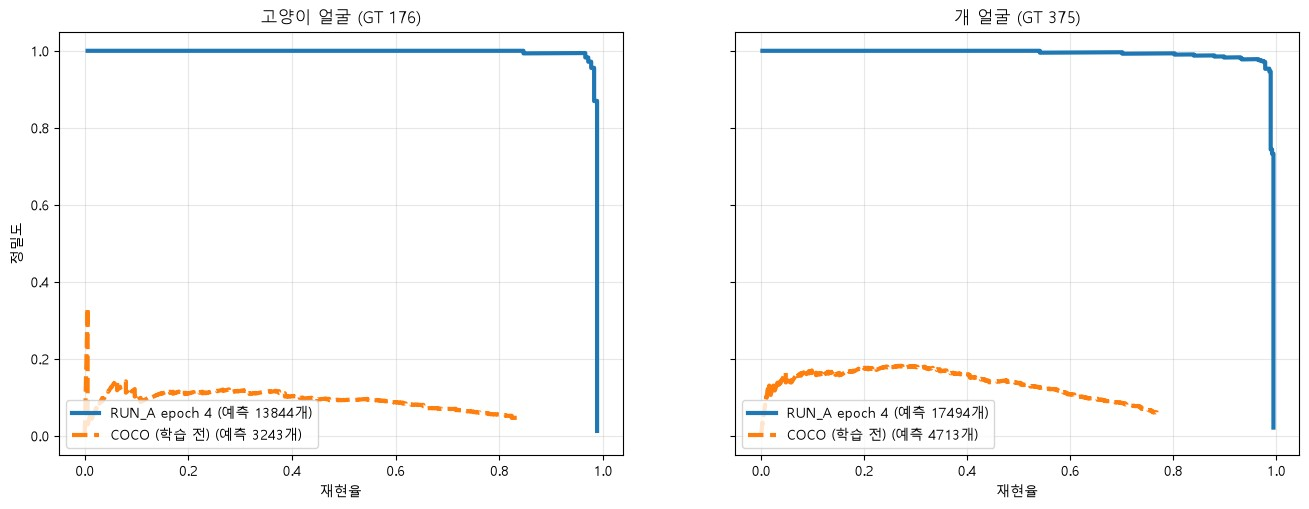

RUN_A epoch 4  | 고양이 얼굴 AP50 0.9867 (GT 176) · 개 얼굴 AP50 0.9887 (GT 375) | mAP50 0.9877
COCO (학습 전)    | 고양이 얼굴 AP50 0.0859 (GT 176) · 개 얼굴 AP50 0.1132 (GT 375) | mAP50 0.0996
6장 best를 고를 때 기록된 mAP50 0.987718 · 지금 계산 0.987718


In [33]:
# 왜 · 작은 예로 AP 계산이 맞는지 손으로 검산하기 위해
a_, off = [0, 0, 10, 10], [20, 20, 30, 30]                               # 수업 그림의 장난감 예
toy = [{"id": "toy", "gt_boxes": [a_, off, a_], "gt_labels": [1, 1, 2],  # 고양이 정답 2개 · 개 1개
        "boxes": [a_, a_, off, a_], "labels": [1, 1, 1, 2], "scores": [0.9, 0.8, 0.7, 0.6]}]
print("장난감 고양이 AP:", round(ap_per_class(toy)[1]["AP"], 4),         # 손계산과 비교
      "(그림: 0.5 × 1.0 + 0.5 × 0.67 ≈ 0.83)")

# 왜 · 클래스별 PR 곡선을 같은 눈금으로 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)               # PR 곡선
for ax, cls in zip(axes, (1, 2)):                                            # 두 클래스
    for (name, recs), style in zip(MODELS, ("-", "--")):                     # 두 모델
        rows, n_gt_c = judge(recs, cls, 0.5)                                 # 판정
        tp = np.cumsum([ok for _, ok, *_ in rows])                           # 누적 TP
        ax.plot(tp / n_gt_c, tp / np.arange(1, len(rows) + 1), style, lw=3,  # 곡선
                label=f"{name} (예측 {len(rows)}개)")
    ax.set_title(f"{CLASSES[cls]} (GT {n_gt_c})", fontsize=12)               # 제목
    ax.set_xlabel("재현율")                                                  # x축
    ax.grid(alpha=0.3)                                                       # 격자
    ax.legend(loc="lower left")                                              # 범례
axes[0].set_ylabel("정밀도")                                                 # y축
plt.show()                                                                   # 그림 출력

for name, recs in MODELS:                                                              # 두 모델
    res = ap_per_class(recs, 0.5)                                                      # AP50
    print(f"{name:14s} | 고양이 얼굴 AP50 {res[1]['AP']:.4f} (GT {res[1]['GT']}) ·"    # 클래스별
          f" 개 얼굴 AP50 {res[2]['AP']:.4f} (GT {res[2]['GT']}) | mAP50 {res['mAP']:.4f}")
now = ap_per_class(preds_A_val)["mAP"]                                                 # 지금 계산
print(f"6장 best를 고를 때 기록된 mAP50 {best_A['mAP50']:.6f} · 지금 계산 {now:.6f}")  # 같은 값

**결과** · 예측 정답은 `0.8333` (손계산 0.83과 같음)

- `장난감 고양이 AP: 0.8333` — 손계산과 같은 함수 → val 전체에 써도 됨
- `| mAP50 0.9877` — RUN_A · 고양이 0.9867 · 개 0.9887
- `| mAP50 0.0996` — 학습 전 COCO
- `6장 best를 고를 때 기록된 mAP50 0.987718 · 지금 계산 0.987718` — 같은 함수 · 같은 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>AP</td><td>PR 곡선 넓이</td><td>한 클래스</td></tr>
<tr><td>mAP</td><td>클래스별 AP 평균</td><td>모델 하나</td></tr>
<tr><td>점수 기준 0.5</td><td>곡선 위 한 점</td><td>7장 표</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - mAP라고만 쓰면 어떤 IoU 기준인지 모름 → AP50처럼 기준을 붙임

> ✅ **한 줄 정리** · AP는 PR 곡선 아래 넓이이고, mAP50은 IoU 0.5에서 클래스별 AP를 평균한 값이다.

**딥러닝 코드에서는**

- 평가지표 보충 5 · 6장: all-point 계산 · COCO 평가기

### 8-2. `A` 평가 IoU 기준별 AP · `ab_summary()` <sub>원본 D2-8 · 셀 223 ~ 227</sub>

> 🎯 **mAP50 0.99 = 얼굴 박스를 거의 딱 맞게 친다는 뜻인가?**

💡 **쉽게 말하면**

- AP50은 **IoU 0.5만 넘으면 TP** → 느슨한 박스도 맞힌 것.
- AP75 · 0.50~0.95 평균은 더 딱 맞아야 높음.

**실행 흐름**

1. IoU 0.50 ~ 0.95 (10개)마다 AP
2. 클래스별 · 두 클래스 평균
3. 기준별 AP 그림

**먼저 예측** · AP75는 AP50보다 낮을까? — 답은 코드 실행 결과 아래에

RUN_A epoch 4 · split=val · 점수 0.01 이상 · 우리 평가 함수 (공식 COCO 평가기 아님)
  고양이 얼굴   AP50 0.987 · AP75 0.963 · IoU 0.50~0.95 평균 AP 0.809
  개 얼굴     AP50 0.989 · AP75 0.901 · IoU 0.50~0.95 평균 AP 0.735
  두 클래스 평균 AP50 0.988 · AP75 0.932 · IoU 0.50~0.95 평균 AP 0.772
COCO (학습 전) · split=val · 점수 0.01 이상 · 우리 평가 함수 (공식 COCO 평가기 아님)
  고양이 얼굴   AP50 0.086 · AP75 0.006 · IoU 0.50~0.95 평균 AP 0.025
  개 얼굴     AP50 0.113 · AP75 0.004 · IoU 0.50~0.95 평균 AP 0.031
  두 클래스 평균 AP50 0.100 · AP75 0.005 · IoU 0.50~0.95 평균 AP 0.028


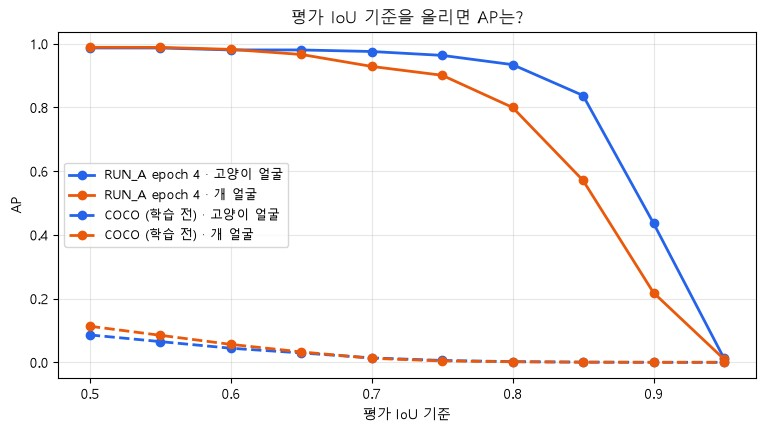

In [34]:
# 왜 · COCO처럼 IoU 0.50 ~ 0.95 열 기준의 AP를 구하기 위해
IOU_THRS = np.round(np.arange(0.50, 0.96, 0.05), 2)  # 0.50 ~ 0.95 (10개)


# 왜 · AP50 · AP75 · 열 기준 평균을 한 번에 요약하기 위해
def ab_summary(records):  # AP50 · AP75 · 0.50~0.95 평균 (두 클래스 평균) · 클래스별 곡선
    cur = {float(t): ap_per_class(records, t) for t in IOU_THRS}  # 기준마다
    m = {t: v["mAP"] for t, v in cur.items()}                     # 평균 AP
    cat = {t: v[1]["AP"] for t, v in cur.items()}                 # 고양이 곡선
    dog = {t: v[2]["AP"] for t, v in cur.items()}                 # 개 곡선
    # 세 숫자
    return {"AP50": m[0.5], "AP75": m[0.75], "AP50_95": sum(m.values()) / len(m), "curve": m,
            "cat": cat, "dog": dog}


# 왜 · 두 모델의 기준별 AP를 나란히 비교하기 위해
sums = {name: ab_summary(recs) for name, recs in MODELS}                     # 두 모델
for name, s in sums.items():                                                 # 모델마다
    print(f"{name} · split=val · 점수 0.01 이상 · 우리 평가 함수 (공식 COCO 평가기 아님)")  # 조건
    for key, label in [("cat", CLASSES[1]), ("dog", CLASSES[2])]:            # 클래스별
        v = s[key]                                                           # 기준마다 AP
        print(f"  {label:8s} AP50 {v[0.5]:.3f} · AP75 {v[0.75]:.3f} ·"       # 세 숫자
              f" IoU 0.50~0.95 평균 AP {np.mean(list(v.values())):.3f}")
    print(f"  두 클래스 평균 AP50 {s['AP50']:.3f} · AP75 {s['AP75']:.3f} ·"  # 평균
          f" IoU 0.50~0.95 평균 AP {s['AP50_95']:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))                                    # 기준별 AP
for name, s in sums.items():                                                # 두 모델
    for key, color in [("cat", "#2563eb"), ("dog", "#ea580c")]:             # 두 클래스
        style = ("-" if "RUN" in name else "--") + "o"                      # 실선 = 학습 후
        ax.plot(IOU_THRS, list(s[key].values()), style, color=color, lw=2,  # 기준별 AP
                label=f"{name} · {CLASSES[1 if key == 'cat' else 2]}")
ax.set_xlabel("평가 IoU 기준")                                              # x축
ax.set_ylabel("AP")                                                         # y축
ax.set_title("평가 IoU 기준을 올리면 AP는?", fontsize=12)                   # 제목
ax.grid(alpha=0.3)                                                          # 격자
ax.legend(fontsize=9)                                                       # 범례
plt.show()                                                                  # 그림 출력

**결과** · 예측 정답은 낮음 — AP50 `0.988` → AP75 `0.932`

- `두 클래스 평균 AP50 0.988 · AP75 0.932 · IoU 0.50~0.95 평균 AP 0.772` — 엄격할수록 낮아짐
- `고양이 얼굴   AP50 0.987 · AP75 0.963 · IoU 0.50~0.95 평균 AP 0.809` — 고양이는 위치가 더 정확
- `개 얼굴     AP50 0.989 · AP75 0.901 · IoU 0.50~0.95 평균 AP 0.735` — AP50은 개가 위 · 엄격하면 순위가 바뀜
- `두 클래스 평균 AP50 0.100 · AP75 0.005 · IoU 0.50~0.95 평균 AP 0.028` — 학습 전 COCO

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>AP50</td><td>느슨한 기준</td><td>찾았나</td></tr>
<tr><td>AP75</td><td>엄격한 기준</td><td>딱 맞나</td></tr>
<tr><td>0.50~0.95 평균</td><td>10개 기준 평균</td><td>COCO 대표 숫자</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 공식 COCO 평가기(101점 보간 · 면적별)와 숫자가 조금 다를 수 있음 → '우리 평가 함수'로 적음

> ✅ **한 줄 정리** · AP50이 높아도 AP75와 0.50~0.95 평균은 낮을 수 있어, 위치 정확도는 엄격한 기준으로 본다.

**딥러닝 코드에서는**

- `torchmetrics.detection.MeanAveragePrecision` — map · map_50 · map_75

### 8-3. `A` 맞힌 박스의 평균 IoU · `mission_iou()` <sub>원본 D2-8 · 셀 228 ~ 233</sub>

> 🎯 **미션 문서의 'IOU'는 무엇을 재는가?**

💡 **쉽게 말하면**

- **맞힌 박스(TP)만** 모아 IoU를 평균 → 박스가 얼마나 딱 맞나.
- 놓친 것 · 헛짚은 것은 안 들어감.

**실행 흐름**

1. 클래스별 TP의 평균 IoU
2. IoU 0.75 · 0.95 미만 개수
3. TP IoU 히스토그램

**먼저 예측** · 학습 전 COCO의 평균 IoU도 낮을까? — 답은 코드 실행 결과 아래에

RUN_A epoch 4  | 고양이 얼굴 맞힌 172/176개의 평균 IoU 0.903 | 개 얼굴 맞힌 367/375개의 평균 IoU 0.870
COCO (학습 전)    | 고양이 얼굴 맞힌 18/176개의 평균 IoU 0.608 | 개 얼굴 맞힌 57/375개의 평균 IoU 0.623
맞힌 539개 중 IoU 0.75 미만: 26개
맞힌 539개 중 IoU 0.95 미만: 492개


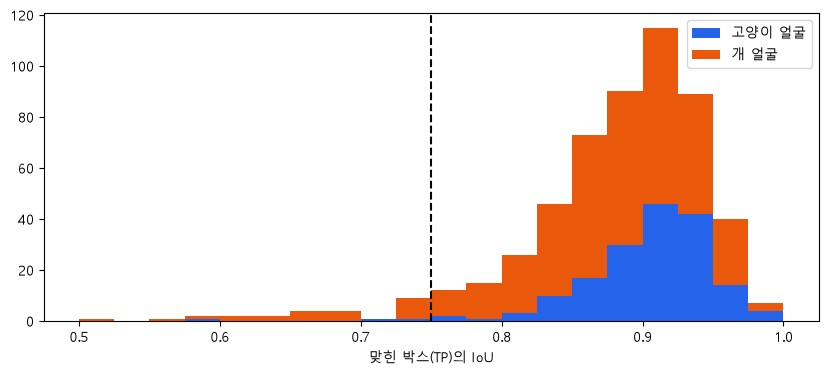

In [35]:
# 왜 · 맞힌 박스가 정답에 얼마나 딱 맞는지 따로 재기 위해
def mission_iou(records, score_thr=0.5, iou_thr=0.5):  # TP가 된 예측만 모아 IoU 평균
    out = {}                                           # 결과
    for cls in (1, 2):                                 # 두 클래스
        rows, n_gt_c = judge(records, cls, iou_thr, score_min=score_thr)  # 판정
        ious = [v for _, ok, v, *_ in rows if ok]      # TP의 IoU
        # 평균
        out[cls] = {"평균 IoU": float(np.mean(ious)) if ious else float("nan"), "TP": len(ious),
                    "GT": n_gt_c, "ious": ious}
    return out                                         # FP · FN은 평균에 안 들어감


for name, recs in MODELS:                        # 두 모델
    m = mission_iou(recs)                        # 평균 IoU
    # 클래스별
    parts = [f"{CLASSES[c]} 맞힌 {m[c]['TP']}/{m[c]['GT']}개의 평균 IoU {m[c]['평균 IoU']:.3f}"
             for c in (1, 2)]
    print(f"{name:14s} | " + " | ".join(parts))  # 한 줄

# 왜 · AP75가 낮은 이유를 맞힌 박스의 IoU 분포로 확인하기 위해
m = mission_iou(preds_A_val)              # RUN_A
all_ious = m[1]["ious"] + m[2]["ious"]    # TP 전부
for t in (0.75, 0.95):                    # 두 기준
    # AP75가 낮은 이유
    print(f"맞힌 {len(all_ious)}개 중 IoU {t} 미만: {sum(v < t for v in all_ious)}개")
fig, ax = plt.subplots(figsize=(10, 4))   # 분포
# 쌓은 히스토그램
ax.hist([m[1]["ious"], m[2]["ious"]], bins=np.arange(0.5, 1.001, 0.025), stacked=True,
        color=["#2563eb", "#ea580c"], label=[CLASSES[1], CLASSES[2]])
ax.axvline(0.75, color="black", ls="--")  # 0.75 기준
ax.set_xlabel("맞힌 박스(TP)의 IoU")      # x축
ax.legend()                               # 범례
plt.show()                                # 그림 출력

**결과** · 예측 정답은 높은 편 — `0.608` · `0.623`

- `고양이 얼굴 맞힌 172/176개의 평균 IoU 0.903` — RUN_A
- `고양이 얼굴 맞힌 18/176개의 평균 IoU 0.608` — 학습 전도 맞힌 것만 보면 0.6대
- `맞힌 539개 중 IoU 0.75 미만: 26개` — 느슨한 TP
- `맞힌 539개 중 IoU 0.95 미만: 492개` — AP75 · 평균 AP가 AP50보다 낮은 이유

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평균 IoU</td><td>TP만</td><td>박스 정확도 진단</td></tr>
<tr><td>AP</td><td>TP · FP · FN 모두</td><td>모델 비교 (기본)</td></tr>
<tr><td>TP 수</td><td>맞힌 개수</td><td>평균 IoU와 같이 적음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 학습 전 모델도 맞힌 몇 개만 보면 평균 IoU가 꽤 높음 → mAP를 대신하지 않음

> ✅ **한 줄 정리** · 맞힌 박스의 평균 IoU는 박스 정확도를 보는 진단이며, 놓친 것과 헛짚은 것은 반영하지 않는다.

**딥러닝 코드에서는**

- 보고할 때: 평균 IoU + TP 수 + GT 수

---
## 9. 오류 분석

> **이 장의 흐름**
>
> - 8장 숫자가 높아도 틀린 것은 남음
> - 판정 목록 · 오류 세 종류 사진 · 크기별

<img src="images/pfo2_errors.png" alt="오류 네 갈래 · 관찰 → 가설 → 확인" width="762">

**파이프라인 위치** · ⑥ 평가 — 오류 분석

### 9-1. `A` 판정 목록 · 갤러리 도구 · `err_events()` · `err_gallery()` <sub>원본 D2-9 · 셀 234 ~ 239</sub>

> 🎯 **남은 틀린 박스를 사진으로 보려면 무엇이 필요한가?**

💡 **쉽게 말하면**

- 예측 · 정답마다 **TP · FP · FN 판정 목록**을 만듦.
- FP는 가장 많이 겹친 정답(클래스 무관)도 기록.

**실행 흐름**

1. 사진 · 클래스마다 판정
2. 클래스별 개수 (7장 표와 같은가)
3. 사진 이름 → 갤러리 함수

**먼저 예측** · 판정 목록의 개수는 7장 표와 같을까? — 답은 코드 실행 결과 아래에

In [36]:
# 왜 · 박스마다 TP · FP · FN 판정을 남겨 오류를 유형별로 세기 위해
def err_events(records, score_thr=0.5, iou_thr=0.5):  # 모든 사진 · 두 클래스의 판정 목록
    events = []                                                               # 결과
    for r in records:                                                         # 사진마다
        gt_all = torch.tensor(r["gt_boxes"]).reshape(-1, 4)                   # 클래스 상관없는 정답
        for c in (1, 2):                                                      # 클래스마다
            gts = [b for b, lb in zip(r["gt_boxes"], r["gt_labels"]) if lb == c]  # 같은 클래스 정답
            # 점수 순
            preds = sorted([(s, b) for b, lb, s in zip(r["boxes"], r["labels"], r["scores"])
                            if lb == c and s >= score_thr], key=lambda q: -q[0])
            used = set()                                                      # 짝 생긴 정답
            for s, b in preds:                                                # 예측마다
                # IoU
                ious = box_iou(torch.tensor([b]), torch.tensor(gts).reshape(-1, 4))[0].tolist()
                free = [(v, k) for k, v in enumerate(ious) if k not in used]  # 짝 없는 정답
                best, j = max(free, default=(0.0, None))                      # 가장 많이 겹친 것
                if j is not None and best >= iou_thr:                         # TP
                    used.add(j)                                               # 짝
                    # 기록
                    events.append({"kind": "TP", "score": s, "iou": best, "id": r["id"], "cls": c})
                    continue                                                  # 다음
                e = {"kind": "FP", "score": s, "iou": 0.0, "id": r["id"],     # FP 기록
                     "cls": c, "near_cls": None}
                if len(gt_all):                                               # 정답이 있으면
                    io = box_iou(torch.tensor([b]), gt_all)[0]                # 클래스 상관없이
                    # 가장 겹친 정답
                    e["iou"], e["near_cls"] = io.max().item(), r["gt_labels"][io.argmax().item()]
                events.append(e)                                              # 기록
            events += [{"kind": "FN", "id": r["id"], "cls": c, "box": g}      # 놓친 정답
                       for k, g in enumerate(gts) if k not in used]
    return events                                                             # 판정 목록


# 왜 · 클래스별 오류 개수를 먼저 확인하기 위해
ev_A = err_events(preds_A_val)                             # RUN_A best · val · 점수 0.5 · IoU 0.5
for c in (1, 2):                                           # 클래스마다
    k = Counter(e["kind"] for e in ev_A if e["cls"] == c)  # 세기
    print(f"{CLASSES[c]}: TP {k['TP']:3d} · FP {k['FP']:2d} · FN {k['FN']:2d}")  # 7장 표와 같은 수


# 왜 · 오류 사진을 같은 형식으로 모아 보기 위해
def err_gallery(ids, records, head, ncol=4):                       # 사진 이름 목록 → 갤러리
    by_id = {r["id"]: r for r in records}                          # 이름으로 찾기
    ids = ids[:8]                                                  # 최대 8장
    nrow = max(1, -(-len(ids) // ncol))                            # 줄 수
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.3 * ncol, 3.9 * nrow), squeeze=False)  # 칸
    for ax in axes.flat:                                           # 빈 칸도
        ax.axis("off")                                             # 눈금 숨김
    for ax, s in zip(axes.flat, ids):                              # 사진마다
        r = by_id[s]                                               # 기록
        keep = [i for i, v in enumerate(r["scores"]) if v >= 0.5]  # 0.5 이상
        labs = [f"{CLASSES[r['labels'][i]]} {r['scores'][i]:.2f}" for i in keep]  # 이름표
        draw(load_image(s), gt=r["gt_boxes"], pred=[r["boxes"][i] for i in keep], ax=ax,  # 그림
             title=s, labels=labs)
    fig.suptitle(head, fontsize=12)                                # 제목
    plt.tight_layout()                                             # 여백
    plt.show()                                                     # 그림 출력

고양이 얼굴: TP 172 · FP  5 · FN  4
개 얼굴: TP 367 · FP 12 · FN  8


**결과** · 예측 정답은 같음

- `고양이 얼굴: TP 172 · FP  5 · FN  4` — 7-2 표와 같은 수
- `개 얼굴: TP 367 · FP 12 · FN  8` — 틀린 것 29개 + 놓친 것을 이제 사진으로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>TP</td><td>점수 0.5 · IoU 0.5 이상 짝</td><td>맞힘</td></tr>
<tr><td>FP</td><td>짝 없는 예측 · 가장 겹친 정답 기록</td><td>헛짚음 · 혼동</td></tr>
<tr><td>FN</td><td>짝 없는 정답</td><td>놓침</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 같은 기준(점수 0.5 · IoU 0.5)이어야 7장 표와 개수가 맞음

> ✅ **한 줄 정리** · 판정 목록은 7장과 같은 기준으로 예측 · 정답마다 TP · FP · FN을 기록한다.

**딥러닝 코드에서는**

- `Counter(e["kind"] for e in events)`

### 9-2. `A` 놓친 얼굴 · 점수 높은 FP · 느슨한 TP · `err_gallery()` <sub>원본 D2-9 · 셀 240 ~ 245</sub>

> 🎯 **모델이 놓친 얼굴, 확신한 오탐, 느슨한 박스는 어떤 모습인가?**

💡 **쉽게 말하면**

- 숫자(mAP)가 알려 주지 않는 것 → **사진을 직접 봄**.
- 세 종류: 놓친 얼굴 · 점수 높은 FP · 느슨한 TP.

**실행 흐름**

1. FN 사진
2. 점수 0.85 이상 FP · 가장 겹친 정답
3. IoU 0.75 미만 TP · 가장 낮은 8개

**먼저 예측** · 점수 0.85 넘는 FP는 클래스 혼동일까, 헛것일까? — 답은 코드 실행 결과 아래에

놓친 얼굴: 12 개 · 고양이 4 · 개 8


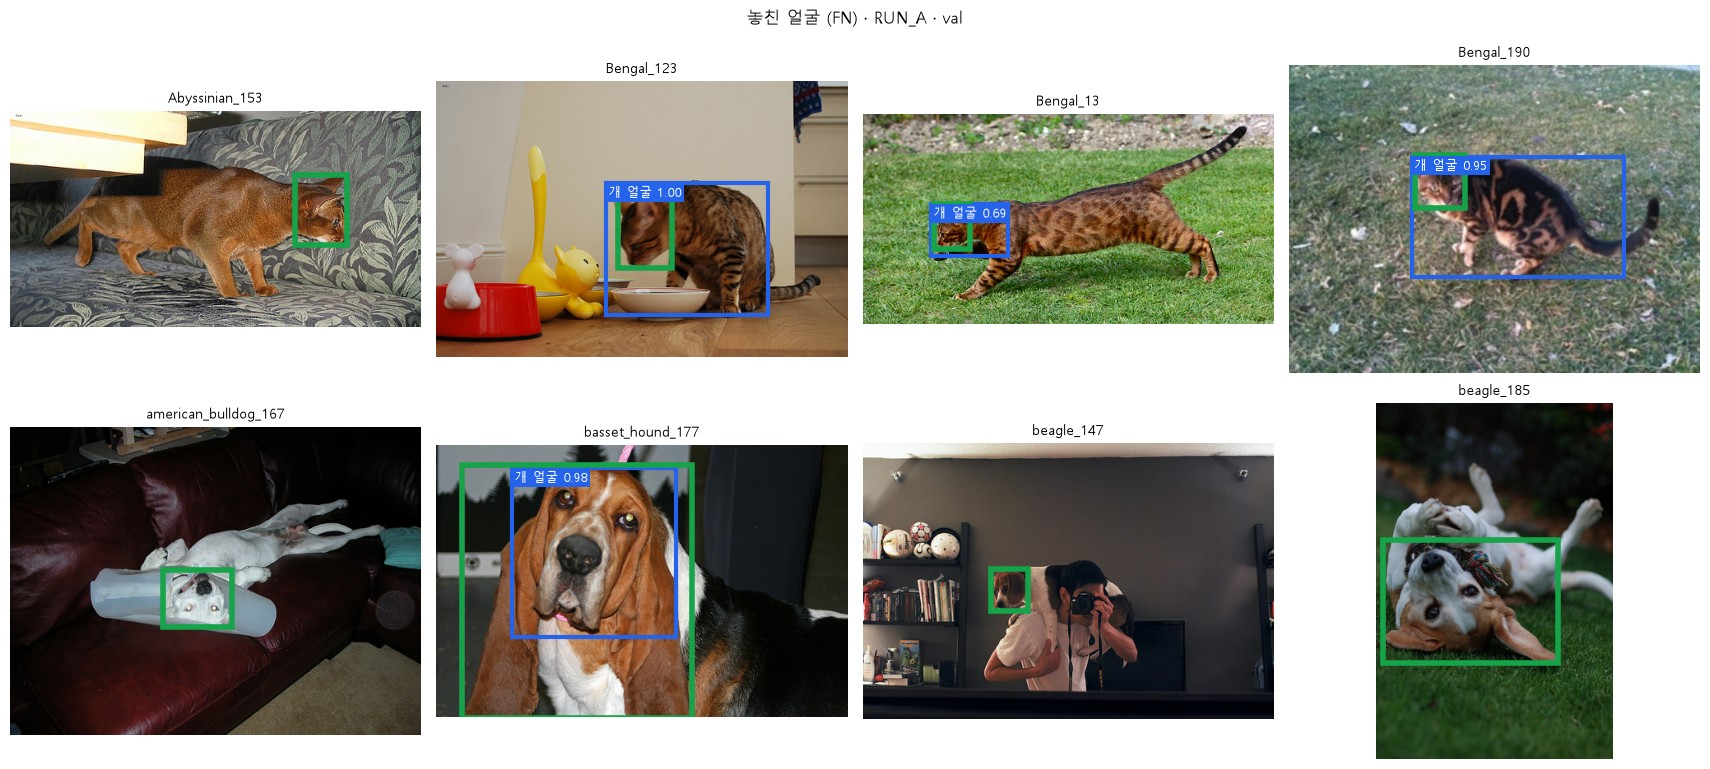

FP 전체 17 개 · 그중 점수 0.85 이상 9 개
  Bengal_123               예측 개 얼굴 1.00 → IoU 0.5 넘게 겹친 정답 없음
  boxer_139                예측 개 얼굴 0.99 → IoU 0.5 넘게 겹친 정답 없음
  miniature_pinscher_16    예측 개 얼굴 0.99 → IoU 0.5 넘게 겹친 정답 없음
  chihuahua_106            예측 고양이 얼굴 0.98 → 정답 개 얼굴 박스와 IoU 0.92
  basset_hound_177         예측 개 얼굴 0.98 → IoU 0.5 넘게 겹친 정답 없음
  saint_bernard_154        예측 개 얼굴 0.97 → IoU 0.5 넘게 겹친 정답 없음
  Bengal_190               예측 개 얼굴 0.95 → IoU 0.5 넘게 겹친 정답 없음
  basset_hound_158         예측 개 얼굴 0.89 → IoU 0.5 넘게 겹친 정답 없음
  wheaten_terrier_162      예측 개 얼굴 0.87 → IoU 0.5 넘게 겹친 정답 없음
놓친 얼굴이 있는 사진 12 장 중 같은 사진에 FP도 있는 사진: 7 장


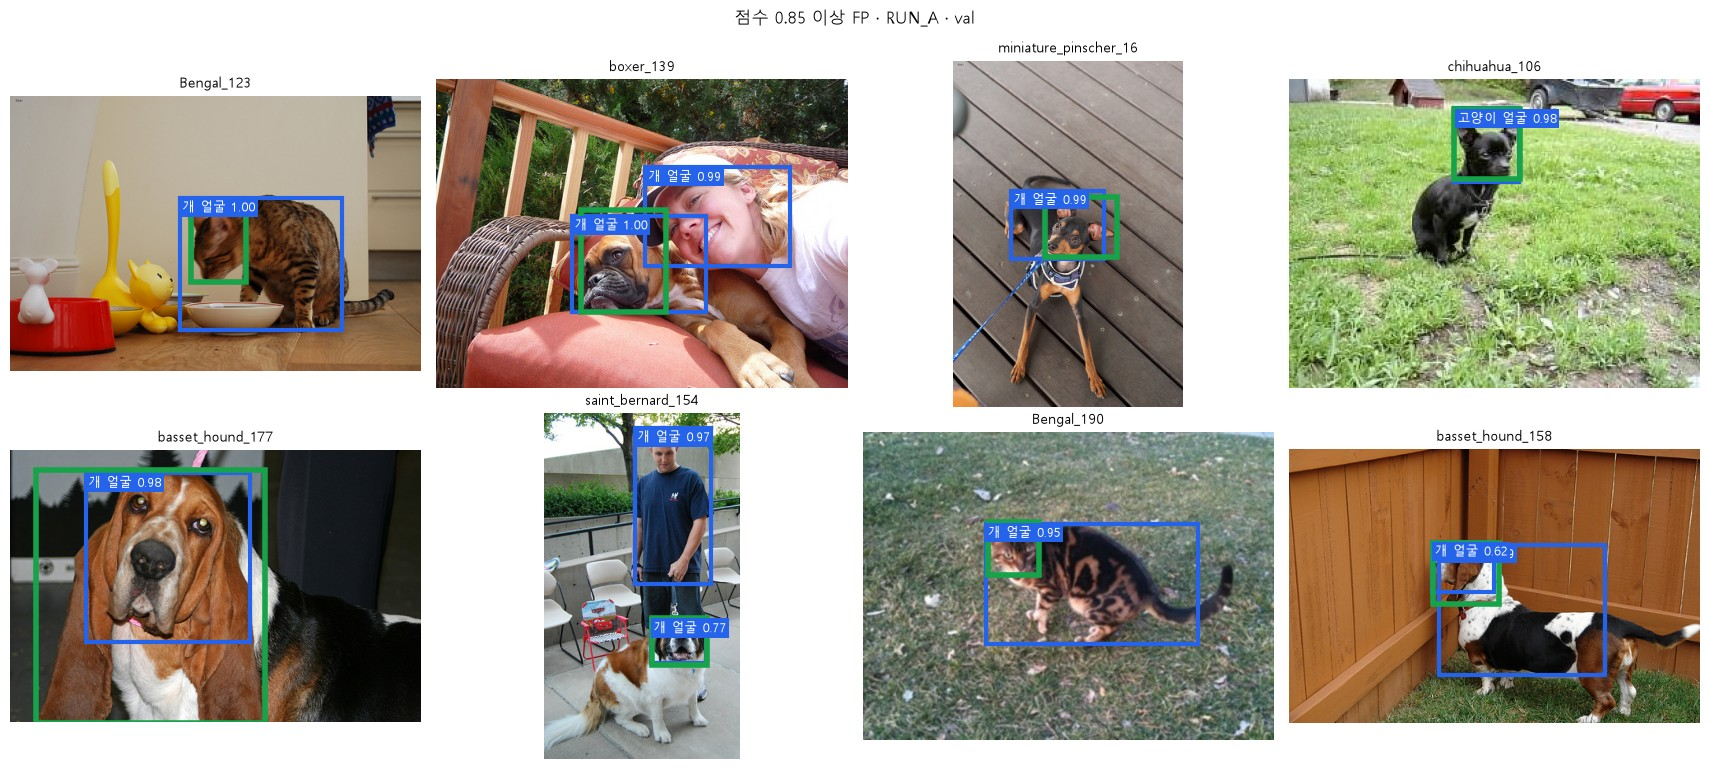

TP 539개 중 IoU 0.75 미만: 26개 (고양이 3 · 개 23)


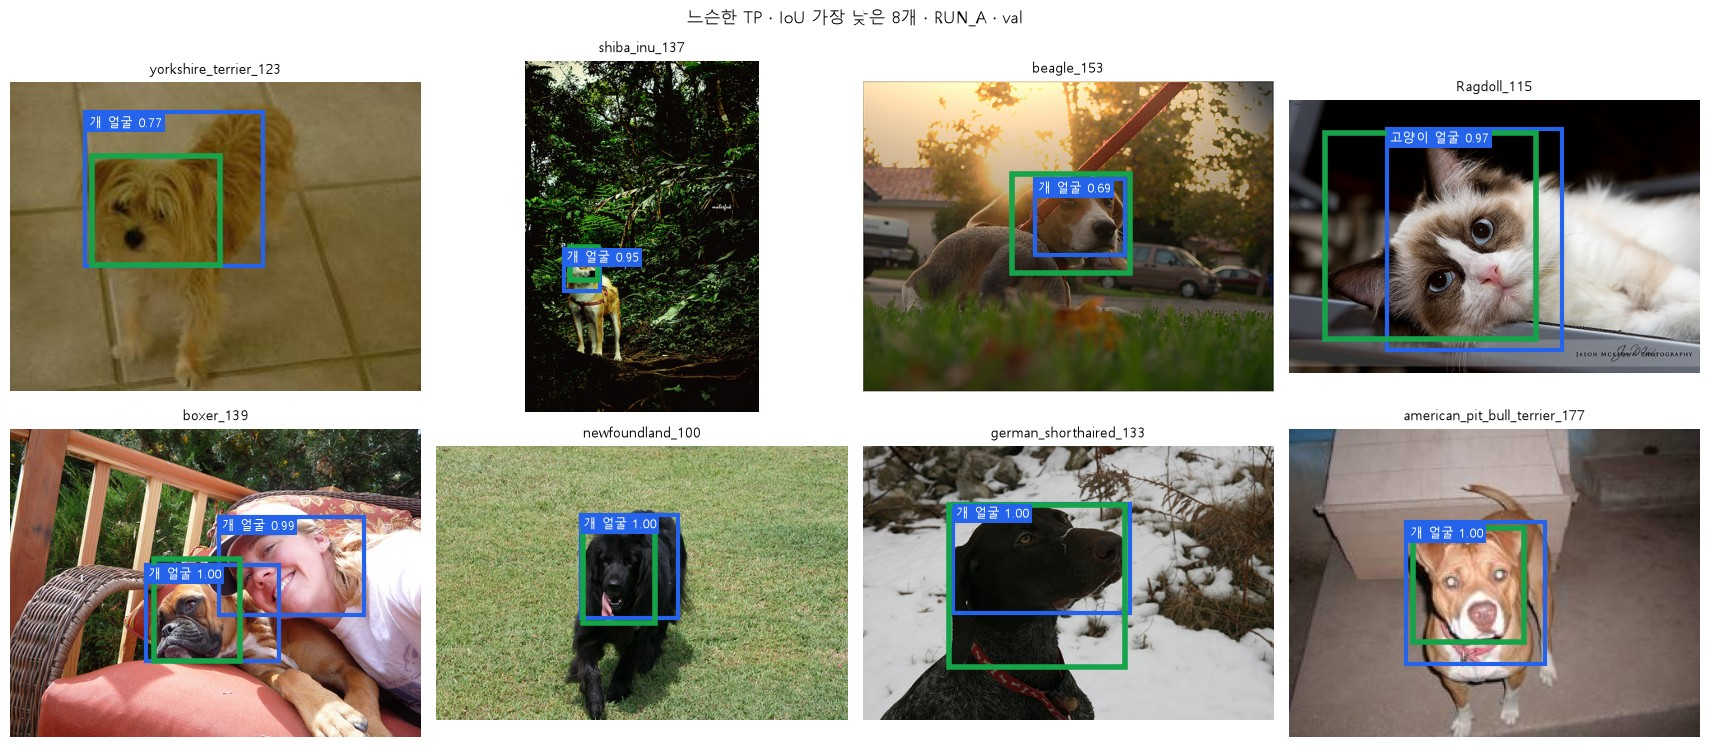

In [37]:
# 왜 · 놓친 얼굴을 직접 보고 원인을 찾기 위해
fn_A = [e for e in ev_A if e["kind"] == "FN"]                                            # 놓친 얼굴
print("놓친 얼굴:", len(fn_A), "개 · 고양이", sum(e["cls"] == 1 for e in fn_A), "· 개",  # 클래스별
      sum(e["cls"] == 2 for e in fn_A))
# 사진
err_gallery(list(dict.fromkeys(e["id"] for e in fn_A)), preds_A_val, "놓친 얼굴 (FN) · RUN_A · val")

# 왜 · 점수가 높은데 틀린 예측을 따로 보기 위해
fp_A = sorted([e for e in ev_A if e["kind"] == "FP"], key=lambda e: -e["score"])  # 점수 높은 FP 순
fp_high = [e for e in fp_A if e["score"] >= 0.85]                                 # 확신한 오탐
print("FP 전체", len(fp_A), "개 · 그중 점수 0.85 이상", len(fp_high), "개")       # 개수
for e in fp_high:                                                                 # 하나씩
    # 클래스 혼동?
    near = (f"정답 {CLASSES[e['near_cls']]} 박스와 IoU {e['iou']:.2f}" if e["iou"] >= 0.5
            else "IoU 0.5 넘게 겹친 정답 없음")
    print(f"  {e['id']:24s} 예측 {CLASSES[e['cls']]} {e['score']:.2f} → {near}")  # 한 줄
both = {e["id"] for e in fn_A} & {e["id"] for e in fp_A}  # 놓침 + 오탐이 같은 사진
n_fn_img = len({e["id"] for e in fn_A})  # 놓친 얼굴이 있는 사진 수
# 겹침
print("놓친 얼굴이 있는 사진", n_fn_img, "장 중 같은 사진에 FP도 있는 사진:", len(both), "장")
err_gallery([e["id"] for e in fp_high], preds_A_val, "점수 0.85 이상 FP · RUN_A · val")  # 사진

# 왜 · 맞혔지만 느슨한 박스를 따로 보기 위해
tp_A = [e for e in ev_A if e["kind"] == "TP"]                                   # 맞힌 박스
loose_A = sorted([e for e in tp_A if e["iou"] < 0.75], key=lambda e: e["iou"])  # 느슨한 TP
print(f"TP {len(tp_A)}개 중 IoU 0.75 미만: {len(loose_A)}개"                    # 클래스별
      f" (고양이 {sum(e['cls'] == 1 for e in loose_A)} · 개 {sum(e['cls'] == 2 for e in loose_A)})")
# 사진
err_gallery([e["id"] for e in loose_A], preds_A_val, "느슨한 TP · IoU 가장 낮은 8개 · RUN_A · val")

**결과** · 예측 정답은 대부분 겹친 정답이 없는 자리 — 9개 중 클래스 혼동은 `1`개

- `놓친 얼굴: 12 개 · 고양이 4 · 개 8` — FN 사진 갤러리
- `FP 전체 17 개 · 그중 점수 0.85 이상 9 개` — 확신한 오탐
- `chihuahua_106            예측 고양이 얼굴 0.98 → 정답 개 얼굴 박스와 IoU 0.92` — 자리는 맞고 클래스만 혼동
- `놓친 얼굴이 있는 사진 12 장 중 같은 사진에 FP도 있는 사진: 7 장` — 엉뚱한 자리에 박스 · 진짜 얼굴은 놓침
- `TP 539개 중 IoU 0.75 미만: 26개 (고양이 3 · 개 23)` — 느슨한 박스는 대부분 개

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>FN</td><td>작은 · 돌린 · 가려진 얼굴</td><td>데이터 · 증강</td></tr>
<tr><td>높은 점수 FP</td><td>정답 박스 없는 다른 동물 · 몸 · 클래스 혼동</td><td>[확인] 모아 세기</td></tr>
<tr><td>느슨한 TP</td><td>귀 · 볼 경계</td><td>[실험] 디폴트 박스</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 원인은 가설 → [확인] 더 살펴보기 · [실험] 한 가지만 바꿔 다시 학습

> ✅ **한 줄 정리** · 오류 사진을 종류별로 보면 숫자로는 안 보이던 원인 가설을 세울 수 있다.

**딥러닝 코드에서는**

- 관찰 → 가설 → 확인 방법 표 (원본 셀 251)

### 9-3. `A` 얼굴 크기별 놓침 · `err_gt_table()` · `err_size_table()` <sub>원본 D2-9 · 셀 246 ~ 252</sub>

> 🎯 **작은 얼굴일수록 더 많이 놓치는가?**

💡 **쉽게 말하면**

- 얼굴 크기 = **300×300 기준 긴 변** (2-5와 같은 정의).
- 구간마다 0.5 · 0.75로 찾은 비율.

**실행 흐름**

1. 정답 얼굴마다 크기 · 최대 IoU
2. 100 미만 · 100 ~ 200 · 200 이상
3. 전체 · 고양이 · 개

**먼저 예측** · 긴 변 100 미만 구간의 0.75로 찾은 비율은 낮을까? — 답은 코드 실행 결과 아래에

In [38]:
# 왜 · 얼굴 크기를 사진 크기와 함께 계산하기 위해
def err_face_size(stem, box):  # Day01 7-3 정의: 300 기준 긴 변
    size = ET.parse(XMLS / f"{stem}.xml").getroot().find("size")          # 크기
    w, h = float(size.findtext("width")), float(size.findtext("height"))  # 폭 · 높이
    return max((box[2] - box[0]) / w * 300, (box[3] - box[1]) / h * 300)  # 긴 변


# 왜 · 정답 얼굴마다 찾았는지와 크기를 표로 모으기 위해
def err_gt_table(records, score_thr=0.5):                # 정답 얼굴마다 크기 · 최대 IoU
    rows = []                                            # 결과
    for r in records:                                    # 사진마다
        for g, c in zip(r["gt_boxes"], r["gt_labels"]):  # 정답마다
            # 같은 클래스 예측
            same_c = [b for b, lb, s in zip(r["boxes"], r["labels"], r["scores"])
                      if lb == c and s >= score_thr]
            # 최대 IoU
            best = (box_iou(torch.tensor([g]), torch.tensor(same_c).reshape(-1, 4)).max().item()
                    if same_c else 0.0)
            # 기록
            rows.append({"id": r["id"], "cls": c, "size": err_face_size(r["id"], g), "iou": best})
    return rows                                          # 정답 수만큼


# 왜 · 얼굴 크기 구간을 한곳에서 정하기 위해
BINS = [(0, 100, "100 미만"), (100, 200, "100 ~ 200"), (200, 301, "200 이상")]  # 크기 구간


# 왜 · 크기 구간별 놓침 비율을 세기 위해
def err_size_table(rows, cls=None):               # 구간마다 (이름, 수, 0.5로 찾음, 0.75로 찾음)
    out = []                                      # 결과
    for lo, hi, name in BINS:                     # 구간마다
        # 이 구간
        sel = [g for g in rows if lo <= g["size"] < hi and (cls is None or g["cls"] == cls)]
        f50 = sum(g["iou"] >= 0.5 for g in sel)   # 0.5로 찾음
        f75 = sum(g["iou"] >= 0.75 for g in sel)  # 0.75로 찾음
        out.append((name, len(sel), f50, f75))    # 한 줄
    return out                                    # 세 줄


# 왜 · 작은 얼굴에서 더 많이 놓치는지 숫자로 확인하기 위해
gt_A = err_gt_table(preds_A_val)                                                     # RUN_A
# 아주 작은 얼굴
print("정답 얼굴", len(gt_A), "개 · 긴 변 50 미만", sum(g["size"] < 50 for g in gt_A), "개")
for cls, title in [(None, "전체"), (1, "고양이 얼굴"), (2, "개 얼굴")]:              # 세 묶음
    print(f"[{title}]")                                                              # 머리
    for name, n, f50, f75 in err_size_table(gt_A, cls):                              # 구간마다
        print(f"  {name:9s} {n:3d}개 · 0.5로 찾음 {f50 / n:.2f} ({n - f50}개 놓침)"  # 찾은 비율
              f" · 0.75로 찾음 {f75 / n:.2f}")

정답 얼굴 551 개 · 긴 변 50 미만 6 개
[전체]
  100 미만    127개 · 0.5로 찾음 0.92 (10개 놓침) · 0.75로 찾음 0.84
  100 ~ 200 319개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 0.96
  200 이상    105개 · 0.5로 찾음 0.98 (2개 놓침) · 0.75로 찾음 0.94
[고양이 얼굴]
  100 미만     46개 · 0.5로 찾음 0.91 (4개 놓침) · 0.75로 찾음 0.89
  100 ~ 200 101개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 1.00
  200 이상     29개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 0.93
[개 얼굴]
  100 미만     81개 · 0.5로 찾음 0.93 (6개 놓침) · 0.75로 찾음 0.81
  100 ~ 200 218개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 0.94
  200 이상     76개 · 0.5로 찾음 0.97 (2개 놓침) · 0.75로 찾음 0.95


**결과** · 예측 정답은 낮음 — `0.84` (100 ~ 200은 0.96)

- `정답 얼굴 551 개 · 긴 변 50 미만 6 개` — 아주 작은 얼굴은 드묾
- `100 미만    127개 · 0.5로 찾음 0.92 (10개 놓침) · 0.75로 찾음 0.84` — 놓침 12개 중 10개
- `100 ~ 200 319개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 0.96` — 중간 크기는 다 찾음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>100 미만</td><td>작은 얼굴</td><td>놓치기 쉬움</td></tr>
<tr><td>100 ~ 200</td><td>중간</td><td>대부분 찾음</td></tr>
<tr><td>200 이상</td><td>큰 얼굴</td><td>거의 다 찾음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 구간마다 개수(분모)가 다름 → 비율과 개수를 같이 봄

> ✅ **한 줄 정리** · 얼굴 크기 구간별로 찾은 비율을 보면 작은 얼굴에서 위치가 덜 정확한지 확인할 수 있다.

**딥러닝 코드에서는**

- SSD의 작은 물체 약점 → 작게 줄인 사진을 섞는 증강 (실험 후보)

---
## 10. 하나만 바꾸기 · A/B

> **이 장의 흐름**
>
> - 9장 분석 도구 그대로 RUN_B에
> - 같은 평가로 비교 · 오류 종류 · 같은 epoch끼리

<img src="images/pfo2_ab.png" alt="한 가지만 바꾼 두 학습 → 같은 평가 → 기록 6칸" width="762">

**파이프라인 위치** · ⑦ 개선 — 실험 비교

### 10-1. `A` RUN_B · 같은 평가로 비교 · `fit(flip=True)` <sub>원본 D2-10 · 셀 253 ~ 262</sub>

> 🎯 **좌우 뒤집기 하나만 바꾼 RUN_B는 나아졌다고 말할 수 있는가?**

💡 **쉽게 말하면**

- **딱 한 가지만 다른** 두 학습을 같은 val · 같은 평가 함수로 비교.
- AP50은 꽉 차서 차이가 작음.

**실행 흐름**

1. RUN_B 학습 (뒤집기 p 0.5 · seed 1)
2. 두 best · val 예측
3. AP50 · AP75 · 0.50~0.95 평균 차이
4. 기준별 AP 그림 · 클래스별

**먼저 예측** · AP50과 0.50~0.95 평균 중 차이가 더 큰 쪽은? — 답은 코드 실행 결과 아래에

[RUN_B] epoch 1 · lr 1e-03 · 분류 2.849 · val mAP50 0.9718
[RUN_B] epoch 2 · lr 1e-03 · 분류 1.340 · val mAP50 0.9067
[RUN_B] epoch 3 · lr 1e-03 · 분류 1.071 · val mAP50 0.9881
[RUN_B] epoch 4 · lr 1e-04 · 분류 0.800 · val mAP50 0.9885
RUN_A best: epoch  4 · val mAP50 0.9877 · test 사용 False
RUN_B best: epoch  4 · val mAP50 0.9885 · test 사용 False


RUN_B 예측: 551 장 · 박스 합 43229


val 551장                 RUN_A   RUN_B    B − A
AP50                    0.9877  0.9885  +0.0008
AP75                    0.9322  0.9314  -0.0008
AP 0.50~0.95 평균         0.7725  0.7689  -0.0035


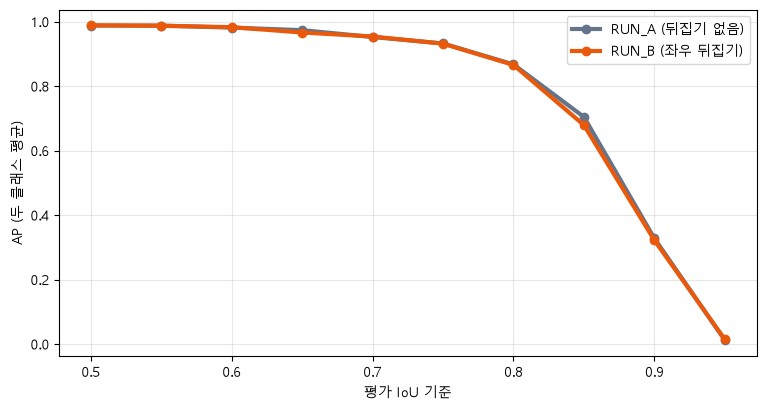

IoU 0.50: 고양이 A 0.987 → B 0.987 · 개 A 0.989 → B 0.990
IoU 0.75: 고양이 A 0.963 → B 0.970 · 개 A 0.901 → B 0.893
IoU 0.90: 고양이 A 0.437 → B 0.447 · 개 A 0.218 → B 0.196


In [39]:
# 왜 · 뒤집기 하나만 바꾼 RUN_B를 같은 절차로 학습하기 위해
hist_B, steps_B = fit("RUN_B", flip=True)       # 딱 하나만 다름: train 좌우 뒤집기 (p 0.5 · seed 1)
best_B = max(hist_B, key=lambda h: h["mAP50"])  # val로 고른 best
for name, best in (("RUN_A", best_A), ("RUN_B", best_B)):  # 두 학습
    print(f"{name} best: epoch {best['epoch']:2d} · val mAP50 {best['mAP50']:.4f}"  # best
          " · test 사용 False")

# 왜 · RUN_B best를 같은 val로 채점하기 위해
model_B = load_run("RUN_B")                                            # RUN_B best
preds_B_val = predict_all(model_B, VAL_IDS)                            # 같은 val · 같은 순서
# 개수
print("RUN_B 예측:", len(preds_B_val), "장 · 박스 합", sum(len(r["boxes"]) for r in preds_B_val))
sA, sB = ab_summary(preds_A_val), ab_summary(preds_B_val)              # 같은 평가 함수
print(f"{'val 551장':22s} {'RUN_A':>7s} {'RUN_B':>7s} {'B − A':>8s}")  # 표 머리
for key, name in [("AP50", "AP50"), ("AP75", "AP75"), ("AP50_95", "AP 0.50~0.95 평균")]:  # 세 지표
    print(f"{name:22s} {sA[key]:7.4f} {sB[key]:7.4f} {sB[key] - sA[key]:+8.4f}")  # 차이

fig, ax = plt.subplots(figsize=(9, 4.5))                                               # 기준별 AP
# 두 학습
pairs_ab = [("RUN_A (뒤집기 없음)", sA, "#64748b"), ("RUN_B (좌우 뒤집기)", sB, "#ea580c")]
for name, s, color in pairs_ab:                                                        # 학습마다
    ax.plot(IOU_THRS, list(s["curve"].values()), "o-", lw=3, color=color, label=name)  # 두 선
ax.set_xlabel("평가 IoU 기준")                                                         # x축
ax.set_ylabel("AP (두 클래스 평균)")                                                   # y축
ax.legend()                                                                            # 범례
ax.grid(alpha=0.3)                                                                     # 격자
plt.show()                                                                             # 그림 출력
for t in (0.5, 0.75, 0.9):                                                             # 세 기준
    print(f"IoU {t:.2f}: 고양이 A {sA['cat'][t]:.3f} → B {sB['cat'][t]:.3f} ·"         # 클래스별
          f" 개 A {sA['dog'][t]:.3f} → B {sB['dog'][t]:.3f}")

**결과** · 예측 정답은 둘 다 작음 — AP50 `+0.0008` · 0.50~0.95 평균 `-0.0035` (B가 낮음)

- `[RUN_B] epoch 2 · lr 1e-03 · 분류 1.340 · val mAP50 0.9067` — 뒤집기를 켜면 중간에 흔들림
- `RUN_B best: epoch  4 · val mAP50 0.9885 · test 사용 False` — best epoch는 A와 같음
- `AP50                    0.9877  0.9885  +0.0008` — AP50은 B가 조금 위
- `AP 0.50~0.95 평균         0.7725  0.7689  -0.0035` — 엄격한 기준은 B가 조금 아래
- `IoU 0.90: 고양이 A 0.437 → B 0.447 · 개 A 0.218 → B 0.196` — 클래스마다 방향이 다름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>AP50</td><td>꽉 참</td><td>차이 작음</td></tr>
<tr><td>AP75 · 0.50~0.95</td><td>엄격</td><td>차이가 보임</td></tr>
<tr><td>같은 val · 같은 함수</td><td>공정한 비교</td><td>필수</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - best epoch가 다르면 epoch 수 차이도 섞임 → 같은 epoch끼리도 비교 (10-2)

> ✅ **한 줄 정리** · 한 가지만 바꾼 두 학습은 같은 val과 평가 함수로 비교하고, 차이는 엄격한 기준에서 본다.

**딥러닝 코드에서는**

- 개선 기록 6칸: 무엇을 · 왜 · 전 · 후 · 말할 수 있는 것 · 말할 수 없는 것

### 10-2. `A` 오류 종류 · 같은 epoch끼리 · `val_epoch{n}_predictions.json` <sub>원본 D2-10 · 셀 263 ~ 269</sub>

> 🎯 **차이는 뒤집기 덕분인가, best epoch 차이 덕분인가?**

💡 **쉽게 말하면**

- 9장 도구 그대로 **오류 종류별 개수**를 비교.
- 저장해 둔 epoch별 예측으로 **같은 epoch끼리** 비교.

**실행 흐름**

1. 두 학습의 FN · FP · 느슨한 TP · 작은 얼굴
2. epoch마다 A · B의 세 지표 · 차이

**먼저 예측** · 같은 epoch끼리 비교해도 B가 늘 높을까? — 답은 코드 실행 결과 아래에

In [40]:
# 왜 · 두 RUN의 오류 종류를 같은 방법으로 비교하기 위해
ev_B, gt_B = err_events(preds_B_val), err_gt_table(preds_B_val)                  # 9장 도구 그대로
for name, ev, gt in [("RUN_A", ev_A, gt_A), ("RUN_B", ev_B, gt_B)]:              # 두 학습
    k = Counter(e["kind"] for e in ev)                                           # 세기
    loose = sum(e["kind"] == "TP" and e["iou"] < 0.75 for e in ev)               # 느슨한 TP
    _, n_small, f50, f75 = err_size_table(gt)[0]                                 # 긴 변 100 미만
    print(f"{name}: FN {k['FN']:2d} · FP {k['FP']:2d} · 느슨한 TP {loose:2d} ·"  # 오류 종류
          f" 작은 얼굴 {n_small}개 중 0.5로 {f50} · 0.75로 {f75}")

# 왜 · 같은 epoch끼리 비교해 학습 길이 차이를 없애기 위해
print("epoch | AP50 A · B      | AP75 A · B      |"  # 같은 epoch끼리 비교
      " 0.50~0.95 평균 A · B | 평균 차이 B − A")
for ep in range(1, EPOCHS + 1):                      # epoch마다
    # 저장한 예측
    s = {run: ab_summary(json.loads((RUNS / run / f"val_epoch{ep}_predictions.json").read_text()))
         for run in ("RUN_A", "RUN_B")}
    a, b = s["RUN_A"], s["RUN_B"]                    # 두 학습
    # 한 줄
    print(f"  {ep:2d}  | {a['AP50']:.4f} · {b['AP50']:.4f} | {a['AP75']:.4f} · {b['AP75']:.4f} |"
          f"   {a['AP50_95']:.4f} · {b['AP50_95']:.4f}   | {b['AP50_95'] - a['AP50_95']:+.4f}")

RUN_A: FN 12 · FP 17 · 느슨한 TP 26 · 작은 얼굴 127개 중 0.5로 117 · 0.75로 107
RUN_B: FN 14 · FP 17 · 느슨한 TP 25 · 작은 얼굴 127개 중 0.5로 117 · 0.75로 111
epoch | AP50 A · B      | AP75 A · B      | 0.50~0.95 평균 A · B | 평균 차이 B − A


   1  | 0.9726 · 0.9718 | 0.8389 · 0.8162 |   0.6684 · 0.6432   | -0.0252


   2  | 0.9658 · 0.9067 | 0.8456 · 0.7648 |   0.6776 · 0.6213   | -0.0564


   3  | 0.9789 · 0.9881 | 0.8856 · 0.8706 |   0.7039 · 0.6842   | -0.0197


   4  | 0.9877 · 0.9885 | 0.9322 · 0.9314 |   0.7725 · 0.7689   | -0.0035


**결과** · 예측 정답은 아님 — 0.50~0.95 평균은 epoch 1 ~ 4 모두 B가 낮음

- `RUN_A: FN 12 · FP 17 · 느슨한 TP 26 · 작은 얼굴 127개 중 0.5로 117 · 0.75로 107` — RUN_A
- `RUN_B: FN 14 · FP 17 · 느슨한 TP 25 · 작은 얼굴 127개 중 0.5로 117 · 0.75로 111` — 작은 얼굴만 조금 나음
- `   2  | 0.9658 · 0.9067 | 0.8456 · 0.7648 |   0.6776 · 0.6213   | -0.0564` — epoch 2에서 차이가 가장 큼
- `   4  | 0.9877 · 0.9885 | 0.9322 · 0.9314 |   0.7725 · 0.7689   | -0.0035` — 마지막에는 거의 같음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>best끼리</td><td>epoch가 다를 수 있음</td><td>공정성 확인</td></tr>
<tr><td>같은 epoch끼리</td><td>학습량이 같음</td><td>더 공정</td></tr>
<tr><td>학습 한 번씩</td><td>seed 하나</td><td>확정 결론 아님</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - seed를 바꿔 여러 번 학습해야 '늘 좋아진다'고 말할 수 있음

> ✅ **한 줄 정리** · 같은 epoch끼리 비교하고 학습이 한 번씩뿐임을 함께 적어야 개선 주장을 정직하게 할 수 있다.

**딥러닝 코드에서는**

- 이번 기록: 엄격한 기준에서 B가 조금 낮음 → '뒤집기는 효과가 없다'도 학습 한 번으로는 말할 수 없음

---
## 11. 종합 실습 · 고르고 · test 한 번 · 보고

> **이 장의 흐름**
>
> - 1 ~ 10장을 한 번에: val로 고르기 → test 한 번
> - 규칙 → 최종 모델 → test 예측 → 보고 8칸

<img src="images/pfo2_final.png" alt="규칙 먼저 → val 세 지표 → 최종 모델 → test 한 번" width="763">

**파이프라인 위치** · ⑥ 평가 → ⑧ 보고

> 🎯 **val로 고른 모델의 test 점수는 val보다 낮을까, 비슷할까?**

💡 **쉽게 말하면**

- test는 **고르는 데 한 번도 쓰지 않은 사진**.
- 규칙을 먼저 정하고, test 결과를 보고 다시 고르지 않음.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>규칙: val 세 지표가 모두 높은 쪽 · 엇갈리면 0.50~0.95 평균</td><td>10-1</td></tr>
<tr><td>2</td><td>최종 모델의 test 551장 예측 (test를 쓰는 유일한 줄)</td><td>6-2</td></tr>
<tr><td>3</td><td>AP 세 가지 (우리 평가 함수)</td><td>8-2</td></tr>
<tr><td>4</td><td>점수 0.5 · IoU 0.5 판정 → 정밀도 · 재현율 · F1</td><td>9-1</td></tr>
<tr><td>5</td><td>맞힌 박스 평균 IoU · TP · FP · FN → val · test 두 줄</td><td>8-3</td></tr>
</tbody></table>

**먼저 예측** · test 0.50~0.95 평균은 val과 0.02 이내일까? — 답은 코드 실행 결과 아래에

In [41]:
# 최종 모델 고르는 규칙 (test 보기 전에 정함): 셋 다 높으면 그쪽 · 엇갈리면 0.50~0.95 평균
# 왜 · test 결과를 보고 규칙을 바꾸는 일을 막기 위해
val_scores = {"RUN_A": sA, "RUN_B": sB}                                       # val 점수
keys = ["AP50", "AP75", "AP50_95"]                                            # 세 지표
b_higher = [val_scores["RUN_B"][k] > val_scores["RUN_A"][k] for k in keys]    # B가 높은 지표
if all(b_higher) or not any(b_higher):                                        # 한쪽이 모두 높으면
    final_name = "RUN_B" if all(b_higher) else "RUN_A"                        # 그쪽
    reason = "val 세 지표 모두 높음"                                          # 이유
else:                                                                         # 엇갈리면
    final_name = max(val_scores, key=lambda run: val_scores[run]["AP50_95"])  # 평균 기준
    reason = "엇갈림 → 0.50~0.95 평균"                                        # 이유
final_model = model_B if final_name == "RUN_B" else model_A                   # 고른 모델
preds_final_val = preds_B_val if final_name == "RUN_B" else preds_A_val       # 그 val 예측
print("B가 높은가 (AP50, AP75, 0.50~0.95 평균):", b_higher)                   # 비교
print("최종 모델:", final_name, "·", reason)                                  # 결정

# 왜 · 처음 보는 test에 한 번만 채점하기 위해
preds_final_test = predict_all(final_model, sorted(test))                # ← test를 쓰는 유일한 줄
s_test = ab_summary(preds_final_test)                                    # test 점수
ev_test = err_events(preds_final_test)                                   # 점수 0.5 · IoU 0.5
n_gt_t = Counter(lb for r in preds_final_test for lb in r["gt_labels"])  # 정답 수
# 분모
print(f"test {len(preds_final_test)}장 · 정답 고양이 얼굴 {n_gt_t[1]} · 개 얼굴 {n_gt_t[2]}")

B가 높은가 (AP50, AP75, 0.50~0.95 평균): [True, False, False]
최종 모델: RUN_A · 엇갈림 → 0.50~0.95 평균


test 551장 · 정답 고양이 얼굴 177 · 개 얼굴 374


**실행 흐름**

1. val · test 결과를 같은 형식으로 요약하는 final_report
2. val · test 보고 나란히 출력

In [42]:
# 왜 · val · test 결과를 같은 형식의 보고로 비교하기 위해
def final_report(s, ev):  # AP 세 가지 + 점수 0.5의 정밀도 · 재현율 · F1 + 맞힌 박스 평균 IoU
    k = Counter(e["kind"] for e in ev)                                             # 세기
    p, r_ = k["TP"] / (k["TP"] + k["FP"]), k["TP"] / (k["TP"] + k["FN"])           # 정밀도 · 재현율
    tp_iou = [e["iou"] for e in ev if e["kind"] == "TP"]                           # TP의 IoU
    return {"AP50": s["AP50"], "AP75": s["AP75"], "0.50~0.95 평균": s["AP50_95"],  # 여덟 칸
            "정밀도 (점수 0.5)": p, "재현율 (점수 0.5)": r_, "F1 (점수 0.5)": 2 * p * r_ / (p + r_),
            "맞힌 박스 평균 IoU": sum(tp_iou) / len(tp_iou),
            "TP · FP · FN": f"{k['TP']} · {k['FP']} · {k['FN']}"}


rep_val = final_report(val_scores[final_name], err_events(preds_final_val))  # val
rep_test = final_report(s_test, ev_test)                      # test
print(f"{final_name} best{'':12s} {'val':>8s} {'test':>8s}")  # 표 머리
for key in rep_val:                                           # 칸마다
    v, t = rep_val[key], rep_test[key]                        # 두 값
    if isinstance(v, float):                                  # 숫자 칸
        print(f"{key:20s} {v:>8.4f} {t:>8.4f}")               # 소수 넷째 자리
    else:                                                     # 글자 칸 (TP · FP · FN)
        print(f"{key:20s} {v:>8s} {t:>8s}")                   # 그대로
for t in (0.5, 0.75):                                         # 두 기준
    # 클래스별
    print(f"test 클래스별 AP (IoU {t}): 고양이 {s_test['cat'][t]:.4f} · 개 {s_test['dog'][t]:.4f}")

RUN_A best                  val     test
AP50                   0.9877   0.9865
AP75                   0.9322   0.9147
0.50~0.95 평균           0.7725   0.7592
정밀도 (점수 0.5)           0.9694   0.9673
재현율 (점수 0.5)           0.9782   0.9673
F1 (점수 0.5)            0.9738   0.9673
맞힌 박스 평균 IoU           0.8805   0.8768
TP · FP · FN         539 · 17 · 12 533 · 18 · 18
test 클래스별 AP (IoU 0.5): 고양이 0.9916 · 개 0.9814
test 클래스별 AP (IoU 0.75): 고양이 0.9723 · 개 0.8570


**결과** · 예측 정답은 비슷함 — 0.50~0.95 평균 val `0.7725` · test `0.7592` (차이 0.013)

- `B가 높은가 (AP50, AP75, 0.50~0.95 평균): [True, False, False]` — 엇갈림
- `최종 모델: RUN_A · 엇갈림 → 0.50~0.95 평균` — 미리 정한 규칙대로
- `test 551장 · 정답 고양이 얼굴 177 · 개 얼굴 374` — test 분모
- `AP50                   0.9877   0.9865` — val · test 거의 같음
- `0.50~0.95 평균           0.7725   0.7592` — test가 조금 낮음
- `F1 (점수 0.5)            0.9738   0.9673` — 점수 0.5 기준
- `맞힌 박스 평균 IoU           0.8805   0.8768` — 박스 정확도도 비슷
- `TP · FP · FN         539 · 17 · 12 533 · 18 · 18` — test 정답 551개 중 18개 놓침
- `test 클래스별 AP (IoU 0.75): 고양이 0.9723 · 개 0.8570` — 개 얼굴 위치가 덜 정확 (9장과 같은 경향)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>val</td><td>고르기 (epoch · 모델 · 기준)</td><td>여러 번</td></tr>
<tr><td>test</td><td>고른 모델 채점</td><td>마지막 한 번</td></tr>
<tr><td>미리 정한 규칙</td><td>결과 보기 전에</td><td>고르기가 test에 기울지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - test 결과를 보고 모델 · 기준을 다시 고르면 test가 val이 됨 → 새 test가 필요

> ✅ **한 줄 정리** · 최종 모델은 val로 미리 정한 규칙대로 고르고, test는 그 모델에 한 번만 써서 val과 나란히 보고한다.

**딥러닝 코드에서는**

- 미션 노트북 점검표: 나누기 · 첫 batch · 헤드 모양 · lr 기록 · best 기준 · 조건 · 오류 사진 · 개선 6칸

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. 나누기</td><td>모집단 3671장 → train 2569 · val 551 · test 551 · 겹침 0 · 고양이 비율 0.32</td><td>1장</td></tr>
<tr><td>2. Dataset · 증강</td><td>collate_fn · 첫 batch 점검 · 사진만 뒤집으면 IoU 0인 박스 523개</td><td>2 · 3장</td></tr>
<tr><td>3. 헤드 · 스모크</td><td>숫자만 바꾸면 91칸 · 새 헤드 (1, 8732, 3) · 15 step 분류 15.23 → 4.58</td><td>4 · 5장</td></tr>
<tr><td>4. 학습 · 채점</td><td>RUN_A best epoch 4 · val mAP50 0.9877 · 재현율 0.978 (학습 전 0.136)</td><td>6 · 7장</td></tr>
<tr><td>5. AP · 오류 · 비교</td><td>AP50 0.988 · AP75 0.932 · 작은 얼굴에서 놓침 · B는 엄격한 기준에서 못 이김</td><td>8 ~ 10장</td></tr>
<tr><td>6. test 한 번</td><td>RUN_A · test 0.50~0.95 평균 0.7592 (val 0.7725)</td><td>11장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td>나누기</td><td>모집단 · 층화 · 겹침 0 · 어제 본 사진은 train</td><td><code>train_test_split(stratify=)</code></td></tr>
<tr><td><code>A</code></td><td>Dataset · 묶기</td><td>ds[i] = (이미지, target) · 목록으로 묶기</td><td><code>collate_fn</code></td></tr>
<tr><td><code>A</code></td><td>증강</td><td>사진 + 박스 같이 · train에만</td><td><code>x1' = W - x2</code></td></tr>
<tr><td><code>A</code></td><td>헤드 교체</td><td>층을 새로 · 숫자만 바꾸면 91칸</td><td><code>SSDClassificationHead</code></td></tr>
<tr><td><code>A</code></td><td>스모크</td><td>모양 · 몇 step · 모드</td><td><code>check_head</code> · <code>train_step</code></td></tr>
<tr><td><code>A</code></td><td>학습 · 저장</td><td>epoch 끝 step() · last · best</td><td><code>StepLR</code> · <code>torch.save</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td>채점 · AP</td><td>점수 기준 · 평가 IoU · PR 넓이</td><td><code>match</code> · <code>ap_per_class</code></td></tr>
<tr><td><code>A</code></td><td>오류 · 비교</td><td>FN · FP · 느슨한 TP · 한 가지만 바꾸기</td><td><code>err_events</code></td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · 공식 test로 채점할 수 없는 이유는?
- **1-2** · 어제 본 사진은 어디에?
- **2-2** · 기본 묶기가 실패하는 이유는?
- **2-3** · collate_fn은?
- **3-1** · 사진만 뒤집으면?
- **3-2** · 좌우 뒤집기 박스 식은?
- **4-1** · `num_classes = 3`만 적으면?
- **5-4** · 학습 · 평가 모드의 반환은?
- **6-1** · `scheduler.step()`을 빼면?
- **6-4** · best는 무엇으로 고르나?
- **7-4** · 점수 기준을 올리면?
- **8-2** · AP50이 높은데 AP75가 낮다면?
- **10-2** · A/B 비교에서 말할 수 없는 것은?
- **11** · test는 언제 쓰나?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**10-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**11** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 너비 500 사진의 박스 `[30, 10, 130, 90]`과 `[400, 50, 480, 120]`을 한 번에 좌우로 뒤집기
2. epoch 6 · step_size 4 · lr 0.001 · gamma 0.1일 때 epoch마다 쓰는 lr 목록

In [43]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 3-3에서 뒤집기 확률을 0.2로 바꾸면 한 epoch에 뒤집힐 사진은 대략 몇 장?
2. 7-4에서 점수 기준을 0.9로 올리면 정밀도와 재현율은 각각 어느 쪽으로?
3. 11장 규칙에서 val 세 지표가 엇갈리고 0.50~0.95 평균이 같다면?

In [44]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · 머리 박스 XML이 0개
- **1-2** · train (test는 처음 보는 사진)
- **2-2** · 사진 크기 · 박스 수가 달라 쌓을 수 없음
- **2-3** · `tuple(zip(*batch))` → 이미지 목록 · target 목록
- **3-1** · 에러 없이 박스가 틀어짐 · 숫자 점검 통과
- **3-2** · x1' = W - x2 · x2' = W - x1
- **4-1** · 층은 91칸 그대로 · 손실도 에러 없음
- **5-4** · 손실 dict · 예측 list
- **6-1** · 에러 없이 lr이 그대로
- **6-4** · val mAP50 (test 안 씀)
- **7-4** · FP ↓ · FN ↑ → 정밀도 ↑ · 재현율 ↓
- **8-2** · 찾기는 하지만 박스가 느슨함
- **10-2** · 늘 이만큼 좋아진다 · 전부 그 변경 덕분
- **11** · 규칙으로 고른 모델에 마지막 한 번

#### 코드 문제 답

```python
# 1. x1' = W - x2 · x2' = W - x1 (두 변이 자리를 바꿈)
b = torch.tensor([[30., 10., 130., 90.], [400., 50., 480., 120.]])
flipped = torch.stack([500 - b[:, 2], b[:, 1], 500 - b[:, 0], b[:, 3]], 1)
print(flipped[0].tolist())  # [370.0, 10.0, 470.0, 90.0]
print(flipped[1].tolist())  # [20.0, 50.0, 100.0, 120.0]

# 2. epoch 끝마다 step() → 4 epoch를 쓴 뒤 1/10
lrs = [round(0.001 * 0.1 ** (e // 4), 6) for e in range(6)]
print(lrs)  # [0.001, 0.001, 0.001, 0.001, 0.0001, 0.0001]
```

#### 변형 문제 답

*문제 → 답*

- **1** · 약 2569 × 0.2 = 514장 안팎 (seed에 따라 조금 다름 · 직접 실행)
- **2** · 정밀도 ↑ (또는 그대로) · 재현율 ↓ — FP가 줄고 FN이 늘어남
- **3** · 규칙에 없는 경우 → 결과 보기 전에 다음 규칙(예: 단순한 모델)을 미리 정해 둠

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) <code>num_classes = 3</code>만 적고 학습</td><td>속성 숫자 = 층의 출력 칸 수라고 생각</td><td>층은 만들 때 칸 수가 정해짐 · 헤드를 새로</td><td>점수 모양 마지막 숫자를 확인했나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 사전학습 탐지 모델을 내 클래스로 바꾸는 방법은?**
> - 분류 헤드를 내 클래스 수(배경 포함)로 새로 만들어 끼우고, 몸통과 위치 헤드는 사전학습 값에서 시작합니다.
> - 속성 숫자만 바꾸면 이미 만든 층의 출력 칸 수는 그대로라 에러 없이 틀린 학습이 되므로, 학습 전에 클래스 점수 모양의 마지막 숫자를 확인합니다.

**Q2. 탐지에서 데이터 증강을 할 때 주의할 점은?**
> - 사진과 박스를 같은 변환으로 함께 바꿔야 합니다.
> - 좌우 뒤집기는 x1' = W - x2, x2' = W - x1이고, 사진만 바꾸면 에러 없이 정답이 틀어집니다.
> - 증강은 train에만 쓰고 val과 test는 고정합니다.

**Q3. mAP 0.99라는 결과를 어떻게 읽어야 하나요?**
> - 어떤 IoU 기준인지, 어떤 split과 분모인지, 어떤 계산 방식인지 함께 봐야 합니다.
> - AP50은 IoU 0.5만 넘으면 맞힌 것으로 세므로, 박스가 얼마나 딱 맞는지는 AP75나 0.50~0.95 평균으로 확인합니다.

**Q4. 두 학습 결과를 비교해 개선을 주장하려면?**
> - 한 가지만 바꾸고 같은 val과 같은 평가 함수로 비교합니다.
> - best epoch가 다르면 같은 epoch끼리도 비교하고, 학습이 한 번씩이면 확정 결론이 아님을 함께 적습니다.
> - 최종 모델은 미리 정한 규칙으로 고르고 test는 마지막에 한 번만 씁니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>train_test_split(stratify=)</code></td><td>sklearn.model_selection</td><td>품종 층화 나누기</td><td>1-2 <code>train_test_split(pool, test_size=1102, stratify=...)</code></td></tr>
<tr><td><code>Dataset</code> · <code>DataLoader</code></td><td>torch.utils.data</td><td>한 장 · 묶음</td><td>2-1 <code>class PetFaces(Dataset)</code></td></tr>
<tr><td><code>collate_fn</code></td><td>직접 만든 함수</td><td>목록으로 묶기</td><td>2-3 <code>tuple(zip(*batch))</code></td></tr>
<tr><td><code>hflip()</code></td><td>직접 만든 함수</td><td>사진 + 박스 좌우 뒤집기</td><td>3-2 <code>image.flip(-1)</code> · <code>flip_boxes</code></td></tr>
<tr><td><code>SSDClassificationHead()</code></td><td>torchvision.models.detection.ssd</td><td>분류 헤드 교체</td><td>4-2 <code>SSDClassificationHead(in_channels, num_anchors, 3)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>model.train()</code> · <code>model.eval()</code></td><td>nn.Module</td><td>손실 dict · 예측 list</td><td>5-4 <code>smoke_model(xs, ts)</code></td></tr>
<tr><td><code>StepLR</code> · <code>scheduler.step()</code></td><td>torch.optim.lr_scheduler</td><td>lr 일정</td><td>6-1 <code>StepLR(opt, step_size=STEP_SIZE, gamma=0.1)</code></td></tr>
<tr><td><code>torch.save()</code> · <code>torch.load()</code></td><td>torch</td><td>checkpoint</td><td>6-6 <code>torch.load(best_path, weights_only=False)</code></td></tr>
<tr><td><code>match()</code> · <code>show()</code></td><td>직접 만든 함수</td><td>점수 · IoU 기준 채점</td><td>7-2 <code>match(preds_A_val, 0.5, 0.5)</code></td></tr>
<tr><td><code>ap_per_class()</code> · <code>ab_summary()</code></td><td>직접 만든 함수</td><td>AP · IoU 기준별 AP</td><td>8-2 <code>ab_summary(recs)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>err_events()</code></td><td>직접 만든 함수</td><td>TP · FP · FN 판정 목록</td><td>9-1 <code>err_events(preds_A_val)</code></td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>정답 있는 사진 안에서 나누기</td><td>정답 없는 공식 test로 채점</td></tr>
<tr><td>사진 + 박스를 함께 증강</td><td>사진만 뒤집기</td></tr>
<tr><td>분류 헤드를 새로 끼우기</td><td><code>num_classes</code> 숫자만 바꾸기</td></tr>
<tr><td>epoch 끝마다 <code>scheduler.step()</code> · lr 기록</td><td>step() 없이 lr이 줄었다고 믿기</td></tr>
<tr><td>best는 val로 · test는 마지막 한 번</td><td>test 결과 보고 다시 고르기</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>val vs test</td><td>고르기 vs 마지막 채점</td><td>test는 한 번</td></tr>
<tr><td>기본 묶기 vs collate_fn</td><td>쌓기 vs 목록</td><td>탐지는 collate_fn</td></tr>
<tr><td>학습 모드 vs 평가 모드</td><td>손실 dict vs 예측 list</td><td>평가 뒤 train()</td></tr>
<tr><td>last.pt vs best.pt</td><td>마지막 vs val 최고</td><td>이어 학습 vs 평가</td></tr>
<tr><td>점수 기준 vs 평가 IoU</td><td>예측 거르기 vs 짝짓기 기준</td><td>결과에 둘 다 적기</td></tr>
<tr><td>AP50 vs 0.50~0.95 평균</td><td>찾았나 vs 딱 맞나</td><td>위치 정확도는 엄격한 기준</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제를 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개 · 3-2 뒤집기 식과 4-2 헤드 교체를 종이에 다시</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>1 · 2 · 5장 코드를 보지 않고 다시 짜기 (나누기 · Dataset · 스모크)</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>오답 노트에 남은 문제만 · 파일별 3(평가지표 보충) 시작 전 ✅ 줄만 읽기</td><td>10분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 · `객체인식_Day02.html` 281셀을 D2-0 ~ D2-11 순서 그대로 10장 38섹션 + 11장 종합 실습으로
- Mac MPS · 데이터 경로 → CUDA · kagglehub 캐시 · Mac 글꼴 → Malgun Gothic · 그림 색은 흰 배경용
- 원본의 미리 학습한 10 epoch 기록 · 나눈 목록 파일이 없어 4 epoch로 직접 학습 (숫자는 원본과 다름)
- 모든 코드는 실행한 출력과 함께 저장 · 형식 v2.1 (FORMAT_V2.md 1 ~ 7절)

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>셀 0 ~ 4 · 9 ~ 11</td><td>표지 · 라이브러리 · 도우미 · 환경 확인</td><td>0장</td></tr>
<tr><td>D2-0 · 셀 5 ~ 8</td><td>오늘 할 일 · 흐름</td><td>0장 원본 구성</td></tr>
<tr><td>D2-1 · 셀 12 ~ 29</td><td>공식 목록 · 어제 본 사진 · 층화 · 확인</td><td>1-1 ~ 1-3</td></tr>
<tr><td>D2-2 · 셀 30 ~ 60</td><td>Dataset · 묶기 · collate_fn · 첫 batch · EDA</td><td>2-1 ~ 2-5</td></tr>
<tr><td>D2-3 · 셀 61 ~ 86</td><td>사진만 뒤집기 · 박스도 · train에만 · 상하 · 회전</td><td>3-1 ~ 3-4</td></tr>
<tr><td>D2-4 · 셀 87 ~ 112</td><td>미션 예시 코드 · 새 헤드 · 학습 전 예측</td><td>4-1 ~ 4-3</td></tr>
<tr><td>D2-5 · 셀 113 ~ 131</td><td>모양 · 15 step · 잘못 뒤집기 · 모드</td><td>5-1 ~ 5-4</td></tr>
<tr><td>D2-6 · 셀 132 ~ 172</td><td>시간 · lr · 루프 · 20 step · 기록 · best · checkpoint</td><td>6-1 ~ 6-6</td></tr>
<tr><td>D2-7 · 셀 173 ~ 212</td><td>준비 · 채점 · 학습 전 · 점수 기준 · 평가 IoU</td><td>7-1 ~ 7-5</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>D2-8 · 셀 213 ~ 233</td><td>AP · PR 곡선 · 기준별 AP · 평균 IoU</td><td>8-1 ~ 8-3</td></tr>
<tr><td>D2-9 · 셀 234 ~ 252</td><td>판정 · FN · FP · 느슨한 TP · 크기별 · 가설</td><td>9-1 ~ 9-3</td></tr>
<tr><td>D2-10 · 셀 253 ~ 269</td><td>RUN_B · 차이 · 같은 epoch · 기록 6칸</td><td>10-1 · 10-2</td></tr>
<tr><td>D2-11 · 셀 270 ~ 280</td><td>고르는 규칙 · test 한 번 · 점검표</td><td>11</td></tr>
</tbody></table>

### 전체 코드

1 ~ 11장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 1-1 공식 목록 · 모집단
2. 1-2 본 사진 빼기 · 품종 층화 나누기

In [45]:
from sklearn.model_selection import train_test_split  # 층화 나누기


# ---------- 1-1 ----------
# 왜 · 공식 목록 파일에서 사진 이름만 꺼내기 위해
def read_list(name):                               # 공식 목록 파일 → 이름 목록 (파일 순서 그대로)
    lines = (ANN / name).read_text().splitlines()  # 줄 목록
    return [line.split()[0] for line in lines if line.strip() and not line.startswith("#")]  # 첫 칸


# 왜 · 정답 XML이 있는 사진만 모집단으로 삼기 위해
trainval, official_test = read_list("trainval.txt"), read_list("test.txt")  # 공식 두 목록
has_xml = {p.stem for p in XMLS.glob("*.xml")}                              # 정답 XML이 있는 이름
# 3671
print("공식 trainval:", len(trainval), "장 · 그중 XML 있음", sum(i in has_xml for i in trainval))
print("공식 test    :", len(official_test), "장 · 그중 XML 있음",           # 0
      sum(i in has_xml for i in official_test))
print("두 목록 밖 XML:", len(has_xml - set(trainval) - set(official_test)), "개")  # list에 없는 XML

# 왜 · 모집단의 클래스 비율을 먼저 확인하기 위해
population = [i for i in trainval if i in has_xml]           # 공식 순서 유지 → 다시 해도 같은 결과
# 클래스별 박스
boxes = Counter(name for i in population for name in read_voc(XMLS / f"{i}.xml")[1])
print("모집단:", len(population), "장 · 박스", dict(boxes))  # 채점까지 쓸 수 있는 사진


# ---------- 1-2 ----------

# 파일별 1(Day01)에서 본 사진 → test에 들어가지 않게 train으로
# 왜 · 이미 본 사진이 test에 들어가 점수가 부풀려지는 것을 막기 위해
seen = ["Ragdoll_155", "english_setter_124", "boxer_123", "Egyptian_Mau_116", "Siamese_206",  # 1장
        "Birman_137", "Bombay_148", "miniature_pinscher_107", "keeshond_134", "samoyed_187",
        # 2 · 4장
        "wheaten_terrier_114", "great_pyrenees_126", "Abyssinian_173", "Russian_Blue_123",
        "Birman_164", "Birman_151", "leonberger_142", "Abyssinian_140", "chihuahua_138",  # 5 · 6장
        # 6 ~ 9장
        "basset_hound_131", "Bengal_105", "Birman_123", "pomeranian_114", "Abyssinian_10",
        "Bengal_101", "american_bulldog_121", "newfoundland_104", "basset_hound_102",
        "British_Shorthair_116", "Sphynx_114", "keeshond_104"]
pop_set = set(population)                                                     # 빠른 검사용
seen_in = [i for i in seen if i in pop_set]                                   # 모집단 안에 있는 것
print("어제 본 사진:", len(seen), "장 · 모집단 안", len(seen_in), "장 · 밖",  # 모두 trainval?
      [i for i in seen if i not in pop_set])


# 왜 · 품종 비율을 유지해 나누려면 품종 이름이 필요하기 때문에
def breed_of(ids):                             # 사진 이름 → 품종 (Abyssinian_140 → Abyssinian)
    return [i.rsplit("_", 1)[0] for i in ids]  # 마지막 _ 뒤 번호 떼기


# 왜 · 품종 비율을 유지한 채 train · val · test로 나누기 위해
pool = [i for i in population if i not in set(seen_in)]             # 어제 본 사진은 먼저 뺌
# 1102장 떼기
rest, hold = train_test_split(pool, test_size=1102, stratify=breed_of(pool), random_state=42)
val, test = train_test_split(hold, test_size=551, stratify=breed_of(hold), random_state=42)  # 반씩
train = rest + seen_in                                              # 어제 본 사진은 train으로
print("train", len(train), "· val", len(val), "· test", len(test))  # 원본과 같은 장수

# 왜 · 층화 없이 나누면 품종 비율이 얼마나 흔들리는지 비교하기 위해
_, hold2 = train_test_split(pool, test_size=1102, random_state=42)   # 품종 비율 무시
val2, _ = train_test_split(hold2, test_size=551, random_state=42)    # 무작위 val
for name, ids in [("무작위 val   ", val2), ("품종 층화 val", val)]:  # 두 val 비교
    c = Counter(breed_of(ids))                                       # 품종별 장수
    print(f"{name}: 품종 {len(c)}개 · 품종당 {min(c.values())} ~ {max(c.values())}장")  # 고른가

공식 trainval: 3680 장 · 그중 XML 있음 3671
공식 test    : 3669 장 · 그중 XML 있음 0
두 목록 밖 XML: 15 개


모집단: 3671 장 · 박스 {'cat': 1182, 'dog': 2490}
어제 본 사진: 31 장 · 모집단 안 31 장 · 밖 []
train 2569 · val 551 · test 551
무작위 val   : 품종 37개 · 품종당 10 ~ 24장
품종 층화 val: 품종 37개 · 품종당 13 ~ 16장


**실행 흐름**

1. 1-3 겹침 · 클래스 비율 · 저장

In [46]:
# ---------- 1-3 ----------
# 왜 · 세 묶음이 겹치지 않고 클래스 비율이 비슷한지 확인하기 위해
groups = {"train": train, "val": val, "test": test}                                 # 세 묶음
sets = {g: set(ids) for g, ids in groups.items()}                                   # 집합으로
print("겹침 (train∩val, train∩test, val∩test):", len(sets["train"] & sets["val"]),  # 0이어야 함
      len(sets["train"] & sets["test"]), len(sets["val"] & sets["test"]))
print("어제 본 사진 모두 train:", set(seen_in) <= sets["train"])                    # True
for g, ids in groups.items():                                                       # 묶음마다
    c = Counter(name for i in ids for name in read_voc(XMLS / f"{i}.xml")[1])       # 클래스별 박스
    print(f"{g:5s} {len(ids):5d}장 · 박스 cat {c['cat']:4d} · dog {c['dog']:4d}"    # 비율이 같은가
          f" · 고양이 비율 {c['cat'] / sum(c.values()):.2f}")

# 왜 · 나눈 결과를 파일로 남겨 다음 실행에서도 같은 나눔을 쓰기 위해
SPLIT_DIR = RUNS / "split"                                   # 나눈 목록 저장 (원본 day02/split)
SPLIT_DIR.mkdir(exist_ok=True)                               # 폴더
for g, ids in groups.items():                                # 묶음마다
    (SPLIT_DIR / f"{g}_ids.txt").write_text("\n".join(ids))  # 순서 그대로 저장
saved = {g: (SPLIT_DIR / f"{g}_ids.txt").read_text().split() for g in groups}  # 다시 읽기
print("저장한 목록과 같은 사진 집합:", all(saved[g] == ids for g, ids in groups.items()))  # 같은가

겹침 (train∩val, train∩test, val∩test): 0 0 0
어제 본 사진 모두 train: True


train  2569장 · 박스 cat  829 · dog 1741 · 고양이 비율 0.32
val     551장 · 박스 cat  176 · dog  375 · 고양이 비율 0.32


test    551장 · 박스 cat  177 · dog  374 · 고양이 비율 0.32
저장한 목록과 같은 사진 집합: True


**실행 흐름**

1. 2-1 make_target · Dataset

In [47]:
from torch.utils.data import DataLoader, Dataset  # 한 장씩 · 묶어서
from torch.utils.data import default_collate      # 기본 묶기 함수


# ---------- 2-1 ----------

# 왜 · torchvision 탐지 모델이 0번을 배경으로 쓰기 때문에
CLASSES = ["배경", "고양이 얼굴", "개 얼굴"]  # 번호 0, 1, 2
NAME_TO_LABEL = {"cat": 1, "dog": 2}          # 0은 배경 자리


# 왜 · 탐지 모델이 요구하는 boxes · labels 형식으로 맞추기 위해
def make_target(stem):                                        # Day01 7-4 그대로: XML → target
    bxs, names = read_voc(XMLS / f"{stem}.xml")               # 박스 · 이름
    return {"boxes": torch.tensor(bxs, dtype=torch.float32),  # [N, 4] xyxy
            "labels": torch.tensor([NAME_TO_LABEL[n] for n in names], dtype=torch.int64)}  # [N]


# 왜 · 박스 1개 · 2개인 사진에서 target 모양을 확인하기 위해
print(make_target("Abyssinian_173"))  # 박스 1개
print(make_target("Bengal_105"))      # 박스 2개


# 왜 · DataLoader가 사진 한 장씩 꺼낼 수 있게 약속된 형식으로 돌려주기 위해
class PetFaces(Dataset):                                  # 사진 이름 목록 → ds[i] = (image, target)
    def __init__(self, ids, flip=False):                  # 이름 목록 · 뒤집기 여부
        self.ids = list(ids)                              # 순서 고정
        self.flip = flip                                  # 좌우 뒤집기 (3장) · 기본 끔
        self.flip_gen = torch.Generator().manual_seed(1)  # 뒤집기 전용 난수

    def __len__(self):        # 사진 수
        return len(self.ids)  # DataLoader가 씀

    def __getitem__(self, i):                                           # i번째 → 한 쌍
        stem = self.ids[i]                                              # 이름
        image = TF.to_tensor(load_image(stem))                          # [3, H, W] · 0~1
        target = make_target(stem)                                      # 정답
        if self.flip and torch.rand(1, generator=self.flip_gen) < 0.5:  # 절반 확률
            image, target = hflip(image, target)                        # 3장에서 만듦
        return image, target                                            # 한 샘플


# 왜 · 저장한 나눔 파일로 Dataset을 만들어 나눔이 바뀌지 않게 하기 위해
train_ds = PetFaces(saved["train"])  # 1장 저장 목록 (학습과 같은 순서)
val_ds = PetFaces(saved["val"])                                             # val
print("train_ds:", len(train_ds), "장 · val_ds:", len(val_ds), "장")        # 장수
image, target = train_ds[0]                                                 # 0번
print("0번:", train_ds.ids[0], "· image", tuple(image.shape), image.dtype)  # 모양
print("     target:", target)                                               # 정답

{'boxes': tensor([[241.,  31., 310., 102.]]), 'labels': tensor([1])}
{'boxes': tensor([[ 49., 125., 111., 168.],
        [397., 103., 451., 132.]]), 'labels': tensor([1, 1])}
train_ds: 2569 장 · val_ds: 551 장
0번: english_setter_136 · image (3, 500, 353) torch.float32
     target: {'boxes': tensor([[146.,  19., 301., 148.]]), 'labels': tensor([2])}


**실행 흐름**

1. 2-2 기본 묶기 실패
2. 2-3 collate_fn · DataLoader
3. 2-4 첫 batch 점검

In [48]:
# ---------- 2-2 ----------

# 왜 · 기본 묶기가 탐지 데이터에서 왜 실패하는지 에러로 확인하기 위해
plain_loader = DataLoader(train_ds, batch_size=16, shuffle=False)  # collate_fn 없이
try:
    next(iter(plain_loader))                                       # 첫 묶음
    print("묶기 성공")                                             # 되면
except Exception as e:                                             # 안 되면
    print(type(e).__name__, ":", str(e).splitlines()[0])           # 에러 첫 줄

# 왜 · 박스 수가 같으면 target은 쌓이지만 사진 크기 때문에 여전히 실패함을 보이기 위해
one_box = [s for s in train_ds.ids if len(read_voc(XMLS / f"{s}.xml")[0]) == 1]  # 박스 1개 사진
ones = default_collate([make_target(s) for s in one_box[:16]])                   # 16개 묶기
print("박스 1개 target 16개 → 묶임:", {k: tuple(v.shape) for k, v in ones.items()})  # 조용히 성공
try:
    default_collate([make_target("Abyssinian_173"), make_target("Bengal_105")])  # 1개 + 2개
except Exception as e:                                                           # 모양이 달라 실패
    print("Bengal_105가 끼면 →", type(e).__name__, ":", str(e).splitlines()[0])  # 에러 첫 줄


# ---------- 2-3 ----------
# 왜 · 크기 · 박스 수가 달라도 묶음을 만들 수 있게 쌓지 않고 목록으로 두기 위해
def collate_fn(batch):         # [(img, t), ...] → ((img, ...), (t, ...))
    return tuple(zip(*batch))  # 쌓지 않고 목록으로


# 왜 · collate_fn 결과 형식을 두 장으로 먼저 확인하기 위해
images, targets = collate_fn([train_ds[0], train_ds[1]])      # 두 장 묶기
print("images :", type(images).__name__, len(images), "·",    # 크기가 달라도 그대로
      [tuple(im.shape) for im in images])
print("targets:", type(targets).__name__, len(targets), "·",  # target 목록
      [tuple(t["boxes"].shape) for t in targets])

# 왜 · 섞는 순서를 seed로 고정해 RUN끼리 같은 순서로 학습하기 위해
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0,  # 섞음 · seed 0
                          generator=torch.Generator().manual_seed(0), collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0,     # 순서 그대로
                        collate_fn=collate_fn)
print("train batch 수:", len(train_loader), "· val batch 수:", len(val_loader))  # 161 · 35


# ---------- 2-4 ----------
# 왜 · 학습 도중이 아니라 시작 전에 형식 실수를 assert로 잡기 위해
def check_batch(images, targets):                               # batch 하나가 약속을 지키는지
    assert len(images) == len(targets)                          # 같은 수
    for im, t in zip(images, targets):                          # 사진마다
        b, lab = t["boxes"], t["labels"]                        # 박스 · 라벨
        # 이미지
        assert im.dtype == torch.float32 and im.shape[0] == 3 and 0 <= im.min() and im.max() <= 1
        assert b.dtype == torch.float32 and b.ndim == 2 and b.shape[1] == 4  # [N, 4] 실수
        assert lab.dtype == torch.int64 and len(lab) == len(b)  # 정수 · 같은 수
        assert (b[:, 0] < b[:, 2]).all() and (b[:, 1] < b[:, 3]).all()  # x1 < x2 · y1 < y2
        assert (b[:, :2] >= 0).all()                            # 왼쪽 · 위 변이 사진 안
        assert (b[:, 2] <= im.shape[2]).all() and (b[:, 3] <= im.shape[1]).all()  # 오른쪽 · 아래 변
        assert set(lab.tolist()) <= {1, 2}                      # 0(배경) 없음
    print(f"{len(images)}장 점검 통과")                         # 통과

RuntimeError : stack expects each tensor to be equal size, but got [3, 500, 353] at entry 0 and [3, 333, 500] at entry 1


박스 1개 target 16개 → 묶임: {'boxes': (16, 1, 4), 'labels': (16, 1)}
Bengal_105가 끼면 → RuntimeError : stack expects each tensor to be equal size, but got [1, 4] at entry 0 and [2, 4] at entry 1
images : tuple 2 · [(3, 500, 353), (3, 333, 500)]
targets: tuple 2 · [(1, 4), (1, 4)]
train batch 수: 161 · val batch 수: 35


**실행 흐름**

1. 2-4 첫 batch 사진 · 정답 그림
2. 2-5 train 얼굴 크기 분포

16장 점검 통과
사진 크기 (H, W): [(500, 355), (225, 300), (489, 500), (500, 327)] ...
라벨: ['고양이 얼굴', '개 얼굴', '개 얼굴', '고양이 얼굴', '고양이 얼굴', '고양이 얼굴'] ...


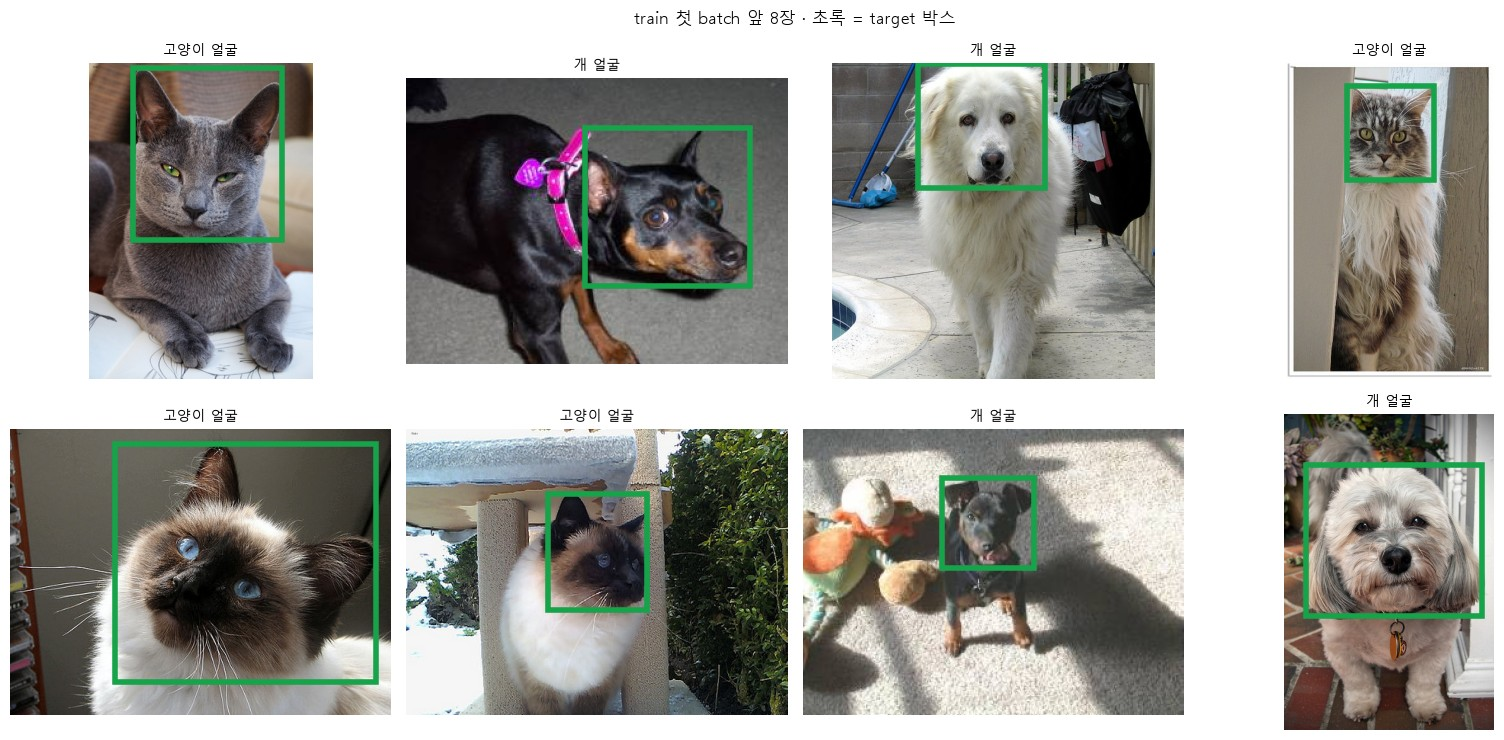

사진 장치: cuda · 박스 장치: cuda


train 사진 2569 장 · 박스 2570 개
cat: 박스  829 (32%) · 긴 변 가운데 138 · 50 미만  7개 (0.8%)
dog: 박스 1741 (68%) · 긴 변 가운데 142 · 50 미만 23개 (1.3%)


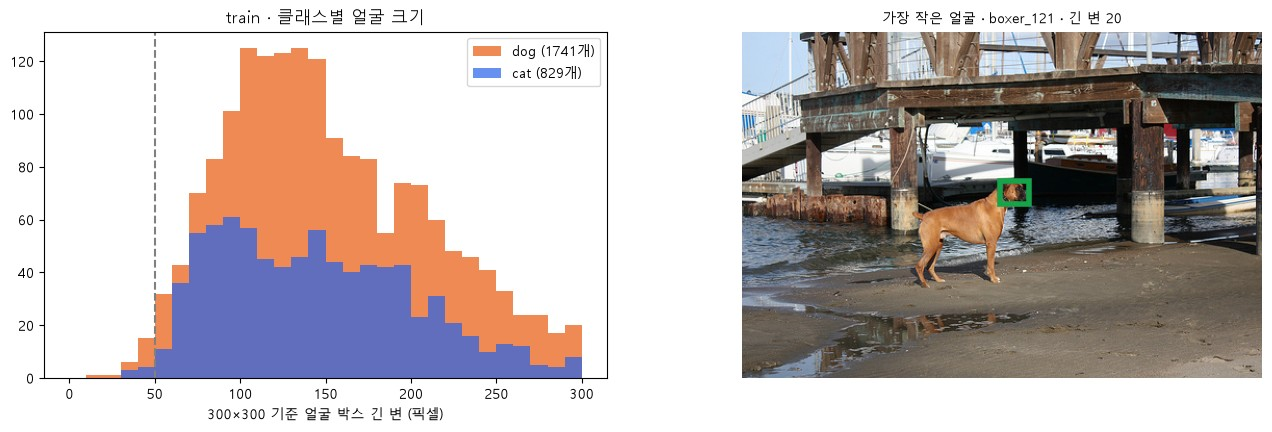

In [49]:
images, targets = next(iter(train_loader))                                     # 첫 batch
check_batch(images, targets)                                                   # 숫자 약속 확인
print("사진 크기 (H, W):", [tuple(im.shape[1:]) for im in images[:4]], "...")  # 제각각
print("라벨:", [CLASSES[lb] for t in targets for lb in t["labels"].tolist()][:6], "...")  # 앞 6개

# 왜 · 첫 batch의 사진과 정답 박스가 맞는지 눈으로 확인하기 위해
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))                        # 앞 8장
for ax, im, t in zip(axes.flat, images, targets):                        # 사진마다
    draw(im.permute(1, 2, 0), gt=t["boxes"], ax=ax,                      # [3, H, W] → [H, W, 3]
         title=" · ".join(CLASSES[lb] for lb in t["labels"].tolist()))
plt.suptitle("train 첫 batch 앞 8장 · 초록 = target 박스", fontsize=12)  # 제목
plt.tight_layout()                                                       # 여백
plt.show()                                                               # 그림 출력

# 왜 · 사진과 정답을 같은 장치로 옮겨야 모델이 받기 때문에
images_dev = [im.to(DEVICE) for im in images]                             # 장치로
targets_dev = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]  # 정답도
# 같은 장치
print("사진 장치:", images_dev[0].device.type, "· 박스 장치:", targets_dev[0]["boxes"].device.type)


# ---------- 2-5 ----------
# 왜 · 얼굴 크기 분포를 보고 작은 물체가 얼마나 있는지 알기 위해
def face_sides(ids):  # [(사진, cat/dog, 300 기준 얼굴 긴 변)]
    rows = []                                                                         # 결과
    for stem in ids:                                                                  # 사진마다
        root = ET.parse(XMLS / f"{stem}.xml").getroot()                               # XML
        w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))    # 크기
        for (x1, y1, x2, y2), name in zip(*read_voc(XMLS / f"{stem}.xml")):           # 박스마다
            rows.append((stem, name, max((x2 - x1) / w * 300, (y2 - y1) / h * 300)))  # 긴 변
    return rows                                                                       # 목록


# 왜 · train 박스 수와 얼굴 크기 범위를 숫자로 확인하기 위해
rows = face_sides(train_ds.ids)                                   # train 전체
print("train 사진", len(train_ds), "장 · 박스", len(rows), "개")  # 박스 2개 사진 포함
for name in ["cat", "dog"]:                                       # 클래스마다
    s = torch.tensor([v for _, n, v in rows if n == name])        # 긴 변
    # 분포
    print(f"{name}: 박스 {len(s):4d} ({len(s) / len(rows):.0%}) · 긴 변 가운데 {s.median():.0f}"
          f" · 50 미만 {(s < 50).sum().item():2d}개 ({(s < 50).float().mean():.1%})")

# 왜 · 고양이 · 개 얼굴 크기 분포를 나란히 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))             # 크기 분포 · 가장 작은 얼굴
for name, color in [("dog", "#ea580c"), ("cat", "#2563eb")]:  # 두 클래스
    # 히스토그램
    axes[0].hist([v for _, n, v in rows if n == name], bins=range(0, 310, 10), alpha=0.7,
                 color=color, label=f"{name} ({sum(n == name for _, n, _ in rows)}개)")
axes[0].axvline(50, color="gray", ls="--")                    # 50 기준선
axes[0].set_xlabel("300×300 기준 얼굴 박스 긴 변 (픽셀)")     # x축
axes[0].set_title("train · 클래스별 얼굴 크기", fontsize=12)  # 제목
axes[0].legend()                                              # 범례
small = sorted(rows, key=lambda r: r[2])[0]                   # 가장 작은 얼굴
im, t = train_ds[train_ds.ids.index(small[0])]                # 그 사진
draw(im.permute(1, 2, 0), gt=t["boxes"], ax=axes[1],          # 멀리 찍힌 동물
     title=f"가장 작은 얼굴 · {small[0]} · 긴 변 {small[2]:.0f}")
plt.show()                                                    # 그림 출력

**실행 흐름**

1. 3-1 사진만 뒤집기
2. 3-2 박스도 뒤집기

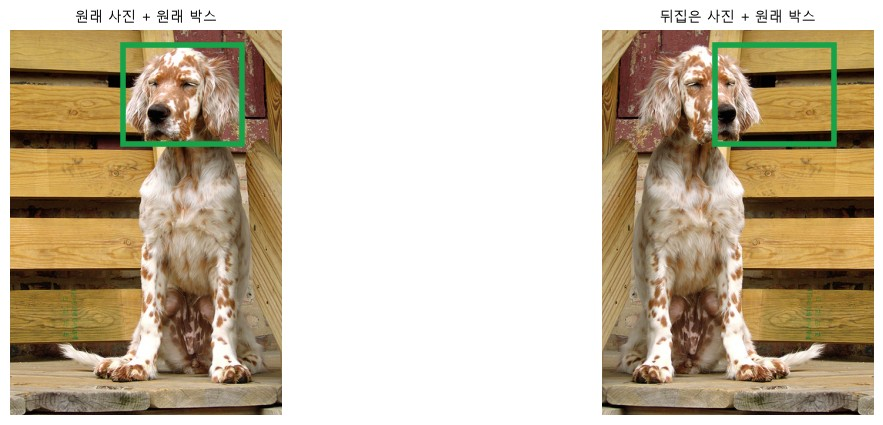

사진 안       : True
x1 < x2, y1 < y2: True
박스 숫자      : [[146.0, 19.0, 301.0, 148.0]] ← 뒤집기 전과 똑같음


train 박스 2570 개 · 사진만 뒤집었을 때 원래 박스와 실제 얼굴의 IoU
IoU 0 (완전히 빗나감): 523개 · IoU 0.5 이상 (겉보기엔 맞음): 1252개 (49%)


In [50]:
from torchvision import tv_tensors                      # 박스 텐서 형식
from torchvision.ops import box_iou                     # IoU 표
from torchvision.transforms.v2 import functional as F2  # 박스까지 뒤집어 주는 함수


# ---------- 3-1 ----------

# 왜 · 사진만 뒤집으면 박스가 얼굴 자리에서 벗어나는 것을 보기 위해
stem = train_ds.ids[0]                                             # train 0번 사진
image, target = TF.to_tensor(load_image(stem)), make_target(stem)  # 사진 · 정답
flipped = TF.hflip(image)                                          # 사진만 좌우로 · 박스는 그대로
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                    # 2칸
draw(image.permute(1, 2, 0), gt=target["boxes"], ax=axes[0], title="원래 사진 + 원래 박스")  # 맞음
# 어긋남
draw(flipped.permute(1, 2, 0), gt=target["boxes"], ax=axes[1], title="뒤집은 사진 + 원래 박스")
plt.show()                                                         # 그림 출력

# 왜 · 어긋난 박스도 사진 안에 있어 에러 없이 지나간다는 함정을 보이기 위해
b, W, H = target["boxes"], image.shape[2], image.shape[1]              # 박스 · 폭 · 높이
inside = bool((b[:, 0] >= 0).all() and (b[:, 2] <= W).all() and (b[:, 3] <= H).all())  # 사진 안
order = bool((b[:, 0] < b[:, 2]).all() and (b[:, 1] < b[:, 3]).all())  # 모서리 순서
print("사진 안       :", inside)                                       # 통과
print("x1 < x2, y1 < y2:", order)                                      # 통과
print("박스 숫자      :", b.tolist(), "← 뒤집기 전과 똑같음")          # 숫자 점검으로는 못 잡음

# 왜 · train 전체에서 사진만 뒤집었을 때 정답이 얼마나 틀어지는지 세기 위해
ious = []  # 사진만 뒤집었을 때 · 원래 박스 vs 실제 얼굴 자리
for s in train_ds.ids:                                                          # train 전체
    root = ET.parse(XMLS / f"{s}.xml").getroot()                                # XML
    w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))  # 크기
    bx = torch.tensor(read_voc(XMLS / f"{s}.xml")[0])                           # 원래 박스
    # 실제 자리
    face = F2.horizontal_flip(tv_tensors.BoundingBoxes(bx, format="XYXY", canvas_size=(h, w)))
    ious += box_iou(bx, face.as_subclass(torch.Tensor)).diagonal().tolist()     # 같은 박스끼리 IoU
ious = torch.tensor(ious)                                                       # 텐서로
print("train 박스", len(ious), "개 · 사진만 뒤집었을 때 원래 박스와 실제 얼굴의 IoU")  # 설명
# 함정
print(f"IoU 0 (완전히 빗나감): {(ious == 0).sum().item()}개 · IoU 0.5 이상 (겉보기엔 맞음): "
      f"{(ious >= 0.5).sum().item()}개 ({(ious >= 0.5).float().mean():.0%})")


# ---------- 3-2 ----------
# 왜 · 사진과 박스를 함께 뒤집어 정답이 얼굴 자리에 남게 하기 위해
def flip_boxes(boxes, W):        # 좌우 뒤집기: x1' = W - x2 · x2' = W - x1
    out = boxes.clone()          # 원래는 그대로
    out[:, 0] = W - boxes[:, 2]  # 새 왼쪽 변
    out[:, 2] = W - boxes[:, 0]  # 새 오른쪽 변
    return out                   # y는 그대로


def hflip(image, target):          # 사진과 박스를 같이 뒤집기 · 라벨은 그대로
    target = {**target, "boxes": flip_boxes(target["boxes"], image.shape[-1])}  # 박스
    return image.flip(-1), target  # 사진

**실행 흐름**

1. 3-2 박스 1개 · 2개 사진 뒤집기 확인
2. 3-3 train에만 확률 0.5 뒤집기

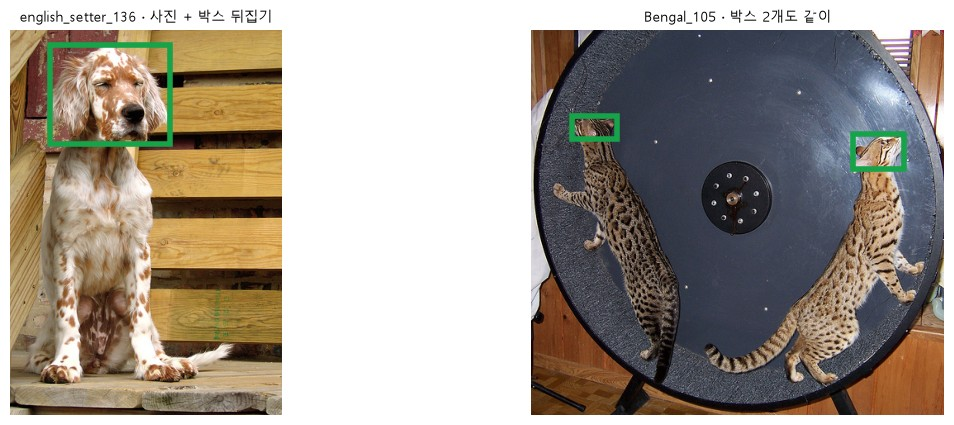

english_setter_136 원래 [[146.0, 19.0, 301.0, 148.0]] → 뒤집은 뒤 [[52.0, 19.0, 207.0, 148.0]] · 사진 폭 353


train 박스 2570 개 · 두 번 뒤집은 뒤 최대 오차: 0.0
한 번 뒤집은 박스 중 x1 < x2 · 0 ≤ x ≤ W를 어긴 사진: 0 장


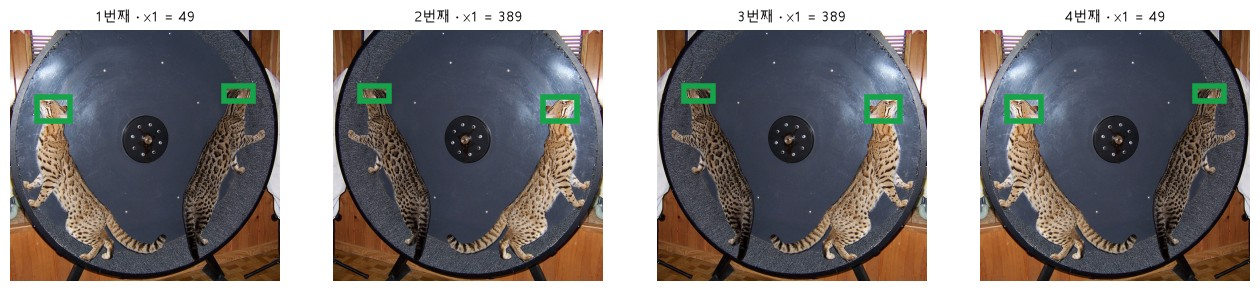

val_ds.flip = False · val 0번을 두 번 꺼내면 같음: True


16장 점검 통과
16장 중 뒤집힌 사진: 7 장
한 epoch에 뒤집힐 사진: 1299 / 2569 = 0.506


In [51]:
# 왜 · 박스 1개 · 2개 사진에서 뒤집기 결과를 확인하기 위해
image_f, target_f = hflip(image, target)                          # 0번 사진
# 박스 2개
image_b, target_b = hflip(TF.to_tensor(load_image("Bengal_105")), make_target("Bengal_105"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                   # 2칸
draw(image_f.permute(1, 2, 0), gt=target_f["boxes"], ax=axes[0],  # 박스가 따라감
     title=f"{stem} · 사진 + 박스 뒤집기")
draw(image_b.permute(1, 2, 0), gt=target_b["boxes"], ax=axes[1],  # 둘 다 따라감
     title="Bengal_105 · 박스 2개도 같이")
plt.show()                                                        # 그림 출력
# 숫자 전 → 후
print(stem, "원래", target["boxes"].tolist(), "→ 뒤집은 뒤", target_f["boxes"].tolist(),
      "· 사진 폭", image.shape[-1])

# 왜 · train 전체에서 박스를 함께 뒤집으면 정답이 맞는지 검증하기 위해
n_box, worst, bad = 0, 0.0, []  # 박스 수 · 최대 오차 · 어긴 사진
for s in train_ds.ids:                                                     # train 전체
    w = int(ET.parse(XMLS / f"{s}.xml").getroot().findtext("size/width"))  # 폭
    bx = make_target(s)["boxes"]                                           # 박스
    once = flip_boxes(bx, w)                                               # 한 번
    twice = flip_boxes(once, w)                                            # 두 번
    n_box += len(bx)                                                       # 세기
    worst = max(worst, (twice - bx).abs().max().item())                    # 원래와 차이
    ok = (once[:, 0] < once[:, 2]).all() and (once[:, 0] >= 0).all()       # 순서 · 왼쪽 범위
    if not (ok and (once[:, 2] <= w).all()):                               # 오른쪽 범위까지 어기면
        bad.append(s)                                                      # 기록
print("train 박스", n_box, "개 · 두 번 뒤집은 뒤 최대 오차:", worst)       # 0이면 식이 맞음
print("한 번 뒤집은 박스 중 x1 < x2 · 0 ≤ x ≤ W를 어긴 사진:", len(bad), "장")  # 0


# ---------- 3-3 ----------
# 왜 · 같은 사진을 여러 번 꺼낼 때 뒤집기가 확률적으로 바뀌는지 보기 위해
demo = PetFaces(train_ds.ids, flip=True)             # 보여 주기용 (학습용 난수와 따로)
i = demo.ids.index("Bengal_105")                     # 박스 2개 사진
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))    # 네 번 꺼내기
for k, ax in enumerate(axes):                        # 네 번
    im, t = demo[i]                                  # 같은 사진을 꺼냄
    draw(im.permute(1, 2, 0), gt=t["boxes"], ax=ax,  # 꺼낼 때마다 새로 정함
         title=f"{k + 1}번째 · x1 = {t['boxes'][0, 0]:.0f}")
plt.show()                                           # 그림 출력
(v1, t1), (v2, t2) = val_ds[0], val_ds[0]            # val은 두 번 꺼내도
print("val_ds.flip =", val_ds.flip, "· val 0번을 두 번 꺼내면 같음:",  # 늘 같음
      torch.equal(v1, v2) and torch.equal(t1["boxes"], t2["boxes"]))

# 왜 · 뒤집기를 켠 DataLoader에서도 형식 점검이 통과하는지 확인하기 위해
aug_loader = DataLoader(demo, batch_size=16, shuffle=True, num_workers=0,   # 2-4와 같은 16장
                        generator=torch.Generator().manual_seed(0), collate_fn=collate_fn)
images_aug, targets_aug = next(iter(aug_loader))                            # 뒤집기 켠 첫 batch
check_batch(images_aug, targets_aug)                                        # 2-4 점검 그대로
flipped_mask = [not torch.equal(a, b) for a, b in zip(images_aug, images)]  # 뒤집혔나
print("16장 중 뒤집힌 사진:", sum(flipped_mask), "장")                      # 약 절반

# 왜 · 한 epoch에 뒤집히는 사진 수를 세어 확률 0.5가 맞는지 보기 위해
train_ds_flip = PetFaces(train_ds.ids, flip=True)  # RUN_B와 같은 설정: seed 1 · p = 0.5
gen = torch.Generator().manual_seed(1)             # 같은 seed의 난수
n_flip = sum(bool(torch.rand(1, generator=gen) < 0.5) for _ in train_ds_flip.ids)  # 한 epoch 동안
print(f"한 epoch에 뒤집힐 사진: {n_flip} / {len(train_ds_flip)}"  # 약 절반
      f" = {n_flip / len(train_ds_flip):.3f}")

**실행 흐름**

1. 3-4 상하 뒤집기 · 회전

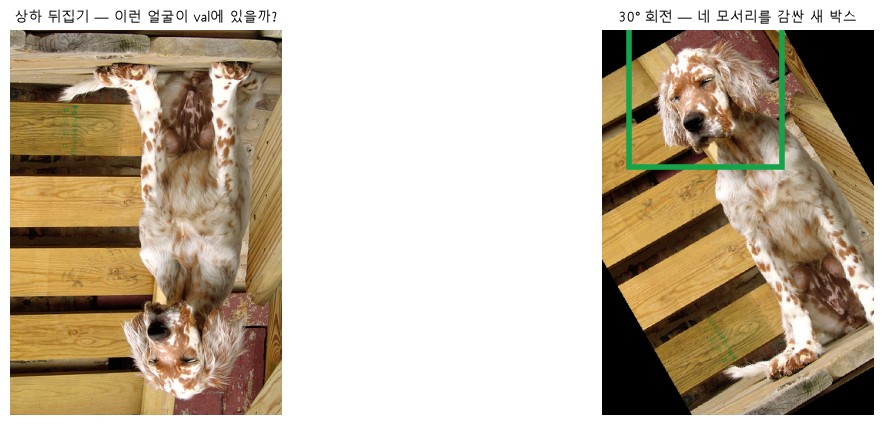

회전 뒤 새 박스 넓이 = 원래의 1.88배


In [52]:
# ---------- 3-4 ----------
# 왜 · 상하 뒤집기 · 회전이 이 데이터에 맞지 않는 이유를 그림으로 보기 위해
img = TF.to_tensor(load_image(stem))                           # 0번 사진
t = make_target(stem)                                          # 정답
W, H = img.shape[2], img.shape[1]                              # 폭 · 높이
rot = TF.rotate(img, 30)                                       # 가운데를 축으로 30° (반시계)
x1, y1, x2, y2 = t["boxes"][0].tolist()                        # 원래 박스
a, cx, cy = math.radians(30), W / 2, H / 2                     # 각도 · 중심
pts = [(cx + (x - cx) * math.cos(a) + (y - cy) * math.sin(a),  # 네 모서리를 돌림
        cy - (x - cx) * math.sin(a) + (y - cy) * math.cos(a)) for x in (x1, x2) for y in (y1, y2)]
xs_, ys_ = [p[0] for p in pts], [p[1] for p in pts]            # 돌린 모서리
new = [min(xs_), min(ys_), max(xs_), max(ys_)]                 # 네 모서리를 감싼 박스

fig, axes = plt.subplots(1, 2, figsize=(14, 5))                               # 2칸
# 거꾸로
draw(TF.vflip(img).permute(1, 2, 0), ax=axes[0], title="상하 뒤집기 — 이런 얼굴이 val에 있을까?")
# 넓어짐
draw(rot.permute(1, 2, 0), gt=[new], ax=axes[1], title="30° 회전 — 네 모서리를 감싼 새 박스")
plt.show()                                                                    # 그림 출력
area_ratio = (new[2] - new[0]) * (new[3] - new[1]) / ((x2 - x1) * (y2 - y1))  # 넓이 배수
print(f"회전 뒤 새 박스 넓이 = 원래의 {area_ratio:.2f}배")                    # 배경까지 들어감

**실행 흐름**

1. 4-1 미션 예시 코드의 함정
2. 4-2 분류 헤드 새로 끼우기

In [53]:
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16  # COCO SSD
from torchvision.models.detection.ssd import SSDClassificationHead           # 분류 헤드 틀


# ---------- 4-1 ----------

# 왜 · 미션 예시 코드의 함정을 실제 모델로 확인하기 위해
SSD_W = SSD300_VGG16_Weights.COCO_V1                                      # COCO 가중치
COCO_NAMES = SSD_W.meta["categories"]                                     # 91칸 이름
stem = "Abyssinian_140"                                                   # 어제 본 사진 · train 쪽
x = TF.to_tensor(load_image(stem))                                        # 텐서
gt_boxes, gt_names = read_voc(XMLS / f"{stem}.xml")                       # 정답
model = ssd300_vgg16(weights=SSD_W).eval()                                # COCO 모델
print("분류 헤드 첫 층:", model.head.classification_head.module_list[0])  # 512 → 364
print("클래스 점수 모양:", head_shapes(model, x)[0])                      # (1, 8732, 91)

# 왜 · num_classes 숫자만 바꾸면 층이 그대로라는 것을 확인하기 위해
head = model.head.classification_head                     # 분류 헤드
print("원래 num_classes라는 이름이 있었나?", hasattr(head, "num_classes"))  # False
num_classes = 3                                           # 미션 예시 코드 그대로 (background 포함)
model.head.classification_head.num_classes = num_classes  # 이름표만 붙음
print("적어 둔 숫자     :", head.num_classes)             # 3
print("계산에 쓰는 칸 수:", head.num_columns)             # 91
print("클래스 점수 모양 :", head_shapes(model, x)[0])     # 여전히 91칸

model.train()                                                                     # 학습 모드
loss = model([x], [make_target(stem)])                                            # 손실 계산
model.eval()                                                                      # 되돌리기
print({k: round(v.item(), 3) for k, v in loss.items()})                           # 에러 없음
print("91칸 모델에서 1번 칸의 이름:", COCO_NAMES[1], "· 2번 칸:", COCO_NAMES[2])  # person · bicycle


# ---------- 4-2 ----------

# 왜 · 배경 + 고양이 얼굴 + 개 얼굴 = 3칸을 한곳에서 정하기 위해
NUM_CLASSES = 3  # 0 배경 · 1 고양이 얼굴 · 2 개 얼굴


# 왜 · COCO 몸통은 살리고 분류 헤드만 새로 끼운 모델을 만들기 위해
def make_mission_ssd(num_classes=NUM_CLASSES):                    # COCO SSD + 새 분류 헤드
    m = ssd300_vgg16(weights=SSD_W)                               # COCO 몸통 · 위치 헤드
    old = m.head.classification_head                              # 바꿀 자리
    in_channels = [conv.in_channels for conv in old.module_list]  # 맵마다 채널
    num_anchors = m.anchor_generator.num_anchors_per_location()   # 칸마다 박스 수
    # 새 층
    m.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes)
    return m                                                      # 분류 헤드만 새것


torch.manual_seed(0)                                               # 새 층 시작값 고정
model = make_mission_ssd().eval()                                  # 깨끗한 모델 (이름표 모델 버림)
for conv in model.head.classification_head.module_list:            # 맵마다
    print(f"Conv2d({conv.in_channels:>4} → {conv.out_channels})")  # 박스 수 × 3
cls_shape, box_shape = head_shapes(model, x)                       # 모양
print("클래스 점수 모양:", cls_shape, "· 위치 보정 모양:", box_shape)  # (1, 8732, 3)


# 왜 · 어느 부분이 COCO 값 그대로인지 텐서 비교로 확인하기 위해
def same(a, b):  # 두 부분의 값이 모두 같은가
    # 모든 텐서가 같은가
    return all(torch.equal(a.state_dict()[k], b.state_dict()[k]) for k in a.state_dict())


# 왜 · 부분별 파라미터 수를 세어 무엇이 새것인지 보기 위해
def count(m):                                      # 파라미터 수
    return sum(p.numel() for p in m.parameters())  # 원소 수 합

분류 헤드 첫 층: Conv2d(512, 364, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
클래스 점수 모양: (1, 8732, 91)
원래 num_classes라는 이름이 있었나? False
적어 둔 숫자     : 3
계산에 쓰는 칸 수: 91


클래스 점수 모양 : (1, 8732, 91)
{'bbox_regression': 1.386, 'classification': 11.146}
91칸 모델에서 1번 칸의 이름: person · 2번 칸: bicycle


Conv2d( 512 → 12)
Conv2d(1024 → 18)
Conv2d( 512 → 18)
Conv2d( 256 → 18)
Conv2d( 256 → 12)
Conv2d( 256 → 12)
클래스 점수 모양: (1, 8732, 3) · 위치 보정 모양: (1, 8732, 4)


**실행 흐름**

1. 4-2 COCO 모델과 부분별 대조
2. 4-3 학습 전 새 헤드로 예측

몸통(VGG)   COCO와 같음: True · 파라미터 22,943,936
위치 헤드    COCO와 같음: True · 파라미터 534,648
분류 헤드    새로 만듦 · 파라미터 400,986 (COCO 91칸 헤드는 12,163,242)
몸통 중 학습 대상: 22,905,216 / 22,943,936 (나머지 = 맨 앞 층, 고정)
박스 수: 200 · 이번 예측에 나온 라벨: [1, 2]
구조상 나올 수 있는 라벨: [1, 2] (0 = 배경은 출력하지 않음)
점수 상위 3개: [0.992, 0.991, 0.99]


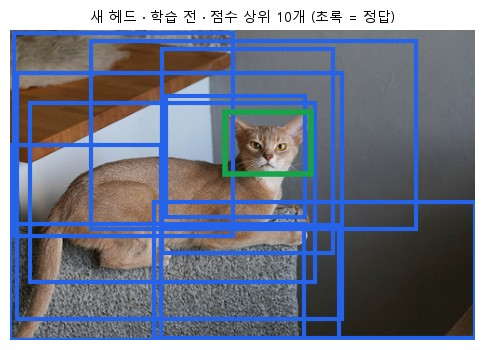

In [54]:
# 왜 · 새 모델과 COCO 모델을 부분별로 대조하기 위해
coco = ssd300_vgg16(weights=SSD_W)  # 비교용 COCO 모델
print("몸통(VGG)   COCO와 같음:", same(model.backbone, coco.backbone),                # True
      f"· 파라미터 {count(model.backbone):,}")
# True
print("위치 헤드    COCO와 같음:", same(model.head.regression_head, coco.head.regression_head),
      f"· 파라미터 {count(model.head.regression_head):,}")
print(f"분류 헤드    새로 만듦 · 파라미터 {count(model.head.classification_head):,}"  # 작아짐
      f" (COCO 91칸 헤드는 {count(coco.head.classification_head):,})")
trainable = sum(p.numel() for p in model.backbone.parameters() if p.requires_grad)    # 학습 대상
# 일부 고정
print(f"몸통 중 학습 대상: {trainable:,} / {count(model.backbone):,} (나머지 = 맨 앞 층, 고정)")


# ---------- 4-3 ----------
with torch.no_grad():                                                        # 예측만
    # 왜 · 학습 전 새 헤드도 라벨 1 · 2만 낸다는 것과 점수가 아직 엉터리라는 것을 확인하기 위해
    pred = model([x])[0]                                                     # 새 헤드 · 학습 전
print("박스 수:", len(pred["boxes"]), "· 이번 예측에 나온 라벨:",            # 1 · 2
      sorted(pred["labels"].unique().tolist()))
# 1 · 2
print("구조상 나올 수 있는 라벨:", list(range(1, NUM_CLASSES)), "(0 = 배경은 출력하지 않음)")
print("점수 상위 3개:", [round(s, 3) for s in pred["scores"][:3].tolist()])  # 높아도 학습 전
draw(load_image(stem), gt=gt_boxes, pred=pred["boxes"][:10],                 # 상위 10개
     title="새 헤드 · 학습 전 · 점수 상위 10개 (초록 = 정답)")
plt.show()                                                                   # 그림 출력

**실행 흐름**

1. 5-1 모양 확인
2. 5-2 15 step 스모크 학습

멈춤 → 클래스 점수 91칸 — 3칸이어야 함


새 헤드 모델 → (1, 8732, 3) 통과


step  1 · 위치 2.30 · 분류 15.23


step  5 · 위치 1.78 · 분류 5.87


step 10 · 위치 1.83 · 분류 5.38


step 15 · 위치 1.71 · 분류 4.58


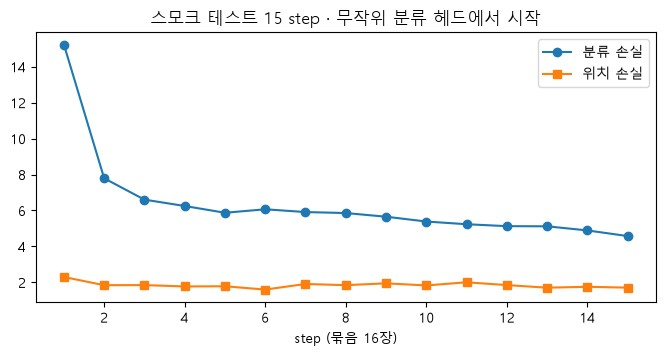

In [55]:
# ---------- 5-1 ----------
# 왜 · 헤드 교체 실수를 학습 전에 한 줄로 잡기 위해
def check_head(m, x, num_classes=NUM_CLASSES):  # 학습 전 한 줄 확인
    cls_shape, _ = head_shapes(m, x)            # 모양
    # 멈춤
    assert cls_shape[-1] == num_classes, f"클래스 점수 {cls_shape[-1]}칸 — {num_classes}칸이어야 함"
    return cls_shape                            # 통과하면 모양


images, targets = next(iter(train_loader))       # train 첫 묶음 16장
x0 = images[0]                                   # 한 장
tagged = ssd300_vgg16(weights=SSD_W).eval()      # 4-1 미션 예시 코드 그대로
tagged.head.classification_head.num_classes = 3  # 이름표만
try:
    check_head(tagged, x0)                       # 91칸
except AssertionError as e:                      # 멈춤
    print("멈춤 →", e)                           # 조용한 버그를 잡음

torch.manual_seed(0)                                                            # 시작값 고정
smoke_model = make_mission_ssd().to(DEVICE)                                     # 스모크용 새 모델
print("새 헤드 모델 →", check_head(smoke_model.eval(), x0.to(DEVICE)), "통과")  # 3칸
del tagged                                                                      # 이름표 모델은 버림


# ---------- 5-2 ----------
# 왜 · 학습 한 step을 함수로 묶어 스모크 · 본 학습에 같이 쓰기 위해
def train_step(model, images, targets, optimizer):                        # 묶음 하나로 한 번 학습
    images = [x.to(DEVICE) for x in images]                               # 사진 → 장치
    targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]  # 정답 → 장치
    loss_dict = model(images, targets)                                    # 학습 모드: 손실 두 가지
    loss = sum(loss_dict.values())                                        # 위치 + 분류
    optimizer.zero_grad()                                                 # 지난 기울기 지우기
    loss.backward()                                                       # 기울기
    optimizer.step()                                                      # 가중치 갱신
    return {k: v.item() for k, v in loss_dict.items()}                    # 숫자로


# 왜 · 긴 학습 전에 15 step으로 손실이 내려가는지 먼저 확인하기 위해
SMOKE_STEPS = 15                                                        # 15 step만
# 설정
smoke_opt = torch.optim.SGD(smoke_model.parameters(), lr=0.001, momentum=0.9, weight_decay=5e-4)
smoke_model.train()                                                     # 학습 모드
smoke_log, t0 = [], time.perf_counter()                                 # 기록 · 시작 시각
for step, (images, targets) in enumerate(train_loader, 1):              # 묶음마다
    losses = train_step(smoke_model, images, targets, smoke_opt)        # 한 step
    assert all(math.isfinite(v) for v in losses.values()), f"step {step}: {losses}"  # nan이면 멈춤
    smoke_log.append(losses)                                            # 기록
    if step in (1, 5, 10, 15):                                          # 네 번 출력
        print(f"step {step:2d} · 위치 {losses['bbox_regression']:.2f}"  # 위치 · 분류 손실
              f" · 분류 {losses['classification']:.2f}")
    if step == SMOKE_STEPS:                                             # 15 step이면
        break                                                           # 멈춤
smoke_seconds = time.perf_counter() - t0                                # 걸린 시간 (6-1에서 씀)

# 왜 · 스모크 학습 손실 곡선을 눈으로 확인하기 위해
fig, ax = plt.subplots(figsize=(8, 3.5))                                        # 손실 그림
ax.plot(range(1, 16), [r["classification"] for r in smoke_log], "o-", label="분류 손실")  # 분류
ax.plot(range(1, 16), [r["bbox_regression"] for r in smoke_log], "s-", label="위치 손실")  # 위치
ax.set_xlabel("step (묶음 16장)")                                               # x축
ax.set_title("스모크 테스트 15 step · 무작위 분류 헤드에서 시작", fontsize=12)  # 제목
ax.legend()                                                                     # 범례
plt.show()                                                                      # 그림 출력

**실행 흐름**

1. 5-3 잘못 뒤집은 박스 잡기
2. 5-4 모드마다 돌려주는 것

In [56]:
# ---------- 5-3 ----------
stem = "Abyssinian_140"                                          # 4장에서 본 train 사진
x, t = TF.to_tensor(load_image(stem)), make_target(stem)         # 사진 · 정답
W = x.shape[-1]                                                  # 사진 폭
# 왜 · 잘못 뒤집은 박스(x1 > x2)를 모델이 첫 step에서 잡아내는지 확인하기 위해
bad = t["boxes"].clone()                                         # 복사
bad[:, [0, 2]] = W - t["boxes"][:, [0, 2]]                       # 잘못된 식: 양 끝을 따로 뒤집음
print("원래 박스        :", [round(v) for v in t["boxes"][0].tolist()])  # 원래
print("잘못 뒤집은 박스 :", [round(v) for v in bad[0].tolist()], "→ x1 > x2")  # 순서 뒤집힘
smoke_model.train()                                              # 학습 모드
try:
    with torch.no_grad():                                        # 손실만 확인
        # 계산
        smoke_model([x.to(DEVICE)], [{"boxes": bad.to(DEVICE), "labels": t["labels"].to(DEVICE)}])
except AssertionError as e:                                      # 멈춤
    print("학습 첫 step에서 멈춤 →", str(e).split(" Found")[0])  # 원인


# ---------- 5-4 ----------
# 왜 · train · eval 모드에서 돌려주는 것이 다르다는 것을 확인하기 위해
xs = [x.to(DEVICE) for x in images[:2]]                                 # 방금 묶음에서 2장
ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets[:2]]     # 정답 2개
with torch.no_grad():                                                   # 비교만
    smoke_model.train()                                                 # 학습 모드
    out_train = smoke_model(xs, ts)                                     # 손실 dict
    smoke_model.eval()                                                  # 평가 모드
    out_eval = smoke_model(xs)                                          # 예측 list
print("학습 모드 →", type(out_train).__name__, list(out_train.keys()))  # dict
# list
print("평가 모드 →", type(out_eval).__name__, len(out_eval), "개 ·", list(out_eval[0].keys()))

with torch.no_grad():                    # 평가 뒤 train()을 깜빡한 상태
    out = smoke_model(xs, ts)            # 정답을 줘도 예측
print("평가 모드 + 정답 →", type(out).__name__, "(손실이 아니라 예측)")  # list
try:
    sum(out.values())                    # train_step 안의 그 줄
except AttributeError as e:              # 멈춤
    print("학습 루프에서 멈춤 →", e)     # 원인
smoke_model.train()                      # 학습 모드
try:
    smoke_model(xs)                      # 정답 없이
except AssertionError as e:              # 멈춤
    print("학습 모드 + 정답 없음 →", e)  # 원인

원래 박스        : [231, 87, 323, 154]
잘못 뒤집은 박스 : [269, 87, 177, 154] → x1 > x2
학습 첫 step에서 멈춤 → All bounding boxes should have positive height and width.


학습 모드 → dict ['bbox_regression', 'classification']
평가 모드 → list 2 개 · ['boxes', 'scores', 'labels']


평가 모드 + 정답 → list (손실이 아니라 예측)
학습 루프에서 멈춤 → 'list' object has no attribute 'values'
학습 모드 + 정답 없음 → targets should not be none when in training mode


**실행 흐름**

1. 6-1 시간 어림 · lr 스케줄
2. 6-2 학습 루프 · 예측 함수

In [57]:
# ---------- 6-1 ----------
# 왜 · 스모크 시간으로 본 학습 시간을 미리 어림하기 위해
sec_per_step = smoke_seconds / SMOKE_STEPS                                # 스모크 한 step 시간
steps_per_epoch = len(train_loader)                                       # 2569 ÷ 16 → 올림
guess = sec_per_step * steps_per_epoch                                    # 1 epoch 어림
print(f"train {len(train_ds):,}장 · 묶음 16장 → 1 epoch = {steps_per_epoch} step")  # 161
print(f"스모크로 어림한 1 epoch ≈ {guess / 60:.1f}분 (컴퓨터마다 다름)")  # 장치마다 다름

# 왜 · 원본 규칙대로 전체의 2/3 지점에서 lr을 낮추기 위해
EPOCHS = 4  # 원본 10 → 이 노트북은 두 번 학습 · 두 번 검증 실행을 위해 4로 줄임
STEP_SIZE = round(2 * EPOCHS / 3)  # 원본 규칙: 전체의 2/3 지점에서 lr 1/10
print(f"N = {EPOCHS} (원본 10) · step_size = round(2 × {EPOCHS} ÷ 3) = {STEP_SIZE}")  # 계획


# 왜 · 모델 없이 lr만 기록해 scheduler 실수를 빨리 확인하기 위해
def lr_log(call_step, n_epochs=EPOCHS, steps=steps_per_epoch):  # 학습 없이 lr만 기록
    w = torch.nn.Parameter(torch.zeros(1))                      # 가짜 파라미터
    opt = torch.optim.SGD([w], lr=0.001, momentum=0.9)          # 같은 lr
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP_SIZE, gamma=0.1)  # 같은 스케줄
    log = []                                                    # epoch마다 lr
    for _ in range(n_epochs):                                   # epoch마다
        log.append(opt.param_groups[0]["lr"])                   # 이번 epoch lr
        for _ in range(steps):                                  # 묶음마다
            opt.step()                                          # 빈 갱신
            if call_step == "batch":                            # 잘못된 자리
                sch.step()                                      # 묶음마다
        if call_step == "epoch":                                # 올바른 자리
            sch.step()                                          # epoch 끝마다
    return log                                                  # lr 목록


# 왜 · step() 위치에 따라 lr이 어떻게 바뀌는지 비교하기 위해
lr_runs = {"step() 없음 (미션 코드)": lr_log(None),                  # 세 가지 비교
           "epoch 끝마다 step()": lr_log("epoch"),
           "묶음마다 step()": lr_log("batch")}
for name, log in lr_runs.items():                                    # 줄마다
    print(f"{name:16s} lr " + "  ".join(f"{v:>6.0e}" for v in log))  # epoch별 lr

# 왜 · 학습 한 step 뒤 가중치가 실제로 바뀌는지 확인하기 위해
w = smoke_model.head.classification_head.module_list[0].weight  # 분류 헤드 첫 층
smoke_model.train()                                             # 학습 모드
for lr in (0.001, 1e-26):                                       # 두 lr
    before = w.detach().clone()                                 # 갱신 전
    # 1 step
    train_step(smoke_model, images, targets, torch.optim.SGD(smoke_model.parameters(), lr=lr))
    moved = (w.detach() - before).abs().max().item()            # 가장 크게 움직인 값
    print(f"lr {lr:.0e} → 분류 헤드 첫 층 가중치가 움직인 최대 크기 {moved:.1e}")  # 0이면 멈춤


# ---------- 6-2 ----------
# 왜 · 평가 뒤에도 epoch마다 학습 모드로 돌아가 손실을 모으기 위해
def train_one_epoch(model, loader, optimizer, max_steps=None, history=None):  # 한 바퀴
    model.train()  # 평가 뒤에도 epoch마다 학습 모드로
    sums, seen_n = {"bbox_regression": 0.0, "classification": 0.0}, 0         # 손실 합 · 사진 수
    for step, (images, targets) in enumerate(loader, 1):                      # 묶음마다
        losses = train_step(model, images, targets, optimizer)                # 한 step
        assert all(math.isfinite(v) for v in losses.values()), f"step {step}: {losses}"  # nan?
        for k in sums:                                                        # 두 손실
            sums[k] += losses[k] * len(images)                                # 사진 수만큼 가중
        seen_n += len(images)                                                 # 사진 수
        if history is not None:                                               # 기록할 곳이 있으면
            history.append(losses)                                            # step 기록
        if max_steps and step >= max_steps:                                   # 일부만
            break                                                             # 멈춤
    return {k: v / seen_n for k, v in sums.items()}                           # 평균 손실

train 2,569장 · 묶음 16장 → 1 epoch = 161 step
스모크로 어림한 1 epoch ≈ 2.7분 (컴퓨터마다 다름)
N = 4 (원본 10) · step_size = round(2 × 4 ÷ 3) = 3
step() 없음 (미션 코드) lr  1e-03   1e-03   1e-03   1e-03
epoch 끝마다 step() lr  1e-03   1e-03   1e-03   1e-04
묶음마다 step()      lr  1e-03   1e-56  1e-110  1e-164


lr 1e-03 → 분류 헤드 첫 층 가중치가 움직인 최대 크기 1.5e-04


lr 1e-26 → 분류 헤드 첫 층 가중치가 움직인 최대 크기 0.0e+00


**실행 흐름**

1. 6-2 예측 함수 predict_all
2. 6-3 IoU · 짝짓기 judge

In [58]:
# 왜 · AP 계산에 필요한 예측을 낮은 신뢰도까지 한 번에 모으기 위해
def predict_all(model, ids, label_map=None, batch=16):  # 사진 목록 → 사진마다 정답 · 예측 기록
    model.eval()                                                                   # 평가 모드
    records = []                                                                   # 결과
    for k in range(0, len(ids), batch):                                            # 16장씩
        stems = ids[k:k + batch]                                                   # 이번 묶음
        with torch.no_grad():                                                      # 예측만
            outs = model([TF.to_tensor(load_image(s)).to(DEVICE) for s in stems])  # 예측
        for s, o in zip(stems, outs):                                              # 사진마다
            t = make_target(s)                                                     # 정답
            labs = o["labels"].tolist()                                            # 예측 라벨
            # 남길 줄
            keep = [i for i, lb in enumerate(labs) if label_map is None or lb in label_map]
            ours = [label_map[labs[i]] if label_map else labs[i] for i in keep]    # 우리 번호
            records.append({"id": s, "gt_boxes": t["boxes"].tolist(),              # 정답
                            "gt_labels": t["labels"].tolist(), "labels": ours,
                            "boxes": o["boxes"][keep].cpu().tolist(),
                            "scores": o["scores"][keep].cpu().tolist()})
    return records                                                                 # 사진 수만큼


# 왜 · 예측 기록 형식을 사진 두 장으로 먼저 확인하기 위해
pick = [sorted(val_ds.ids)[0], sorted(val_ds.ids)[-1]]  # val 고양이 1장 · 개 1장
rec = predict_all(smoke_model, pick)                    # 스모크 모델로 시험
print("기록 열쇠:", list(rec[0].keys()))                # 사진 하나의 기록
for r in rec:                                           # 사진마다
    print(f"{r['id']:22s} 정답 {len(r['gt_boxes'])}개 · 예측 {len(r['boxes'])}개")  # 예측은 많음


# ---------- 6-3 ----------
# 왜 · IoU를 직접 계산해 채점 함수가 라이브러리 없이 돌게 하기 위해
def iou(a, b):                                       # 박스 두 개 → IoU (Day01 4장)
    w = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))  # 겹친 가로
    h = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))  # 겹친 세로
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - w * h  # 합친 넓이
    return w * h / union if union > 0 else 0.0       # 0 ~ 1


# 왜 · 정답 하나에 예측 하나만 짝지어 TP · FP를 판정하기 위해
def judge(records, cls, iou_thr, score_min=0.01):  # 한 클래스 · 점수 순 짝짓기 (Day01 9장 규칙)
    gts = {r["id"]: [b for b, lb in zip(r["gt_boxes"], r["gt_labels"]) if lb == cls]  # 정답
           for r in records}
    used = {k: set() for k in gts}                 # 짝 생긴 정답
    preds = [(s, r["id"], b) for r in records      # 이 클래스 · 하한 이상
             for b, lb, s in zip(r["boxes"], r["labels"], r["scores"])
             if lb == cls and s >= score_min]
    preds.sort(key=lambda p: -p[0])                # 점수 높은 순
    rows = []                                      # (점수, TP인가, IoU, 사진, 박스)
    for s, stem, b in preds:                       # 예측마다
        # 빈 정답 중
        best, j = max([(iou(b, g), j) for j, g in enumerate(gts[stem]) if j not in used[stem]],
                      default=(0.0, None))
        ok = j is not None and best >= iou_thr     # 기준 이상이면 TP
        if ok:                                     # TP면
            used[stem].add(j)                      # 그 정답은 다시 못 씀
        rows.append((s, ok, best, stem, b))        # 기록
    return rows, sum(map(len, gts.values()))       # 판정 · 정답 수

기록 열쇠: ['id', 'gt_boxes', 'gt_labels', 'labels', 'boxes', 'scores']
Abyssinian_101         정답 1개 · 예측 200개
yorkshire_terrier_190  정답 1개 · 예측 200개


**실행 흐름**

1. 6-3 클래스별 AP
2. 6-4 학습 · 평가 · 저장 train_run

In [59]:
# 왜 · 클래스별 AP를 구해 val 점수로 쓰기 위해
def ap_per_class(records, iou_thr=0.5):                # 클래스별 AP (all-point) · mAP
    out = {}                                           # 결과
    for cls in (1, 2):                                 # 두 클래스
        rows, n_gt = judge(records, cls, iou_thr)      # 판정
        tp = np.cumsum([ok for _, ok, *_ in rows])     # 누적 TP
        r = np.concatenate([[0.0], tp / n_gt, [1.0]])  # 재현율
        p = np.concatenate([[0.0], tp / np.arange(1, len(rows) + 1), [0.0]])  # 정밀도
        p = np.maximum.accumulate(p[::-1])[::-1]       # 포락선
        # 넓이
        out[cls] = {"AP": float(np.sum((r[1:] - r[:-1]) * p[1:])), "GT": n_gt, "예측": len(rows)}
    out["mAP"] = (out[1]["AP"] + out[2]["AP"]) / 2     # 평균
    return out                                         # 클래스별 + mAP


# 왜 · 채점 함수가 맞는지 정답을 그대로 낸 경우로 검증하기 위해
print("50 밀린 박스 IoU:", round(iou([0, 0, 100, 100], [50, 0, 150, 100]), 4))  # Day01 4-1
perfect = [{**r, "boxes": r["gt_boxes"], "labels": r["gt_labels"],              # 정답을 그대로 예측
            "scores": [1.0] * len(r["gt_boxes"])} for r in rec]
print("정답 그대로 → mAP50:", ap_per_class(perfect)["mAP"])                     # 1.0
print("스모크 모델 → mAP50:", round(ap_per_class(rec)["mAP"], 4))               # 15 step 학습


# ---------- 6-4 ----------
# 왜 · 학습 · 평가 · 저장을 한 함수로 묶어 RUN마다 같은 절차를 쓰기 위해
def train_run(folder, flip):                                   # 학습 한 번 → 폴더에 저장
    folder.mkdir(exist_ok=True)                                # 폴더
    torch.manual_seed(0)  # 새 헤드 시작값 고정 → 두 학습의 출발점 같음
    model = make_mission_ssd().to(DEVICE)                      # COCO 몸통 + 3칸 헤드
    # 원본 설정
    opt = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9, weight_decay=5e-4)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP_SIZE, gamma=0.1)  # 2/3 지점에서 1/10
    gen = torch.Generator().manual_seed(0)                     # 섞는 순서 고정
    loader = DataLoader(PetFaces(train_ds.ids, flip=flip), batch_size=16, shuffle=True,  # 학습 묶음
                        num_workers=0, generator=gen, collate_fn=collate_fn)
    history, steps, best = [], [], -1.0                        # epoch 기록 · step 기록 · 최고 점수
    for epoch in range(1, EPOCHS + 1):                         # 1 ~ EPOCHS
        lr_used = opt.param_groups[0]["lr"]                    # 이번 epoch lr
        loss = train_one_epoch(model, loader, opt, history=steps)  # 학습
        sch.step()                                             # epoch 끝마다 한 번
        preds = predict_all(model, sorted(val_ds.ids))         # val 예측
        (folder / f"val_epoch{epoch}_predictions.json").write_text(json.dumps(preds))  # 10-2에서 씀
        m50 = ap_per_class(preds, 0.5)["mAP"]                  # val mAP50
        history.append({"epoch": epoch, "lr_used": lr_used, **loss, "mAP50": m50})  # 기록
        ck = {"model": model.state_dict(), "optimizer": opt.state_dict(),  # 이어 학습에 필요한 것
              "scheduler": sch.state_dict(), "epoch": epoch,
              "lr": opt.param_groups[0]["lr"], "loss": loss}
        torch.save(ck, folder / "last.pt")                     # last
        if m50 > best:                                         # best = val mAP50 최고
            best = m50                                         # 갱신
            torch.save(ck, folder / "best.pt")                 # best
    (folder / "history.json").write_text(json.dumps(history))  # 기록 저장
    (folder / "steps.json").write_text(json.dumps(steps))      # step 저장

50 밀린 박스 IoU: 0.3333
정답 그대로 → mAP50: 1.0
스모크 모델 → mAP50: 0.1705


**실행 흐름**

1. 6-4 fit (있으면 불러오기)
2. 6-5 같은 설정 20 step · 기록 읽기
3. 6-6 checkpoint 열기

In [60]:
# 왜 · 결과 파일이 있으면 다시 학습하지 않고 불러오기 위해
def fit(name, flip):  # 기록이 없으면 학습 · 있으면 불러옴 → (history, steps)
    folder = RUNS / name                                              # 결과 폴더
    if not (folder / "history.json").exists():  # 처음이면 (원본: 미리 학습해 둔 기록)
        train_run(folder, flip)                                       # 학습 · 저장
    history = json.loads((folder / "history.json").read_text())       # epoch 기록
    steps = json.loads((folder / "steps.json").read_text())           # step 기록
    for h in history:                                                 # 학습했든 불러왔든 같은 줄
        print(f"[{name}] epoch {h['epoch']} · lr {h['lr_used']:.0e}"  # 기록
              f" · 분류 {h['classification']:.3f} · val mAP50 {h['mAP50']:.4f}")
    return history, steps                                             # 결과


# 왜 · 뒤집기 없는 기준 학습을 먼저 얻기 위해
hist_A, steps_A = fit("RUN_A", flip=False)  # 뒤집기 없음 (GPU에서 약 30 ~ 40분 · 컴퓨터마다 다름)


# ---------- 6-5 ----------
torch.manual_seed(0)                                                 # RUN_A와 같은 시작
live_model = make_mission_ssd().to(DEVICE)                           # COCO 몸통 + 새 3칸 헤드
# 같은 설정
live_opt = torch.optim.SGD(live_model.parameters(), lr=0.001, momentum=0.9, weight_decay=5e-4)
replay_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0,  # 같은 섞기
                           collate_fn=collate_fn, generator=torch.Generator().manual_seed(0))
live_log = []                                                        # step 기록
train_one_epoch(live_model, replay_loader, live_opt, max_steps=20, history=live_log)  # 20 step만
print("step | 지금 분류 · 위치    | RUN_A 분류 · 위치")              # 표 머리
for i in (0, 4, 9, 14, 19):                                          # 다섯 줄
    a, mine = steps_A[i], live_log[i]                                # 같은 step
    print(f"{i + 1:4d} | {mine['classification']:6.3f} · {mine['bbox_regression']:.3f}"  # 지금
          f"      | {a['classification']:6.3f} · {a['bbox_regression']:.3f}")  # RUN_A
gap = max(abs(mine[k] - a[k]) for a, mine in zip(steps_A, live_log)  # 가장 큰 차이
          for k in ("classification", "bbox_regression"))
print(f"20 step 중 가장 큰 차이: {gap:.1e}")                         # 0이면 재현
del live_model, live_opt                                             # 메모리 비우기

# 왜 · epoch마다 손실 · lr · val 점수를 한 표로 확인하기 위해
print("epoch | 위치 손실 | 분류 손실 | 쓴 lr  | val mAP50")                 # 표 머리
for h in hist_A:                                                            # epoch마다
    print(f"{h['epoch']:5d} | {h['bbox_regression']:9.3f} | {h['classification']:9.3f}"  # 한 줄
          f" | {h['lr_used']:.0e} | {h['mAP50']:.4f}")
best_A = max(hist_A, key=lambda h: h["mAP50"])                              # val로 고른 best
# best · last
print(f"best = epoch {best_A['epoch']} (val mAP50 {best_A['mAP50']:.4f}) · last = epoch"
      f" {hist_A[-1]['epoch']} (val mAP50 {hist_A[-1]['mAP50']:.4f}) · test 사용: False")
same_lr = [h["lr_used"] for h in hist_A] == lr_runs["epoch 끝마다 step()"]  # 기록과 비교
print("RUN_A가 쓴 lr이 'epoch 끝마다'와 같은가:", same_lr)                  # True


# ---------- 6-6 ----------
# 왜 · 저장 파일 안에 무엇이 들어 있는지 열어 보기 위해
best_path = RUNS / "RUN_A" / "best.pt"                                # best 파일
ckpt = torch.load(best_path, map_location="cpu", weights_only=False)  # 내가 만든 파일만 이렇게 엶
print("들어 있는 것:", list(ckpt.keys()))                             # 열쇠
print(f"epoch {ckpt['epoch']} · 저장된 lr {ckpt['lr']} · 손실",       # 저장 직후 상태
      {k: round(v, 3) for k, v in ckpt["loss"].items()})
# 스케줄
print("scheduler:", {k: ckpt["scheduler"][k] for k in ("step_size", "gamma", "last_epoch")})
# 크기
print(f"model 텐서 {len(ckpt['model'])}개 · optimizer 상태 {len(ckpt['optimizer']['state'])}개"
      f" · 파일 {best_path.stat().st_size / 1e6:.0f} MB")

[RUN_A] epoch 1 · lr 1e-03 · 분류 2.829 · val mAP50 0.9726
[RUN_A] epoch 2 · lr 1e-03 · 분류 1.301 · val mAP50 0.9658
[RUN_A] epoch 3 · lr 1e-03 · 분류 0.959 · val mAP50 0.9789
[RUN_A] epoch 4 · lr 1e-04 · 분류 0.670 · val mAP50 0.9877


step | 지금 분류 · 위치    | RUN_A 분류 · 위치
   1 | 15.828 · 2.156      | 15.828 · 2.156
   5 |  5.963 · 1.939      |  5.963 · 1.939
  10 |  5.412 · 1.781      |  5.412 · 1.781
  15 |  4.673 · 1.833      |  4.673 · 1.833
  20 |  4.206 · 1.848      |  4.206 · 1.848
20 step 중 가장 큰 차이: 0.0e+00
epoch | 위치 손실 | 분류 손실 | 쓴 lr  | val mAP50
    1 |     0.785 |     2.829 | 1e-03 | 0.9726
    2 |     0.311 |     1.301 | 1e-03 | 0.9658
    3 |     0.233 |     0.959 | 1e-03 | 0.9789
    4 |     0.128 |     0.670 | 1e-04 | 0.9877
best = epoch 4 (val mAP50 0.9877) · last = epoch 4 (val mAP50 0.9877) · test 사용: False
RUN_A가 쓴 lr이 'epoch 끝마다'와 같은가: True
들어 있는 것: ['model', 'optimizer', 'scheduler', 'epoch', 'lr', 'loss']
epoch 4 · 저장된 lr 0.0001 · 손실 {'bbox_regression': 0.128, 'classification': 0.67}
scheduler: {'step_size': 3, 'gamma': 0.1, 'last_epoch': 4}
model 텐서 71개 · optimizer 상태 67개 · 파일 191 MB


**실행 흐름**

1. 6-6 best 다시 불러오기
2. 이어 학습용 optimizer · scheduler

In [61]:
# 왜 · 같은 구조를 먼저 만들고 저장한 값을 채워 모델을 되살리기 위해
def load_run(name):                 # RUN 폴더의 best.pt → 평가 모드 모델
    ck = torch.load(RUNS / name / "best.pt", map_location="cpu", weights_only=False)  # 파일
    m = make_mission_ssd()          # 같은 구조를 먼저 만들고
    m.load_state_dict(ck["model"])  # 저장된 값을 채움
    return m.to(DEVICE).eval()      # 장치 · 평가 모드


# 왜 · 불러온 모델의 설정이 저장할 때와 같은지 확인하기 위해
model_A = load_run("RUN_A")                                               # RUN_A best
# 모델 안 설정
print("RUN_A best 불러옴 · 점수 기준", model_A.score_thresh, "· NMS IoU", model_A.nms_thresh,
      "· 사진당 최대", model_A.detections_per_img)
ref_id = sorted(val_ds.ids)[0]                                            # val 첫 사진 (test 아님)
with torch.no_grad():                                                     # 두 번 예측
    p1 = model_A([TF.to_tensor(load_image(ref_id)).to(DEVICE)])[0]        # 첫 번째
    p2 = load_run("RUN_A")([TF.to_tensor(load_image(ref_id)).to(DEVICE)])[0]  # 다시 불러온 모델
same_out = {k: torch.equal(p1[k], p2[k]) for k in p1}                     # 열쇠마다 같은가
print("사진", ref_id, "(val) · 두 번 불러온 출력이 똑같은가:", same_out)  # 모두 True

# 왜 · 이어 학습하려면 optimizer · scheduler도 되살려야 하기 때문에
resume_opt = torch.optim.SGD(model_A.parameters(), lr=0.001, momentum=0.9,  # 새로 만듦
                             weight_decay=5e-4)
# 새 스케줄
resume_sch = torch.optim.lr_scheduler.StepLR(resume_opt, step_size=STEP_SIZE, gamma=0.1)
lr_now = resume_opt.param_groups[0]["lr"]                                   # 처음 lr
print("새로 만든 그대로  → lr", lr_now, "· momentum 기억", len(resume_opt.state), "개")  # 빈 기억
resume_opt.load_state_dict(ckpt["optimizer"])                               # checkpoint에서 채움
resume_sch.load_state_dict(ckpt["scheduler"])                               # 스케줄도
lr_now = resume_opt.param_groups[0]["lr"]                                   # 채운 lr
print("checkpoint로 채움 → lr", lr_now, "· momentum 기억", len(resume_opt.state),  # 이어 갈 준비
      "개 · 다음 epoch", ckpt["epoch"] + 1)
del resume_opt, resume_sch                                                  # 확인만

RUN_A best 불러옴 · 점수 기준 0.01 · NMS IoU 0.45 · 사진당 최대 200


사진 Abyssinian_101 (val) · 두 번 불러온 출력이 똑같은가: {'boxes': True, 'scores': True, 'labels': True}
새로 만든 그대로  → lr 0.001 · momentum 기억 0 개
checkpoint로 채움 → lr 0.0001 · momentum 기억 67 개 · 다음 epoch 5


**실행 흐름**

1. 7-1 채점 준비 · 한 장의 기록
2. 7-2 클래스별 채점

채점할 사진: val 551 장 · test는 쓰지 않음
모델: RUN_A best = epoch 4 (val로 고름) · 모델 안 설정: {'score_thresh': 0.01, 'nms_thresh': 0.45, 'detections_per_img': 200}


정답 박스: 551 개
예측 박스: 31338 개 = 점수 0.5 이상 556 + 0.5 미만 30782
Abyssinian_101 · 정답: ['고양이 얼굴'] [[54, 36, 319, 235]]
  예측 고양이 얼굴 점수 0.990 박스 [54, 45, 299, 235]
  예측 고양이 얼굴 점수 0.034 박스 [176, 64, 311, 223]
  예측 개 얼굴   점수 0.016 박스 [0, 310, 13, 313]
  예측 개 얼굴   점수 0.016 박스 [445, 1, 450, 13]


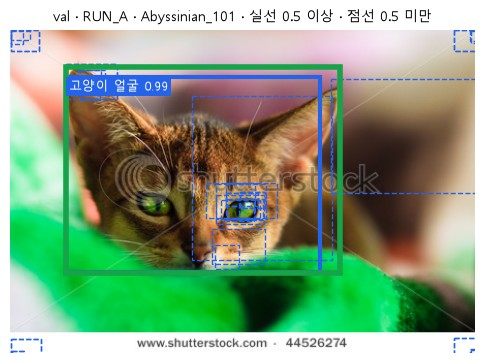

split=val · RUN_A epoch 4 · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    5 FN   4 | 정밀도 0.972 재현율 0.977 F1 0.975
  개 얼굴    GT 375 | TP 367 FP   12 FN   8 | 정밀도 0.968 재현율 0.979 F1 0.973
  두 클래스 합 GT 551 | TP 539 FP   17 FN  12 | 정밀도 0.969 재현율 0.978 F1 0.974


In [62]:
# ---------- 7-1 ----------
# 왜 · 모든 채점이 같은 val 사진 순서를 쓰게 하기 위해
VAL_IDS = sorted(val_ds.ids)                                      # val 551장 · 이름 순
# 모델 안
SETTINGS_A = {k: getattr(model_A, k) for k in ("score_thresh", "nms_thresh", "detections_per_img")}
A_EPOCH = ckpt["epoch"]                                           # best epoch
print("채점할 사진: val", len(VAL_IDS), "장 · test는 쓰지 않음")  # val만
print(f"모델: RUN_A best = epoch {A_EPOCH} (val로 고름) · 모델 안 설정:", SETTINGS_A)  # 조건

# 왜 · val 전체 예측을 한 번 모아 여러 채점에 다시 쓰기 위해
preds_A_val = predict_all(model_A, VAL_IDS)             # 한 번만 계산 → 8 · 9장에서 다시 씀
n_gt = sum(len(r["gt_boxes"]) for r in preds_A_val)     # 정답 수
scores = [s for r in preds_A_val for s in r["scores"]]  # 모든 예측 점수
print("정답 박스:", n_gt, "개")                         # 551
print("예측 박스:", len(scores), "개 = 점수 0.5 이상", sum(s >= 0.5 for s in scores),  # 0.5 위아래
      "+ 0.5 미만", sum(s < 0.5 for s in scores))

# 왜 · 사진 한 장의 기록에 무엇이 들어 있는지 직접 보기 위해
stem = next(r["id"] for r in preds_A_val if len(r["boxes"]) >= 3)  # 예측 3개 이상인 첫 사진
r = {p["id"]: p for p in preds_A_val}[stem]                                      # 그 기록
gt_show = [[round(v) for v in b] for b in r["gt_boxes"]]                         # 정답 박스
print(stem, "· 정답:", [CLASSES[lb] for lb in r["gt_labels"]], gt_show)          # 정답
for b, lb, s in zip(r["boxes"][:4], r["labels"][:4], r["scores"][:4]):           # 앞 4개
    print(f"  예측 {CLASSES[lb]:6s} 점수 {s:.3f} 박스 {[round(v) for v in b]}")  # 한 줄
hi = [i for i, s in enumerate(r["scores"]) if s >= 0.5]                          # 0.5 이상
lo = [i for i, s in enumerate(r["scores"]) if s < 0.5]                           # 0.5 미만
names_hi = [f"{CLASSES[r['labels'][i]]} {r['scores'][i]:.2f}" for i in hi]       # 이름표
draw(load_image(stem), gt=r["gt_boxes"], pred=[r["boxes"][i] for i in hi],       # 실선 · 점선
     cand=[r["boxes"][i] for i in lo], labels=names_hi,
     title=f"val · RUN_A · {stem} · 실선 0.5 이상 · 점선 0.5 미만")
plt.show()                                                                       # 그림 출력


# ---------- 7-2 ----------
# 왜 · 점수 기준 · IoU 기준을 바꿔 가며 TP · FP · FN을 세기 위해
def match(records, score_thr, iou_thr):  # 점수 기준 이상만 채점 → 클래스별 개수
    counts = {}                                                                      # 결과
    for cls in (1, 2):                                                               # 두 클래스
        rows, n_gt = judge(records, cls, iou_thr, score_min=score_thr)               # 판정
        tp = sum(ok for _, ok, *_ in rows)                                           # TP
        counts[cls] = {"TP": tp, "FP": len(rows) - tp, "FN": n_gt - tp, "GT": n_gt}  # 네 숫자
    return counts                                                                    # 클래스별


# 왜 · 클래스별 채점 결과를 같은 형식으로 출력하기 위해
def show(counts, title):                                                # 클래스별 · 합계 한 줄씩
    print(title)                                                        # 조건
    both = {k: counts[1][k] + counts[2][k] for k in ("TP", "FP", "FN", "GT")}  # 합계
    # 세 줄
    for name, c in [(CLASSES[1], counts[1]), (CLASSES[2], counts[2]), ("두 클래스 합", both)]:
        p, r_ = c["TP"] / max(c["TP"] + c["FP"], 1), c["TP"] / c["GT"]  # 정밀도 · 재현율
        f1 = 2 * p * r_ / (p + r_) if p + r_ else 0.0                   # F1
        # 한 줄
        print(f"  {name:7s} GT {c['GT']:3d} | TP {c['TP']:3d} FP {c['FP']:4d} FN {c['FN']:3d}"
              f" | 정밀도 {p:.3f} 재현율 {r_:.3f} F1 {f1:.3f}")


# 왜 · 실제로 쓸 기준 0.5에서 RUN_A 성능을 먼저 보기 위해
show(match(preds_A_val, score_thr=0.5, iou_thr=0.5),  # Day01과 같은 기준
     f"split=val · RUN_A epoch {A_EPOCH} · 점수 기준 0.5 · 평가 IoU 0.5")

**실행 흐름**

1. 7-3 학습 전 COCO와 비교
2. 7-4 점수 기준 바꾸기

COCO 번호 → 우리 번호: {17: 1, 18: 2}


split=val · COCO SSD (학습 전) · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP  18 FP  156 FN 158 | 정밀도 0.103 재현율 0.102 F1 0.103
  개 얼굴    GT 375 | TP  57 FP  305 FN 318 | 정밀도 0.157 재현율 0.152 F1 0.155
  두 클래스 합 GT 551 | TP  75 FP  461 FN 476 | 정밀도 0.140 재현율 0.136 F1 0.138


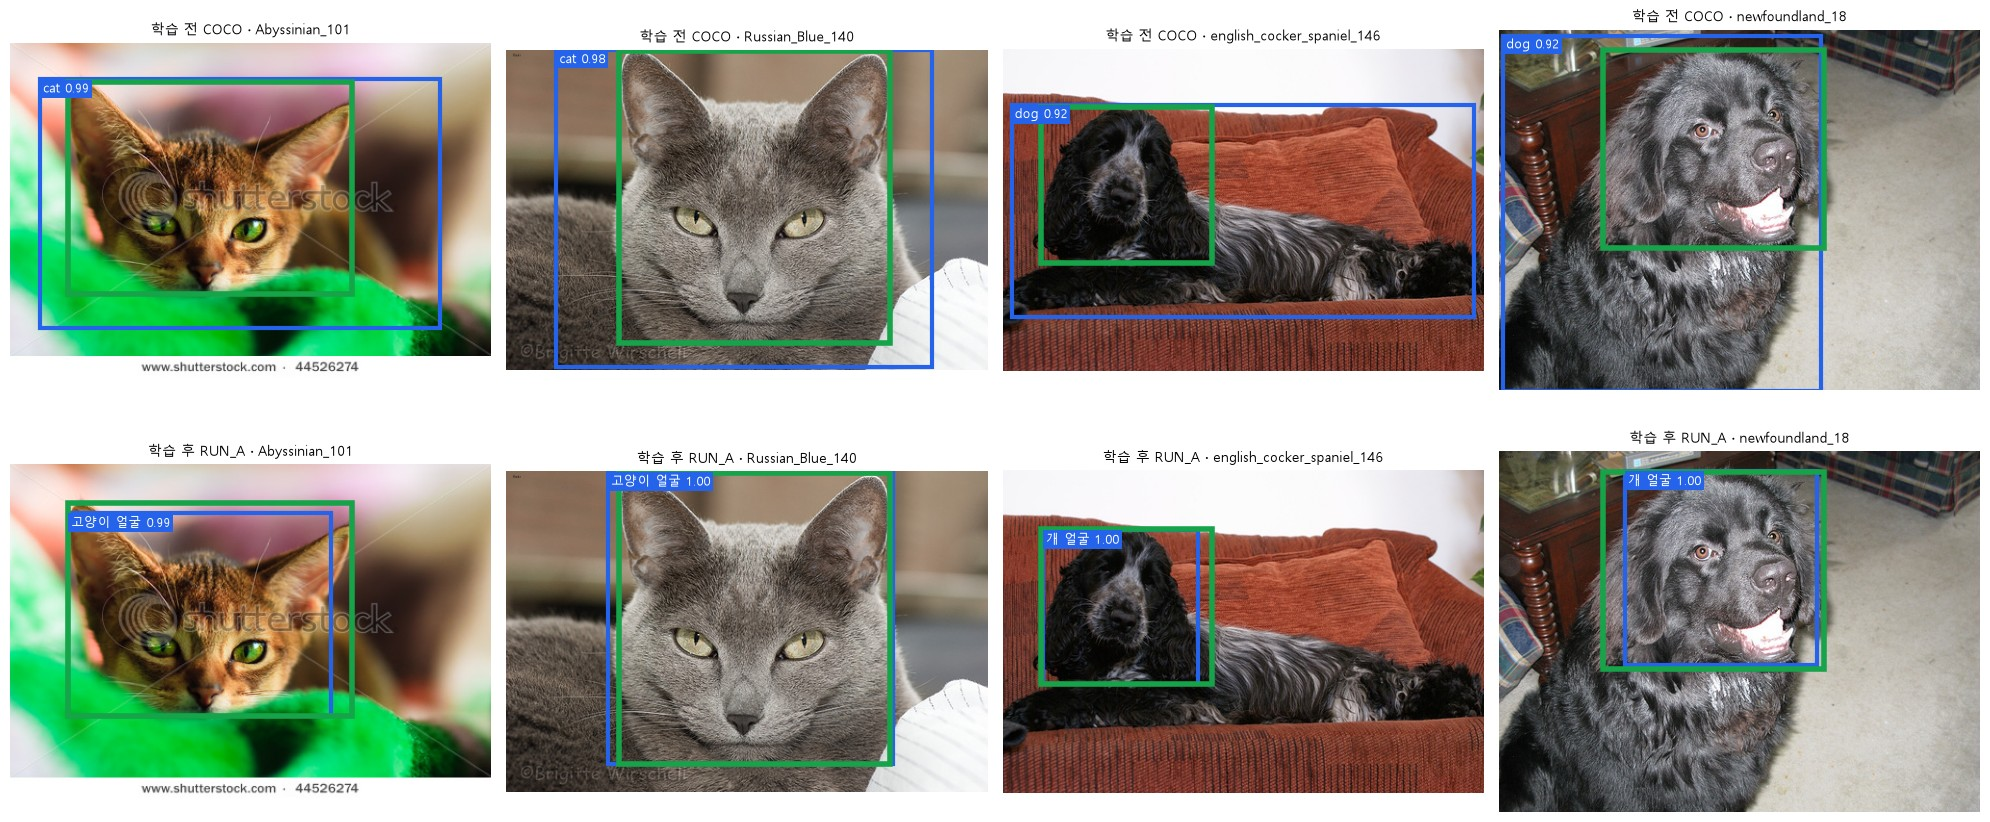

split=val · RUN_A · 점수 기준 0.3 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    6 FN   4 | 정밀도 0.966 재현율 0.977 F1 0.972
  개 얼굴    GT 375 | TP 371 FP   21 FN   4 | 정밀도 0.946 재현율 0.989 F1 0.967
  두 클래스 합 GT 551 | TP 543 FP   27 FN   8 | 정밀도 0.953 재현율 0.985 F1 0.969
split=val · RUN_A · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    5 FN   4 | 정밀도 0.972 재현율 0.977 F1 0.975
  개 얼굴    GT 375 | TP 367 FP   12 FN   8 | 정밀도 0.968 재현율 0.979 F1 0.973
  두 클래스 합 GT 551 | TP 539 FP   17 FN  12 | 정밀도 0.969 재현율 0.978 F1 0.974
split=val · RUN_A · 점수 기준 0.7 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 170 FP    2 FN   6 | 정밀도 0.988 재현율 0.966 F1 0.977
  개 얼굴    GT 375 | TP 362 FP    8 FN  13 | 정밀도 0.978 재현율 0.965 F1 0.972
  두 클래스 합 GT 551 | TP 532 FP   10 FN  19 | 정밀도 0.982 재현율 0.966 F1 0.973
F1 가장 높은 점수 기준: 0.5 (F1 0.9738)
점수 기준 0.5 ~ 0.9의 F1: 0.9638 ~ 0.9738


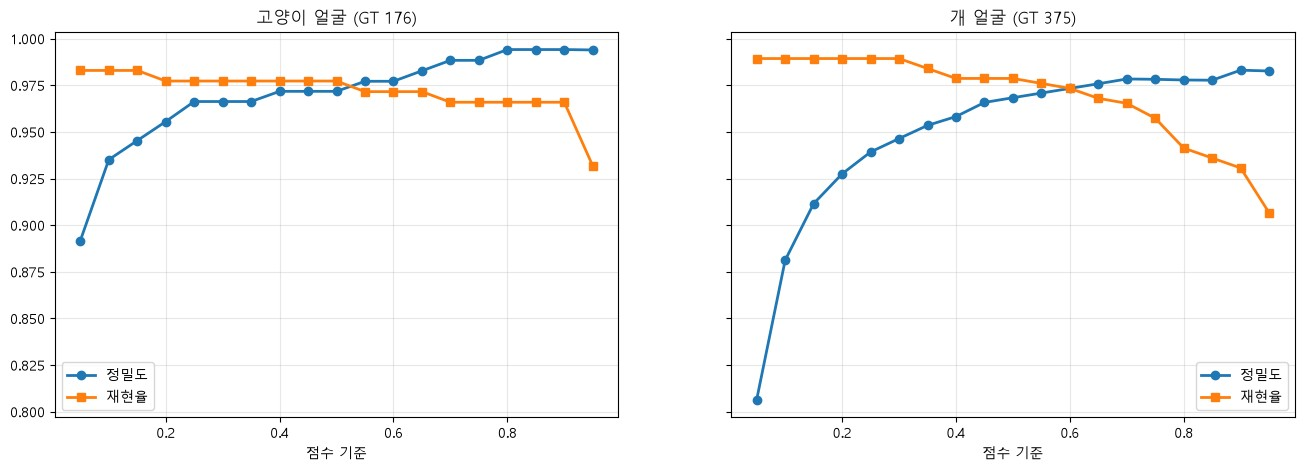

COCO (학습 전) · 점수 기준 0.5  | TP  75 · FP   461 · 재현율 0.136 · 정밀도 0.140
COCO (학습 전) · 점수 기준 0.3  | TP  81 · FP   476 · 재현율 0.147 · 정밀도 0.145
COCO (학습 전) · 점수 기준 0.1  | TP 101 · FP   572 · 재현율 0.183 · 정밀도 0.150
COCO (학습 전) · 점수 기준 0.01 | TP 436 · FP  7520 · 재현율 0.791 · 정밀도 0.055


In [63]:
# ---------- 7-3 ----------
# 왜 · 학습 효과를 재려면 학습 전 기준선이 필요하기 때문에
coco_ssd = ssd300_vgg16(weights=SSD_W).eval().to(DEVICE)                 # 우리 데이터로 학습하기 전
COCO_TO_OURS = {COCO_NAMES.index("cat"): 1, COCO_NAMES.index("dog"): 2}  # 나머지 COCO 클래스는 버림
print("COCO 번호 → 우리 번호:", COCO_TO_OURS)                            # 17 → 1 · 18 → 2
preds_coco_val = predict_all(coco_ssd, VAL_IDS, label_map=COCO_TO_OURS)  # 한 번만
show(match(preds_coco_val, score_thr=0.5, iou_thr=0.5),                  # 같은 기준
     "split=val · COCO SSD (학습 전) · 점수 기준 0.5 · 평가 IoU 0.5")

# 왜 · 같은 val 사진에서 학습 전 · 후 예측을 눈으로 비교하기 위해
picks = VAL_IDS[::138][:4]                       # 138장 간격 4장 (결과 보고 고르지 않음)
fig, axes = plt.subplots(2, 4, figsize=(20, 9))  # 위 = 학습 전 · 아래 = 학습 후
# 두 모델
for row, (name, recs, names) in enumerate([("학습 전 COCO", preds_coco_val, ["", "cat", "dog"]),
                                           ("학습 후 RUN_A", preds_A_val, CLASSES)]):
    by_id = {p["id"]: p for p in recs}           # 이름으로 찾기
    for ax, s in zip(axes[row], picks):          # 사진마다
        r = by_id[s]                             # 기록
        keep = [i for i, v in enumerate(r["scores"]) if v >= 0.5]  # 0.5 이상
        labs = [f"{names[r['labels'][i]]} {r['scores'][i]:.2f}" for i in keep]  # 이름표
        # 정답 · 예측
        draw(load_image(s), gt=r["gt_boxes"], pred=[r["boxes"][i] for i in keep], ax=ax,
             labels=labs, title=f"{name} · {s}")
plt.tight_layout()                               # 여백
plt.show()                                       # 그림 출력


# ---------- 7-4 ----------
# 왜 · 점수 기준에 따라 정밀도 · 재현율이 반대로 움직이는 것을 보기 위해
for thr in (0.3, 0.5, 0.7):                               # 점수 기준 세 가지
    show(match(preds_A_val, score_thr=thr, iou_thr=0.5),  # 같은 예측 · 기준만 바꿈
         f"split=val · RUN_A · 점수 기준 {thr} · 평가 IoU 0.5")

# 왜 · F1이 가장 높은 점수 기준을 찾기 위해
thrs = np.round(np.arange(0.05, 1.0, 0.05), 2)                       # 기준 19개
f1s = {}                                                             # 기준마다 F1 (두 클래스 합)
for t in thrs:                                                       # 기준마다
    c = match(preds_A_val, t, 0.5)                                   # 개수
    tp, fp, fn = (c[1][k] + c[2][k] for k in ("TP", "FP", "FN"))     # 합계
    f1s[float(t)] = 2 * tp / (2 * tp + fp + fn)                      # F1
best_t = max(f1s, key=f1s.get)                                       # F1 최고 기준
print("F1 가장 높은 점수 기준:", best_t, f"(F1 {f1s[best_t]:.4f})")  # 운 좋은 자리인가
mid = [f1s[t] for t in f1s if 0.5 <= t <= 0.9]                       # 0.5 ~ 0.9 구간
print("점수 기준 0.5 ~ 0.9의 F1:", f"{min(mid):.4f} ~ {max(f1s.values()):.4f}")  # 평평한가

# 왜 · 클래스별 F1 곡선을 같은 눈금으로 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)                    # 클래스별 곡선
for ax, cls in zip(axes, (1, 2)):                                               # 두 클래스
    cs = [match(preds_A_val, t, 0.5)[cls] for t in thrs]                        # 기준마다
    # 정밀도
    ax.plot(thrs, [c["TP"] / max(c["TP"] + c["FP"], 1) for c in cs], "o-", lw=2, label="정밀도")
    ax.plot(thrs, [c["TP"] / c["GT"] for c in cs], "s-", lw=2, label="재현율")  # 재현율
    ax.set_title(f"{CLASSES[cls]} (GT {cs[0]['GT']})", fontsize=12)             # 제목
    ax.set_xlabel("점수 기준")                                                  # x축
    ax.grid(alpha=0.3)                                                          # 격자
    ax.legend()                                                                 # 범례
plt.show()                                                                      # 그림 출력

# 왜 · 학습 전 COCO 모델도 기준을 낮추면 찾는 얼굴이 늘어나는지 보기 위해
for thr in (0.5, 0.3, 0.1, 0.01):                              # 학습 전 모델은 기준을 내리면 될까
    c = match(preds_coco_val, thr, 0.5)                        # 개수
    tp, fp = c[1]["TP"] + c[2]["TP"], c[1]["FP"] + c[2]["FP"]  # 합계
    # 한 줄
    print(f"COCO (학습 전) · 점수 기준 {thr:<4} | TP {tp:3d} · FP {fp:5d} · 재현율 {tp / n_gt:.3f}"
          f" · 정밀도 {tp / (tp + fp):.3f}")

**실행 흐름**

1. 7-5 평가 IoU 기준 바꾸기

In [64]:
# ---------- 7-5 ----------
# 왜 · 평가 IoU 기준을 바꾸면 두 모델의 판정이 어떻게 바뀌는지 비교하기 위해
MODELS = [(f"RUN_A epoch {A_EPOCH}", preds_A_val), ("COCO (학습 전)", preds_coco_val)]  # 두 모델
for name, recs in MODELS:                            # 모델마다
    for t in (0.5, 0.7):                             # 평가 IoU 두 가지
        show(match(recs, score_thr=0.5, iou_thr=t),  # 표
             f"split=val · {name} · 점수 기준 0.5 · 평가 IoU {t}")

split=val · RUN_A epoch 4 · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP 172 FP    5 FN   4 | 정밀도 0.972 재현율 0.977 F1 0.975
  개 얼굴    GT 375 | TP 367 FP   12 FN   8 | 정밀도 0.968 재현율 0.979 F1 0.973
  두 클래스 합 GT 551 | TP 539 FP   17 FN  12 | 정밀도 0.969 재현율 0.978 F1 0.974
split=val · RUN_A epoch 4 · 점수 기준 0.5 · 평가 IoU 0.7
  고양이 얼굴  GT 176 | TP 171 FP    6 FN   5 | 정밀도 0.966 재현율 0.972 F1 0.969
  개 얼굴    GT 375 | TP 352 FP   27 FN  23 | 정밀도 0.929 재현율 0.939 F1 0.934
  두 클래스 합 GT 551 | TP 523 FP   33 FN  28 | 정밀도 0.941 재현율 0.949 F1 0.945
split=val · COCO (학습 전) · 점수 기준 0.5 · 평가 IoU 0.5
  고양이 얼굴  GT 176 | TP  18 FP  156 FN 158 | 정밀도 0.103 재현율 0.102 F1 0.103
  개 얼굴    GT 375 | TP  57 FP  305 FN 318 | 정밀도 0.157 재현율 0.152 F1 0.155
  두 클래스 합 GT 551 | TP  75 FP  461 FN 476 | 정밀도 0.140 재현율 0.136 F1 0.138
split=val · COCO (학습 전) · 점수 기준 0.5 · 평가 IoU 0.7
  고양이 얼굴  GT 176 | TP   3 FP  171 FN 173 | 정밀도 0.017 재현율 0.017 F1 0.017
  개 얼굴    GT 375 | TP   9 FP  353 FN 366 | 정밀도 0.025 재현율 0.024 F1 0.024
  두 클래스 

**실행 흐름**

1. 8-1 AP · PR 곡선
2. 8-2 IoU 기준별 AP

장난감 고양이 AP: 0.8333 (그림: 0.5 × 1.0 + 0.5 × 0.67 ≈ 0.83)


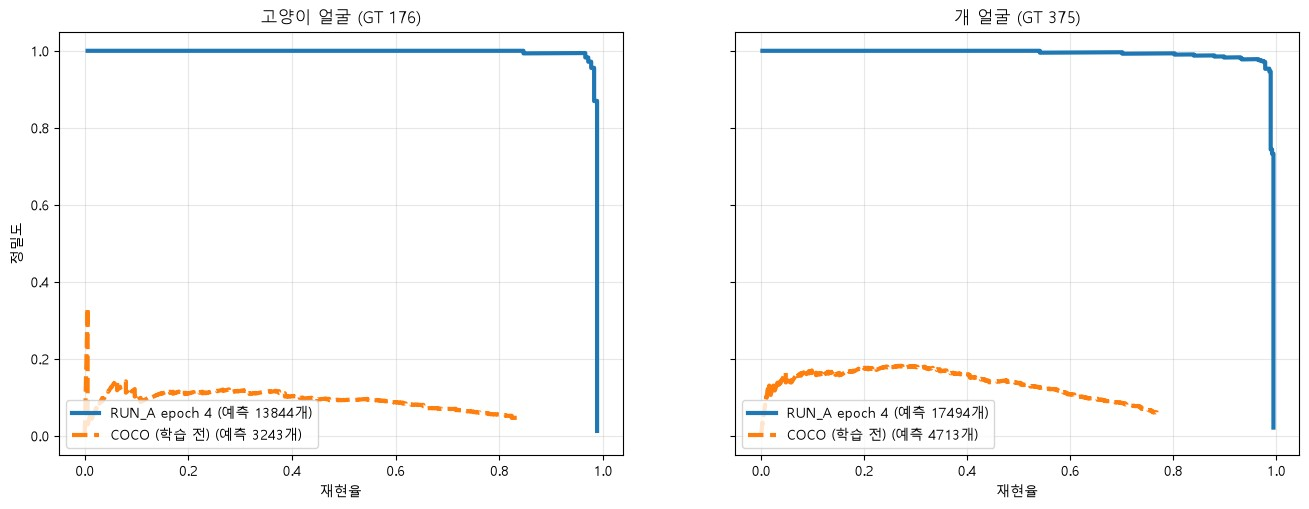

RUN_A epoch 4  | 고양이 얼굴 AP50 0.9867 (GT 176) · 개 얼굴 AP50 0.9887 (GT 375) | mAP50 0.9877
COCO (학습 전)    | 고양이 얼굴 AP50 0.0859 (GT 176) · 개 얼굴 AP50 0.1132 (GT 375) | mAP50 0.0996
6장 best를 고를 때 기록된 mAP50 0.987718 · 지금 계산 0.987718


In [65]:
# ---------- 8-1 ----------
# 왜 · 작은 예로 AP 계산이 맞는지 손으로 검산하기 위해
a_, off = [0, 0, 10, 10], [20, 20, 30, 30]                               # 수업 그림의 장난감 예
toy = [{"id": "toy", "gt_boxes": [a_, off, a_], "gt_labels": [1, 1, 2],  # 고양이 정답 2개 · 개 1개
        "boxes": [a_, a_, off, a_], "labels": [1, 1, 1, 2], "scores": [0.9, 0.8, 0.7, 0.6]}]
print("장난감 고양이 AP:", round(ap_per_class(toy)[1]["AP"], 4),         # 손계산과 비교
      "(그림: 0.5 × 1.0 + 0.5 × 0.67 ≈ 0.83)")

# 왜 · 클래스별 PR 곡선을 같은 눈금으로 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)               # PR 곡선
for ax, cls in zip(axes, (1, 2)):                                            # 두 클래스
    for (name, recs), style in zip(MODELS, ("-", "--")):                     # 두 모델
        rows, n_gt_c = judge(recs, cls, 0.5)                                 # 판정
        tp = np.cumsum([ok for _, ok, *_ in rows])                           # 누적 TP
        ax.plot(tp / n_gt_c, tp / np.arange(1, len(rows) + 1), style, lw=3,  # 곡선
                label=f"{name} (예측 {len(rows)}개)")
    ax.set_title(f"{CLASSES[cls]} (GT {n_gt_c})", fontsize=12)               # 제목
    ax.set_xlabel("재현율")                                                  # x축
    ax.grid(alpha=0.3)                                                       # 격자
    ax.legend(loc="lower left")                                              # 범례
axes[0].set_ylabel("정밀도")                                                 # y축
plt.show()                                                                   # 그림 출력

for name, recs in MODELS:                                                              # 두 모델
    res = ap_per_class(recs, 0.5)                                                      # AP50
    print(f"{name:14s} | 고양이 얼굴 AP50 {res[1]['AP']:.4f} (GT {res[1]['GT']}) ·"    # 클래스별
          f" 개 얼굴 AP50 {res[2]['AP']:.4f} (GT {res[2]['GT']}) | mAP50 {res['mAP']:.4f}")
now = ap_per_class(preds_A_val)["mAP"]                                                 # 지금 계산
print(f"6장 best를 고를 때 기록된 mAP50 {best_A['mAP50']:.6f} · 지금 계산 {now:.6f}")  # 같은 값


# ---------- 8-2 ----------
# 왜 · COCO처럼 IoU 0.50 ~ 0.95 열 기준의 AP를 구하기 위해
IOU_THRS = np.round(np.arange(0.50, 0.96, 0.05), 2)  # 0.50 ~ 0.95 (10개)


# 왜 · AP50 · AP75 · 열 기준 평균을 한 번에 요약하기 위해
def ab_summary(records):  # AP50 · AP75 · 0.50~0.95 평균 (두 클래스 평균) · 클래스별 곡선
    cur = {float(t): ap_per_class(records, t) for t in IOU_THRS}  # 기준마다
    m = {t: v["mAP"] for t, v in cur.items()}                     # 평균 AP
    cat = {t: v[1]["AP"] for t, v in cur.items()}                 # 고양이 곡선
    dog = {t: v[2]["AP"] for t, v in cur.items()}                 # 개 곡선
    # 세 숫자
    return {"AP50": m[0.5], "AP75": m[0.75], "AP50_95": sum(m.values()) / len(m), "curve": m,
            "cat": cat, "dog": dog}

**실행 흐름**

1. 8-2 두 모델의 기준별 AP
2. 8-3 맞힌 박스의 평균 IoU

RUN_A epoch 4 · split=val · 점수 0.01 이상 · 우리 평가 함수 (공식 COCO 평가기 아님)
  고양이 얼굴   AP50 0.987 · AP75 0.963 · IoU 0.50~0.95 평균 AP 0.809
  개 얼굴     AP50 0.989 · AP75 0.901 · IoU 0.50~0.95 평균 AP 0.735
  두 클래스 평균 AP50 0.988 · AP75 0.932 · IoU 0.50~0.95 평균 AP 0.772
COCO (학습 전) · split=val · 점수 0.01 이상 · 우리 평가 함수 (공식 COCO 평가기 아님)
  고양이 얼굴   AP50 0.086 · AP75 0.006 · IoU 0.50~0.95 평균 AP 0.025
  개 얼굴     AP50 0.113 · AP75 0.004 · IoU 0.50~0.95 평균 AP 0.031
  두 클래스 평균 AP50 0.100 · AP75 0.005 · IoU 0.50~0.95 평균 AP 0.028


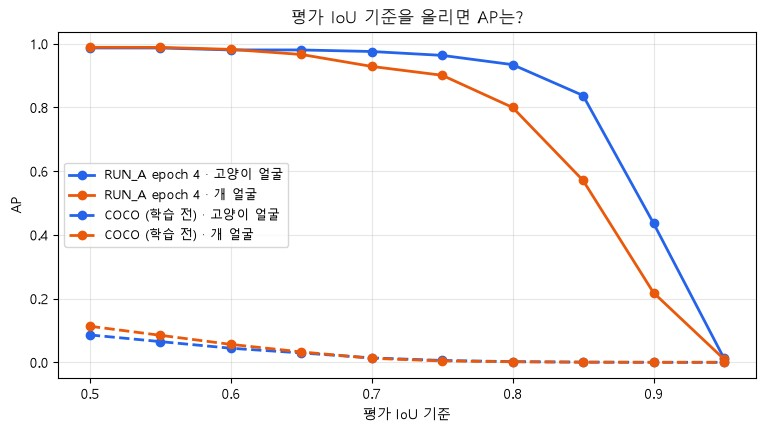

RUN_A epoch 4  | 고양이 얼굴 맞힌 172/176개의 평균 IoU 0.903 | 개 얼굴 맞힌 367/375개의 평균 IoU 0.870
COCO (학습 전)    | 고양이 얼굴 맞힌 18/176개의 평균 IoU 0.608 | 개 얼굴 맞힌 57/375개의 평균 IoU 0.623
맞힌 539개 중 IoU 0.75 미만: 26개
맞힌 539개 중 IoU 0.95 미만: 492개


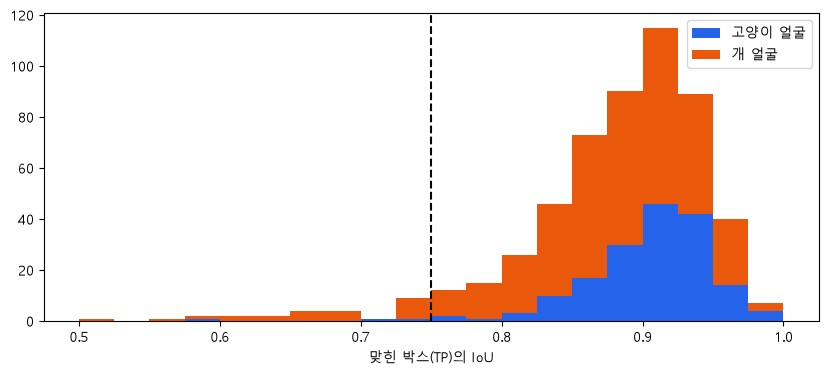

In [66]:
# 왜 · 두 모델의 기준별 AP를 나란히 비교하기 위해
sums = {name: ab_summary(recs) for name, recs in MODELS}                     # 두 모델
for name, s in sums.items():                                                 # 모델마다
    print(f"{name} · split=val · 점수 0.01 이상 · 우리 평가 함수 (공식 COCO 평가기 아님)")  # 조건
    for key, label in [("cat", CLASSES[1]), ("dog", CLASSES[2])]:            # 클래스별
        v = s[key]                                                           # 기준마다 AP
        print(f"  {label:8s} AP50 {v[0.5]:.3f} · AP75 {v[0.75]:.3f} ·"       # 세 숫자
              f" IoU 0.50~0.95 평균 AP {np.mean(list(v.values())):.3f}")
    print(f"  두 클래스 평균 AP50 {s['AP50']:.3f} · AP75 {s['AP75']:.3f} ·"  # 평균
          f" IoU 0.50~0.95 평균 AP {s['AP50_95']:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))                                    # 기준별 AP
for name, s in sums.items():                                                # 두 모델
    for key, color in [("cat", "#2563eb"), ("dog", "#ea580c")]:             # 두 클래스
        style = ("-" if "RUN" in name else "--") + "o"                      # 실선 = 학습 후
        ax.plot(IOU_THRS, list(s[key].values()), style, color=color, lw=2,  # 기준별 AP
                label=f"{name} · {CLASSES[1 if key == 'cat' else 2]}")
ax.set_xlabel("평가 IoU 기준")                                              # x축
ax.set_ylabel("AP")                                                         # y축
ax.set_title("평가 IoU 기준을 올리면 AP는?", fontsize=12)                   # 제목
ax.grid(alpha=0.3)                                                          # 격자
ax.legend(fontsize=9)                                                       # 범례
plt.show()                                                                  # 그림 출력


# ---------- 8-3 ----------
# 왜 · 맞힌 박스가 정답에 얼마나 딱 맞는지 따로 재기 위해
def mission_iou(records, score_thr=0.5, iou_thr=0.5):  # TP가 된 예측만 모아 IoU 평균
    out = {}                                           # 결과
    for cls in (1, 2):                                 # 두 클래스
        rows, n_gt_c = judge(records, cls, iou_thr, score_min=score_thr)  # 판정
        ious = [v for _, ok, v, *_ in rows if ok]      # TP의 IoU
        # 평균
        out[cls] = {"평균 IoU": float(np.mean(ious)) if ious else float("nan"), "TP": len(ious),
                    "GT": n_gt_c, "ious": ious}
    return out                                         # FP · FN은 평균에 안 들어감


for name, recs in MODELS:                        # 두 모델
    m = mission_iou(recs)                        # 평균 IoU
    # 클래스별
    parts = [f"{CLASSES[c]} 맞힌 {m[c]['TP']}/{m[c]['GT']}개의 평균 IoU {m[c]['평균 IoU']:.3f}"
             for c in (1, 2)]
    print(f"{name:14s} | " + " | ".join(parts))  # 한 줄

# 왜 · AP75가 낮은 이유를 맞힌 박스의 IoU 분포로 확인하기 위해
m = mission_iou(preds_A_val)              # RUN_A
all_ious = m[1]["ious"] + m[2]["ious"]    # TP 전부
for t in (0.75, 0.95):                    # 두 기준
    # AP75가 낮은 이유
    print(f"맞힌 {len(all_ious)}개 중 IoU {t} 미만: {sum(v < t for v in all_ious)}개")
fig, ax = plt.subplots(figsize=(10, 4))   # 분포
# 쌓은 히스토그램
ax.hist([m[1]["ious"], m[2]["ious"]], bins=np.arange(0.5, 1.001, 0.025), stacked=True,
        color=["#2563eb", "#ea580c"], label=[CLASSES[1], CLASSES[2]])
ax.axvline(0.75, color="black", ls="--")  # 0.75 기준
ax.set_xlabel("맞힌 박스(TP)의 IoU")      # x축
ax.legend()                               # 범례
plt.show()                                # 그림 출력

**실행 흐름**

1. 9-1 판정 목록 · 갤러리 도구

In [67]:
# ---------- 9-1 ----------
# 왜 · 박스마다 TP · FP · FN 판정을 남겨 오류를 유형별로 세기 위해
def err_events(records, score_thr=0.5, iou_thr=0.5):  # 모든 사진 · 두 클래스의 판정 목록
    events = []                                                               # 결과
    for r in records:                                                         # 사진마다
        gt_all = torch.tensor(r["gt_boxes"]).reshape(-1, 4)                   # 클래스 상관없는 정답
        for c in (1, 2):                                                      # 클래스마다
            gts = [b for b, lb in zip(r["gt_boxes"], r["gt_labels"]) if lb == c]  # 같은 클래스 정답
            # 점수 순
            preds = sorted([(s, b) for b, lb, s in zip(r["boxes"], r["labels"], r["scores"])
                            if lb == c and s >= score_thr], key=lambda q: -q[0])
            used = set()                                                      # 짝 생긴 정답
            for s, b in preds:                                                # 예측마다
                # IoU
                ious = box_iou(torch.tensor([b]), torch.tensor(gts).reshape(-1, 4))[0].tolist()
                free = [(v, k) for k, v in enumerate(ious) if k not in used]  # 짝 없는 정답
                best, j = max(free, default=(0.0, None))                      # 가장 많이 겹친 것
                if j is not None and best >= iou_thr:                         # TP
                    used.add(j)                                               # 짝
                    # 기록
                    events.append({"kind": "TP", "score": s, "iou": best, "id": r["id"], "cls": c})
                    continue                                                  # 다음
                e = {"kind": "FP", "score": s, "iou": 0.0, "id": r["id"],     # FP 기록
                     "cls": c, "near_cls": None}
                if len(gt_all):                                               # 정답이 있으면
                    io = box_iou(torch.tensor([b]), gt_all)[0]                # 클래스 상관없이
                    # 가장 겹친 정답
                    e["iou"], e["near_cls"] = io.max().item(), r["gt_labels"][io.argmax().item()]
                events.append(e)                                              # 기록
            events += [{"kind": "FN", "id": r["id"], "cls": c, "box": g}      # 놓친 정답
                       for k, g in enumerate(gts) if k not in used]
    return events                                                             # 판정 목록


# 왜 · 클래스별 오류 개수를 먼저 확인하기 위해
ev_A = err_events(preds_A_val)                             # RUN_A best · val · 점수 0.5 · IoU 0.5
for c in (1, 2):                                           # 클래스마다
    k = Counter(e["kind"] for e in ev_A if e["cls"] == c)  # 세기
    print(f"{CLASSES[c]}: TP {k['TP']:3d} · FP {k['FP']:2d} · FN {k['FN']:2d}")  # 7장 표와 같은 수


# 왜 · 오류 사진을 같은 형식으로 모아 보기 위해
def err_gallery(ids, records, head, ncol=4):                       # 사진 이름 목록 → 갤러리
    by_id = {r["id"]: r for r in records}                          # 이름으로 찾기
    ids = ids[:8]                                                  # 최대 8장
    nrow = max(1, -(-len(ids) // ncol))                            # 줄 수
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.3 * ncol, 3.9 * nrow), squeeze=False)  # 칸
    for ax in axes.flat:                                           # 빈 칸도
        ax.axis("off")                                             # 눈금 숨김
    for ax, s in zip(axes.flat, ids):                              # 사진마다
        r = by_id[s]                                               # 기록
        keep = [i for i, v in enumerate(r["scores"]) if v >= 0.5]  # 0.5 이상
        labs = [f"{CLASSES[r['labels'][i]]} {r['scores'][i]:.2f}" for i in keep]  # 이름표
        draw(load_image(s), gt=r["gt_boxes"], pred=[r["boxes"][i] for i in keep], ax=ax,  # 그림
             title=s, labels=labs)
    fig.suptitle(head, fontsize=12)                                # 제목
    plt.tight_layout()                                             # 여백
    plt.show()                                                     # 그림 출력

고양이 얼굴: TP 172 · FP  5 · FN  4
개 얼굴: TP 367 · FP 12 · FN  8


**실행 흐름**

1. 9-2 놓침 · 점수 높은 FP · 느슨한 TP
2. 9-3 얼굴 크기 계산

놓친 얼굴: 12 개 · 고양이 4 · 개 8


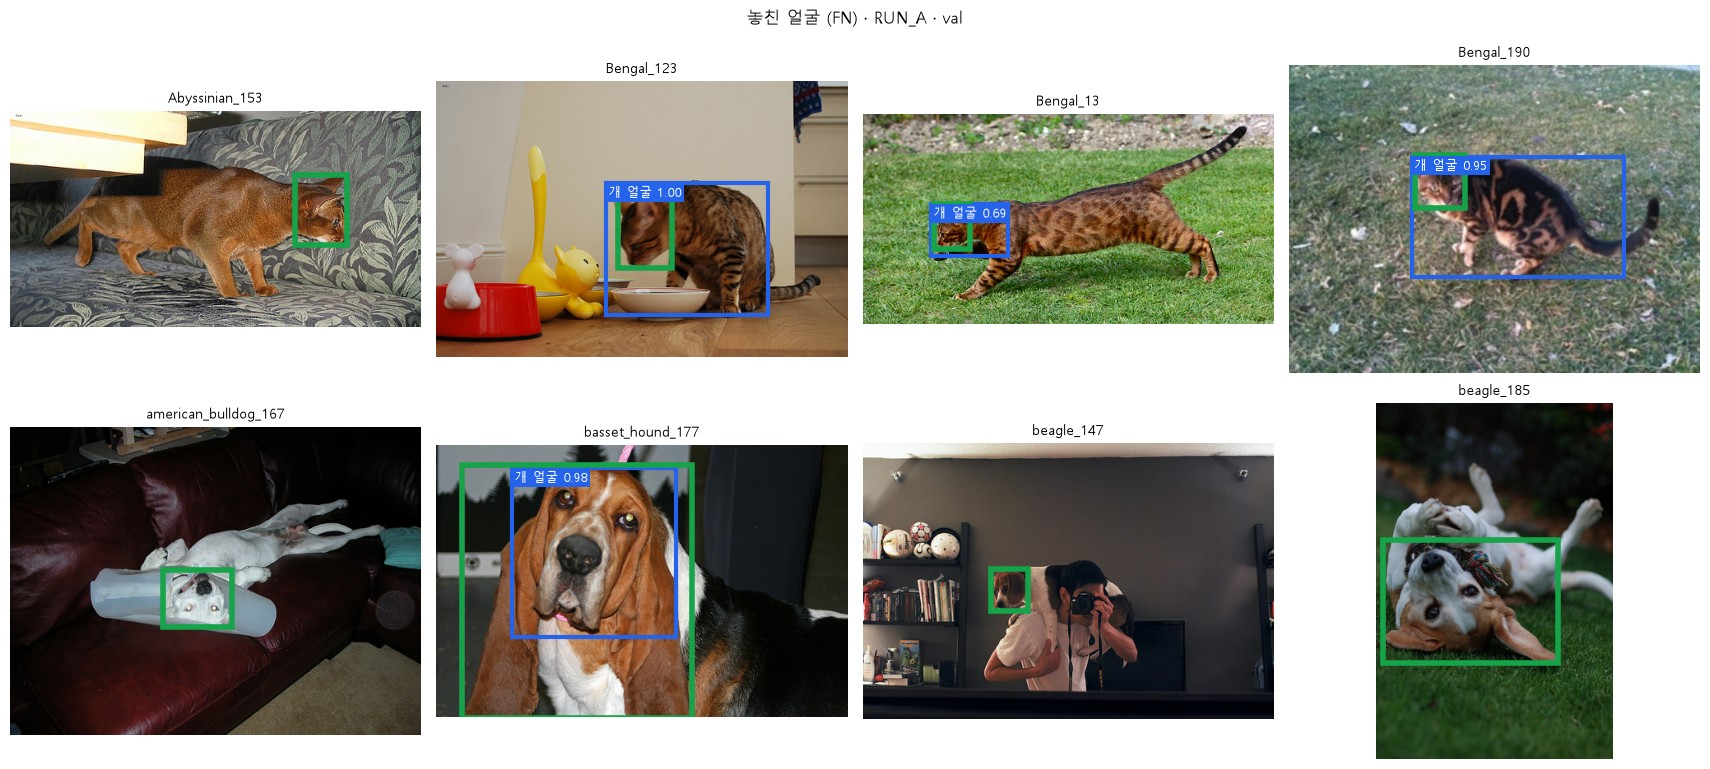

FP 전체 17 개 · 그중 점수 0.85 이상 9 개
  Bengal_123               예측 개 얼굴 1.00 → IoU 0.5 넘게 겹친 정답 없음
  boxer_139                예측 개 얼굴 0.99 → IoU 0.5 넘게 겹친 정답 없음
  miniature_pinscher_16    예측 개 얼굴 0.99 → IoU 0.5 넘게 겹친 정답 없음
  chihuahua_106            예측 고양이 얼굴 0.98 → 정답 개 얼굴 박스와 IoU 0.92
  basset_hound_177         예측 개 얼굴 0.98 → IoU 0.5 넘게 겹친 정답 없음
  saint_bernard_154        예측 개 얼굴 0.97 → IoU 0.5 넘게 겹친 정답 없음
  Bengal_190               예측 개 얼굴 0.95 → IoU 0.5 넘게 겹친 정답 없음
  basset_hound_158         예측 개 얼굴 0.89 → IoU 0.5 넘게 겹친 정답 없음
  wheaten_terrier_162      예측 개 얼굴 0.87 → IoU 0.5 넘게 겹친 정답 없음
놓친 얼굴이 있는 사진 12 장 중 같은 사진에 FP도 있는 사진: 7 장


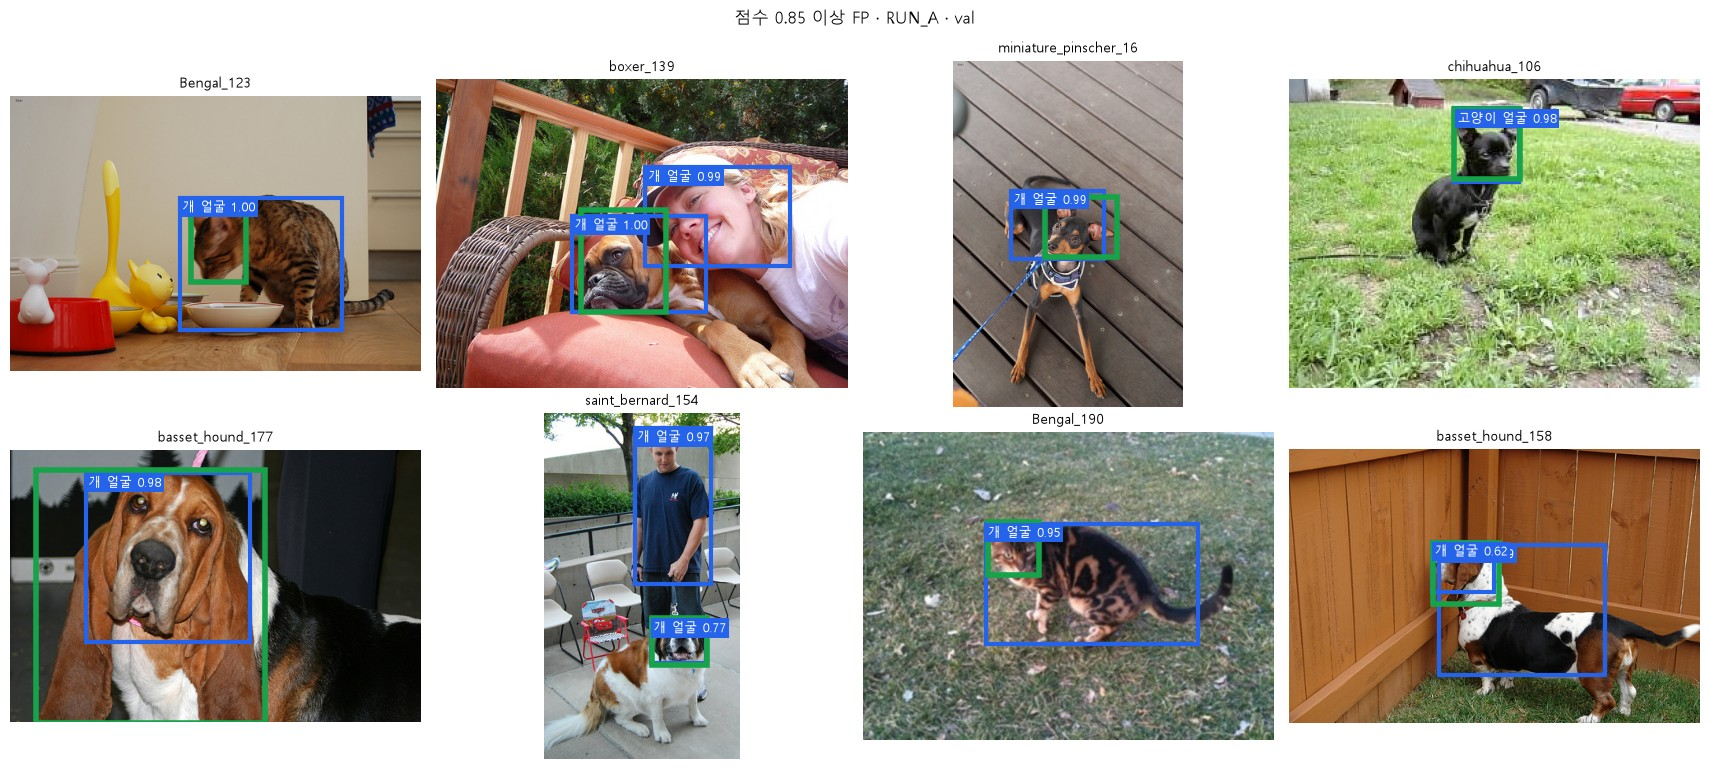

TP 539개 중 IoU 0.75 미만: 26개 (고양이 3 · 개 23)


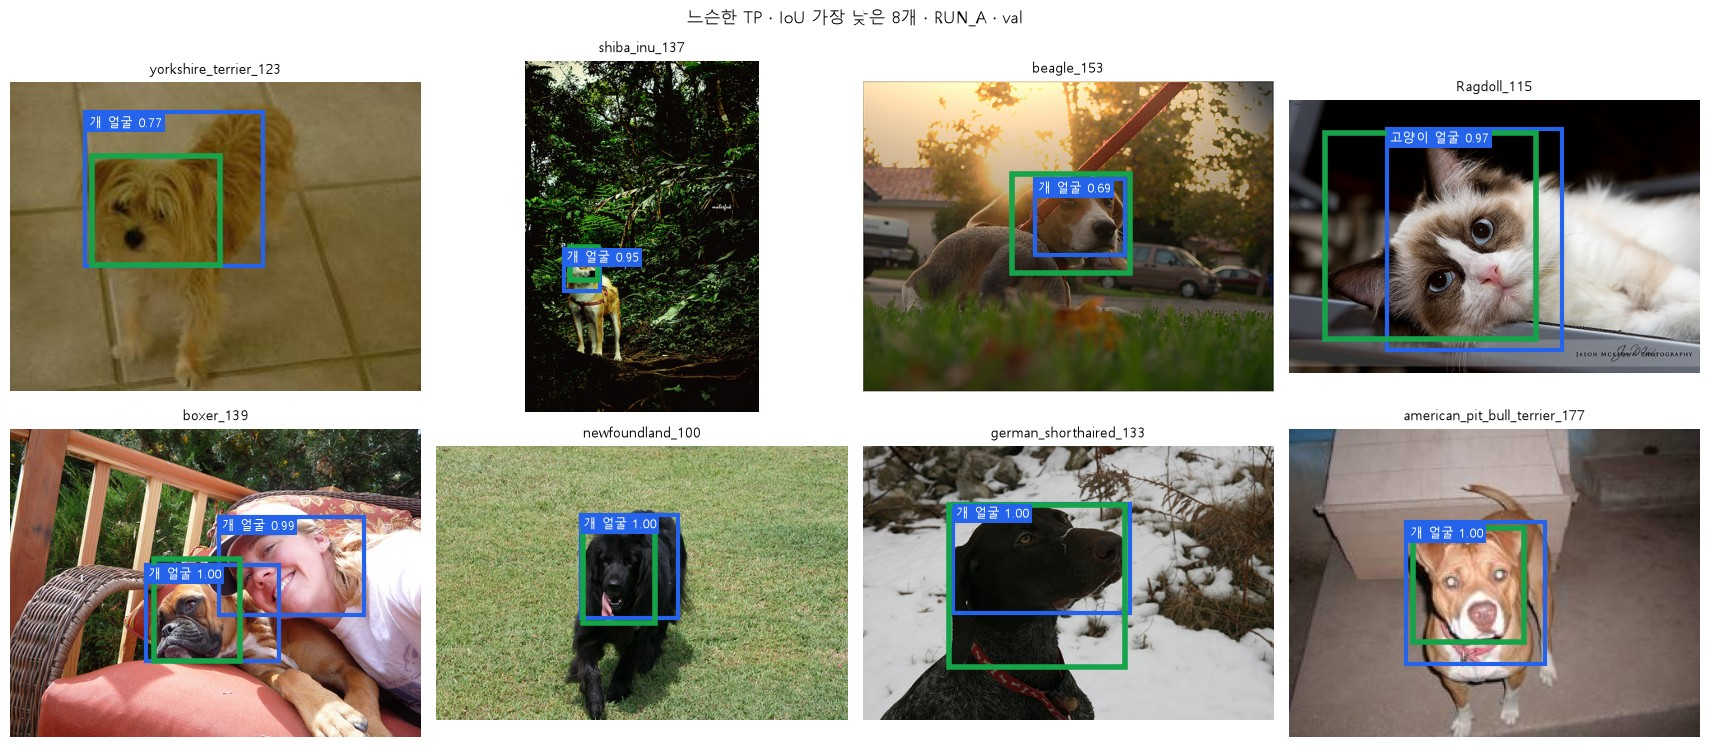

In [68]:
# ---------- 9-2 ----------
# 왜 · 놓친 얼굴을 직접 보고 원인을 찾기 위해
fn_A = [e for e in ev_A if e["kind"] == "FN"]                                            # 놓친 얼굴
print("놓친 얼굴:", len(fn_A), "개 · 고양이", sum(e["cls"] == 1 for e in fn_A), "· 개",  # 클래스별
      sum(e["cls"] == 2 for e in fn_A))
# 사진
err_gallery(list(dict.fromkeys(e["id"] for e in fn_A)), preds_A_val, "놓친 얼굴 (FN) · RUN_A · val")

# 왜 · 점수가 높은데 틀린 예측을 따로 보기 위해
fp_A = sorted([e for e in ev_A if e["kind"] == "FP"], key=lambda e: -e["score"])  # 점수 높은 FP 순
fp_high = [e for e in fp_A if e["score"] >= 0.85]                                 # 확신한 오탐
print("FP 전체", len(fp_A), "개 · 그중 점수 0.85 이상", len(fp_high), "개")       # 개수
for e in fp_high:                                                                 # 하나씩
    # 클래스 혼동?
    near = (f"정답 {CLASSES[e['near_cls']]} 박스와 IoU {e['iou']:.2f}" if e["iou"] >= 0.5
            else "IoU 0.5 넘게 겹친 정답 없음")
    print(f"  {e['id']:24s} 예측 {CLASSES[e['cls']]} {e['score']:.2f} → {near}")  # 한 줄
both = {e["id"] for e in fn_A} & {e["id"] for e in fp_A}  # 놓침 + 오탐이 같은 사진
n_fn_img = len({e["id"] for e in fn_A})  # 놓친 얼굴이 있는 사진 수
# 겹침
print("놓친 얼굴이 있는 사진", n_fn_img, "장 중 같은 사진에 FP도 있는 사진:", len(both), "장")
err_gallery([e["id"] for e in fp_high], preds_A_val, "점수 0.85 이상 FP · RUN_A · val")  # 사진

# 왜 · 맞혔지만 느슨한 박스를 따로 보기 위해
tp_A = [e for e in ev_A if e["kind"] == "TP"]                                   # 맞힌 박스
loose_A = sorted([e for e in tp_A if e["iou"] < 0.75], key=lambda e: e["iou"])  # 느슨한 TP
print(f"TP {len(tp_A)}개 중 IoU 0.75 미만: {len(loose_A)}개"                    # 클래스별
      f" (고양이 {sum(e['cls'] == 1 for e in loose_A)} · 개 {sum(e['cls'] == 2 for e in loose_A)})")
# 사진
err_gallery([e["id"] for e in loose_A], preds_A_val, "느슨한 TP · IoU 가장 낮은 8개 · RUN_A · val")


# ---------- 9-3 ----------
# 왜 · 얼굴 크기를 사진 크기와 함께 계산하기 위해
def err_face_size(stem, box):  # Day01 7-3 정의: 300 기준 긴 변
    size = ET.parse(XMLS / f"{stem}.xml").getroot().find("size")          # 크기
    w, h = float(size.findtext("width")), float(size.findtext("height"))  # 폭 · 높이
    return max((box[2] - box[0]) / w * 300, (box[3] - box[1]) / h * 300)  # 긴 변


# 왜 · 정답 얼굴마다 찾았는지와 크기를 표로 모으기 위해
def err_gt_table(records, score_thr=0.5):                # 정답 얼굴마다 크기 · 최대 IoU
    rows = []                                            # 결과
    for r in records:                                    # 사진마다
        for g, c in zip(r["gt_boxes"], r["gt_labels"]):  # 정답마다
            # 같은 클래스 예측
            same_c = [b for b, lb, s in zip(r["boxes"], r["labels"], r["scores"])
                      if lb == c and s >= score_thr]
            # 최대 IoU
            best = (box_iou(torch.tensor([g]), torch.tensor(same_c).reshape(-1, 4)).max().item()
                    if same_c else 0.0)
            # 기록
            rows.append({"id": r["id"], "cls": c, "size": err_face_size(r["id"], g), "iou": best})
    return rows                                          # 정답 수만큼


# 왜 · 얼굴 크기 구간을 한곳에서 정하기 위해
BINS = [(0, 100, "100 미만"), (100, 200, "100 ~ 200"), (200, 301, "200 이상")]  # 크기 구간

**실행 흐름**

1. 9-3 크기 구간별 놓침

In [69]:
# 왜 · 크기 구간별 놓침 비율을 세기 위해
def err_size_table(rows, cls=None):               # 구간마다 (이름, 수, 0.5로 찾음, 0.75로 찾음)
    out = []                                      # 결과
    for lo, hi, name in BINS:                     # 구간마다
        # 이 구간
        sel = [g for g in rows if lo <= g["size"] < hi and (cls is None or g["cls"] == cls)]
        f50 = sum(g["iou"] >= 0.5 for g in sel)   # 0.5로 찾음
        f75 = sum(g["iou"] >= 0.75 for g in sel)  # 0.75로 찾음
        out.append((name, len(sel), f50, f75))    # 한 줄
    return out                                    # 세 줄


# 왜 · 작은 얼굴에서 더 많이 놓치는지 숫자로 확인하기 위해
gt_A = err_gt_table(preds_A_val)                                                     # RUN_A
# 아주 작은 얼굴
print("정답 얼굴", len(gt_A), "개 · 긴 변 50 미만", sum(g["size"] < 50 for g in gt_A), "개")
for cls, title in [(None, "전체"), (1, "고양이 얼굴"), (2, "개 얼굴")]:              # 세 묶음
    print(f"[{title}]")                                                              # 머리
    for name, n, f50, f75 in err_size_table(gt_A, cls):                              # 구간마다
        print(f"  {name:9s} {n:3d}개 · 0.5로 찾음 {f50 / n:.2f} ({n - f50}개 놓침)"  # 찾은 비율
              f" · 0.75로 찾음 {f75 / n:.2f}")

정답 얼굴 551 개 · 긴 변 50 미만 6 개
[전체]
  100 미만    127개 · 0.5로 찾음 0.92 (10개 놓침) · 0.75로 찾음 0.84
  100 ~ 200 319개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 0.96
  200 이상    105개 · 0.5로 찾음 0.98 (2개 놓침) · 0.75로 찾음 0.94
[고양이 얼굴]
  100 미만     46개 · 0.5로 찾음 0.91 (4개 놓침) · 0.75로 찾음 0.89
  100 ~ 200 101개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 1.00
  200 이상     29개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 0.93
[개 얼굴]
  100 미만     81개 · 0.5로 찾음 0.93 (6개 놓침) · 0.75로 찾음 0.81
  100 ~ 200 218개 · 0.5로 찾음 1.00 (0개 놓침) · 0.75로 찾음 0.94
  200 이상     76개 · 0.5로 찾음 0.97 (2개 놓침) · 0.75로 찾음 0.95


**실행 흐름**

1. 10-1 RUN_B 학습 · 같은 평가
2. 10-2 오류 종류 · 같은 epoch 비교

[RUN_B] epoch 1 · lr 1e-03 · 분류 2.849 · val mAP50 0.9718
[RUN_B] epoch 2 · lr 1e-03 · 분류 1.340 · val mAP50 0.9067
[RUN_B] epoch 3 · lr 1e-03 · 분류 1.071 · val mAP50 0.9881
[RUN_B] epoch 4 · lr 1e-04 · 분류 0.800 · val mAP50 0.9885
RUN_A best: epoch  4 · val mAP50 0.9877 · test 사용 False
RUN_B best: epoch  4 · val mAP50 0.9885 · test 사용 False


RUN_B 예측: 551 장 · 박스 합 43229


val 551장                 RUN_A   RUN_B    B − A
AP50                    0.9877  0.9885  +0.0008
AP75                    0.9322  0.9314  -0.0008
AP 0.50~0.95 평균         0.7725  0.7689  -0.0035


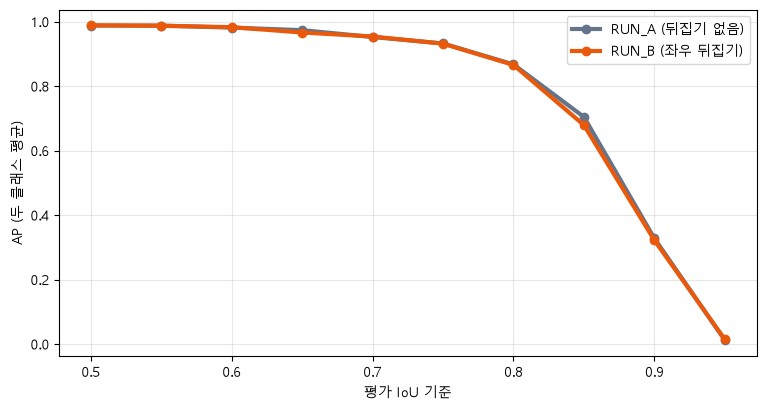

IoU 0.50: 고양이 A 0.987 → B 0.987 · 개 A 0.989 → B 0.990
IoU 0.75: 고양이 A 0.963 → B 0.970 · 개 A 0.901 → B 0.893
IoU 0.90: 고양이 A 0.437 → B 0.447 · 개 A 0.218 → B 0.196


RUN_A: FN 12 · FP 17 · 느슨한 TP 26 · 작은 얼굴 127개 중 0.5로 117 · 0.75로 107
RUN_B: FN 14 · FP 17 · 느슨한 TP 25 · 작은 얼굴 127개 중 0.5로 117 · 0.75로 111
epoch | AP50 A · B      | AP75 A · B      | 0.50~0.95 평균 A · B | 평균 차이 B − A


   1  | 0.9726 · 0.9718 | 0.8389 · 0.8162 |   0.6684 · 0.6432   | -0.0252


   2  | 0.9658 · 0.9067 | 0.8456 · 0.7648 |   0.6776 · 0.6213   | -0.0564


   3  | 0.9789 · 0.9881 | 0.8856 · 0.8706 |   0.7039 · 0.6842   | -0.0197


   4  | 0.9877 · 0.9885 | 0.9322 · 0.9314 |   0.7725 · 0.7689   | -0.0035


In [70]:
# ---------- 10-1 ----------
# 왜 · 뒤집기 하나만 바꾼 RUN_B를 같은 절차로 학습하기 위해
hist_B, steps_B = fit("RUN_B", flip=True)       # 딱 하나만 다름: train 좌우 뒤집기 (p 0.5 · seed 1)
best_B = max(hist_B, key=lambda h: h["mAP50"])  # val로 고른 best
for name, best in (("RUN_A", best_A), ("RUN_B", best_B)):  # 두 학습
    print(f"{name} best: epoch {best['epoch']:2d} · val mAP50 {best['mAP50']:.4f}"  # best
          " · test 사용 False")

# 왜 · RUN_B best를 같은 val로 채점하기 위해
model_B = load_run("RUN_B")                                            # RUN_B best
preds_B_val = predict_all(model_B, VAL_IDS)                            # 같은 val · 같은 순서
# 개수
print("RUN_B 예측:", len(preds_B_val), "장 · 박스 합", sum(len(r["boxes"]) for r in preds_B_val))
sA, sB = ab_summary(preds_A_val), ab_summary(preds_B_val)              # 같은 평가 함수
print(f"{'val 551장':22s} {'RUN_A':>7s} {'RUN_B':>7s} {'B − A':>8s}")  # 표 머리
for key, name in [("AP50", "AP50"), ("AP75", "AP75"), ("AP50_95", "AP 0.50~0.95 평균")]:  # 세 지표
    print(f"{name:22s} {sA[key]:7.4f} {sB[key]:7.4f} {sB[key] - sA[key]:+8.4f}")  # 차이

fig, ax = plt.subplots(figsize=(9, 4.5))                                               # 기준별 AP
# 두 학습
pairs_ab = [("RUN_A (뒤집기 없음)", sA, "#64748b"), ("RUN_B (좌우 뒤집기)", sB, "#ea580c")]
for name, s, color in pairs_ab:                                                        # 학습마다
    ax.plot(IOU_THRS, list(s["curve"].values()), "o-", lw=3, color=color, label=name)  # 두 선
ax.set_xlabel("평가 IoU 기준")                                                         # x축
ax.set_ylabel("AP (두 클래스 평균)")                                                   # y축
ax.legend()                                                                            # 범례
ax.grid(alpha=0.3)                                                                     # 격자
plt.show()                                                                             # 그림 출력
for t in (0.5, 0.75, 0.9):                                                             # 세 기준
    print(f"IoU {t:.2f}: 고양이 A {sA['cat'][t]:.3f} → B {sB['cat'][t]:.3f} ·"         # 클래스별
          f" 개 A {sA['dog'][t]:.3f} → B {sB['dog'][t]:.3f}")


# ---------- 10-2 ----------
# 왜 · 두 RUN의 오류 종류를 같은 방법으로 비교하기 위해
ev_B, gt_B = err_events(preds_B_val), err_gt_table(preds_B_val)                  # 9장 도구 그대로
for name, ev, gt in [("RUN_A", ev_A, gt_A), ("RUN_B", ev_B, gt_B)]:              # 두 학습
    k = Counter(e["kind"] for e in ev)                                           # 세기
    loose = sum(e["kind"] == "TP" and e["iou"] < 0.75 for e in ev)               # 느슨한 TP
    _, n_small, f50, f75 = err_size_table(gt)[0]                                 # 긴 변 100 미만
    print(f"{name}: FN {k['FN']:2d} · FP {k['FP']:2d} · 느슨한 TP {loose:2d} ·"  # 오류 종류
          f" 작은 얼굴 {n_small}개 중 0.5로 {f50} · 0.75로 {f75}")

# 왜 · 같은 epoch끼리 비교해 학습 길이 차이를 없애기 위해
print("epoch | AP50 A · B      | AP75 A · B      |"  # 같은 epoch끼리 비교
      " 0.50~0.95 평균 A · B | 평균 차이 B − A")
for ep in range(1, EPOCHS + 1):                      # epoch마다
    # 저장한 예측
    s = {run: ab_summary(json.loads((RUNS / run / f"val_epoch{ep}_predictions.json").read_text()))
         for run in ("RUN_A", "RUN_B")}
    a, b = s["RUN_A"], s["RUN_B"]                    # 두 학습
    # 한 줄
    print(f"  {ep:2d}  | {a['AP50']:.4f} · {b['AP50']:.4f} | {a['AP75']:.4f} · {b['AP75']:.4f} |"
          f"   {a['AP50_95']:.4f} · {b['AP50_95']:.4f}   | {b['AP50_95'] - a['AP50_95']:+.4f}")

**실행 흐름**

1. 최종 모델 고르기 규칙
2. test 한 번 채점 · 보고

In [71]:
# ---------- 11. 종합 실습 ----------
# 최종 모델 고르는 규칙 (test 보기 전에 정함): 셋 다 높으면 그쪽 · 엇갈리면 0.50~0.95 평균
# 왜 · test 결과를 보고 규칙을 바꾸는 일을 막기 위해
val_scores = {"RUN_A": sA, "RUN_B": sB}                                       # val 점수
keys = ["AP50", "AP75", "AP50_95"]                                            # 세 지표
b_higher = [val_scores["RUN_B"][k] > val_scores["RUN_A"][k] for k in keys]    # B가 높은 지표
if all(b_higher) or not any(b_higher):                                        # 한쪽이 모두 높으면
    final_name = "RUN_B" if all(b_higher) else "RUN_A"                        # 그쪽
    reason = "val 세 지표 모두 높음"                                          # 이유
else:                                                                         # 엇갈리면
    final_name = max(val_scores, key=lambda run: val_scores[run]["AP50_95"])  # 평균 기준
    reason = "엇갈림 → 0.50~0.95 평균"                                        # 이유
final_model = model_B if final_name == "RUN_B" else model_A                   # 고른 모델
preds_final_val = preds_B_val if final_name == "RUN_B" else preds_A_val       # 그 val 예측
print("B가 높은가 (AP50, AP75, 0.50~0.95 평균):", b_higher)                   # 비교
print("최종 모델:", final_name, "·", reason)                                  # 결정

# 왜 · 처음 보는 test에 한 번만 채점하기 위해
preds_final_test = predict_all(final_model, sorted(test))                # ← test를 쓰는 유일한 줄
s_test = ab_summary(preds_final_test)                                    # test 점수
ev_test = err_events(preds_final_test)                                   # 점수 0.5 · IoU 0.5
n_gt_t = Counter(lb for r in preds_final_test for lb in r["gt_labels"])  # 정답 수
# 분모
print(f"test {len(preds_final_test)}장 · 정답 고양이 얼굴 {n_gt_t[1]} · 개 얼굴 {n_gt_t[2]}")


# 왜 · val · test 결과를 같은 형식의 보고로 비교하기 위해
def final_report(s, ev):  # AP 세 가지 + 점수 0.5의 정밀도 · 재현율 · F1 + 맞힌 박스 평균 IoU
    k = Counter(e["kind"] for e in ev)                                             # 세기
    p, r_ = k["TP"] / (k["TP"] + k["FP"]), k["TP"] / (k["TP"] + k["FN"])           # 정밀도 · 재현율
    tp_iou = [e["iou"] for e in ev if e["kind"] == "TP"]                           # TP의 IoU
    return {"AP50": s["AP50"], "AP75": s["AP75"], "0.50~0.95 평균": s["AP50_95"],  # 여덟 칸
            "정밀도 (점수 0.5)": p, "재현율 (점수 0.5)": r_, "F1 (점수 0.5)": 2 * p * r_ / (p + r_),
            "맞힌 박스 평균 IoU": sum(tp_iou) / len(tp_iou),
            "TP · FP · FN": f"{k['TP']} · {k['FP']} · {k['FN']}"}


rep_val = final_report(val_scores[final_name], err_events(preds_final_val))  # val
rep_test = final_report(s_test, ev_test)                      # test
print(f"{final_name} best{'':12s} {'val':>8s} {'test':>8s}")  # 표 머리
for key in rep_val:                                           # 칸마다
    v, t = rep_val[key], rep_test[key]                        # 두 값
    if isinstance(v, float):                                  # 숫자 칸
        print(f"{key:20s} {v:>8.4f} {t:>8.4f}")               # 소수 넷째 자리
    else:                                                     # 글자 칸 (TP · FP · FN)
        print(f"{key:20s} {v:>8s} {t:>8s}")                   # 그대로
for t in (0.5, 0.75):                                         # 두 기준
    # 클래스별
    print(f"test 클래스별 AP (IoU {t}): 고양이 {s_test['cat'][t]:.4f} · 개 {s_test['dog'][t]:.4f}")

B가 높은가 (AP50, AP75, 0.50~0.95 평균): [True, False, False]
최종 모델: RUN_A · 엇갈림 → 0.50~0.95 평균


test 551장 · 정답 고양이 얼굴 177 · 개 얼굴 374
RUN_A best                  val     test
AP50                   0.9877   0.9865
AP75                   0.9322   0.9147
0.50~0.95 평균           0.7725   0.7592
정밀도 (점수 0.5)           0.9694   0.9673
재현율 (점수 0.5)           0.9782   0.9673
F1 (점수 0.5)            0.9738   0.9673
맞힌 박스 평균 IoU           0.8805   0.8768
TP · FP · FN         539 · 17 · 12 533 · 18 · 18
test 클래스별 AP (IoU 0.5): 고양이 0.9916 · 개 0.9814
test 클래스별 AP (IoU 0.75): 고양이 0.9723 · 개 0.8570
